# Phase 3 — Exploratory Data Analysis

Explore observed sales, products, customer purchasing, payments, delivery, and review scores in the local Olist dataset. This notebook uses the audited cleaned outputs and leaves every raw and processed CSV unchanged. All results are descriptive. No SQL Server, star schema, Power BI, forecasting, machine learning, RFM or cohort analysis is implemented.

The independent Phase 2 audit was **APPROVED WITH WARNINGS**. Missing coverage, chronology anomalies, ambiguous geography and unverified timezone provenance require explicit analysis rules. Reusable analysis and chart functions are in `src/analysis/eda.py` and `src/analysis/eda_charts.py`.

Select **E-Commerce Sales BI (.venv)** and run every cell in order. Reports and high-resolution figures are refreshed under `reports/` only.

## 1. Review Context and Load Cleaned Data

Locate the root with pathlib. Verify the audit status and read existing quality flags. Load source IDs and ZIP prefixes as strings, parse explicit date/numeric fields, and preserve Boolean quality flags. Monetary measures are derived directly from decimal strings into integer cents before any numeric presentation conversion.

Repeated geolocation observations are intentionally not loaded into analytic joins. The unique ZIP lookup is inspected for coverage/ambiguity only. State analyses use the original `customer_state` field, not inferred ZIP geography. All nine raw and ten processed CSVs are fingerprinted.

In [1]:
from pathlib import Path
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, Markdown, display

current = Path.cwd().resolve()
PROJECT_ROOT = next((folder for folder in [current, *current.parents]
                     if (folder / "src/config.py").is_file() and (folder / "data/processed").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from inside the project folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import PROCESSED_DATA_DIR, REPORTS_DIR
from src.analysis.eda import input_hashes, load_data, run_analysis, export_reports, write_insights
from src.analysis.eda_charts import make_figures

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | NumPy {np.__version__}")
print(f"Matplotlib {matplotlib.__version__} | Seaborn {sns.__version__} | Environment {Path(sys.prefix).name}")
context_files = ["README.md", "PROJECT_PLAN.md", "reports/phase_2_summary.md", "reports/audit/phase_2_audit_report.md"]
for relative in context_files:
    text = (PROJECT_ROOT / relative).read_text(encoding="utf-8")
    print(f"Reviewed: {relative} ({len(text):,} characters)")
audit = pd.read_csv(REPORTS_DIR / "audit/phase_2_audit_results.csv")
display(audit["status"].value_counts().rename_axis("audit_status").to_frame("checks"))
assert not audit["status"].eq("FAIL").any(), "Resolve audited cleaning failures before EDA."

before_hashes = input_hashes(PROJECT_ROOT)
assert len(before_hashes) == 19
source_flags = pd.read_csv(REPORTS_DIR / "data_quality_flags.csv", dtype="string", keep_default_na=False)
data = load_data(PROCESSED_DATA_DIR)
display(pd.DataFrame([{"table": name, "rows": len(frame), "columns": frame.shape[1]} for name, frame in data.items()]))
display(source_flags.groupby(["dataset", "rule"]).size().rename("flag_report_rows").reset_index())

Python 3.13.9 | pandas 3.1.0 | NumPy 2.5.4
Matplotlib 3.11.2 | Seaborn 0.13.2 | Environment .venv
Reviewed: README.md (13,299 characters)
Reviewed: PROJECT_PLAN.md (4,298 characters)
Reviewed: reports/phase_2_summary.md (15,874 characters)
Reviewed: reports/audit/phase_2_audit_report.md (52,048 characters)


,checks
audit_status,
PASS,238
WARN,23
NOT VERIFIED,2


,table,rows,columns
0,orders,99441,27
1,customers,99441,7
2,order_items,112650,18
3,products,32951,24
4,payments,103886,12
5,reviews,99224,14
6,sellers,3095,6
7,category_translations,71,2
8,zip_lookup,19015,14


,dataset,rule,flag_report_rows
0,customers,unmatched_zip,278
1,geolocation_zip_lookup,conflicting_city_labels,8555
2,geolocation_zip_lookup,conflicting_states,8
3,order_items,shipping_limit_after_purchase_year_range,4
4,order_items,zero_freight_value,383
5,orders,carrier_before_approval,1359
6,orders,carrier_before_purchase,166
7,orders,delivered_missing_order_approved_at,14
8,orders,delivered_missing_order_delivered_carrier_date,2
9,orders,delivered_missing_order_delivered_customer_date,8


## 2. Business KPI Dictionary and Populations

The primary sales cohort is **`order_status == "delivered"` and at least one recorded item**. This is an observed merchandise-sales convention, not accounting recognition or net refund-adjusted revenue. Freight is separate. All excluded counts remain visible; original records are not deleted.

Aggregate items, payment sequences and reviews **separately by order** before joining. Join customer records through `customer_id`, then count `customer_unique_id` for customer behavior. Distinct orders, not item rows, define purchase frequency.

Delivery uses its own delivered-status population. On time means actual **calendar date ≤ estimated calendar date**. Missing actual/estimated dates are excluded from that denominator. Duration alone additionally excludes missing purchase/delivery endpoints and known contradictory milestone sequences. Optional missing review text does not remove valid ratings. Review average is record-weighted; delivery/category associations use order means.

In [2]:
analysis = run_analysis(data, source_flags)
kpis = analysis["kpis"]
display(kpis[["kpi", "value", "unit", "numerator", "denominator", "eligible_order_count", "excluded_order_count"]].round(4))
display(kpis[["kpi", "population", "formula", "exclusions"]])
print(f"All orders: {len(analysis['orders']):,}")
print(f"Eligible sales orders: {len(analysis['eligible']):,}; excluded: {len(analysis['orders'])-len(analysis['eligible']):,}")

,kpi,value,unit,numerator,denominator,eligible_order_count,excluded_order_count
0,Total Merchandise Revenue,1.322150e+07,BRL,1.322150e+07,1,96478,2963
1,Total Orders,9.647800e+04,orders,9.647800e+04,1,96478,2963
2,Average Order Value,1.370416e+02,BRL/order,1.322150e+07,96478,96478,2963
3,Total Unique Customers,9.335800e+04,customers,9.335800e+04,1,96478,2963
4,Total Items Sold,1.101970e+05,item records,1.101970e+05,1,96478,2963
5,Average Freight Charge,2.278530e+01,BRL/order,2.198276e+06,96478,96478,2963
6,On-Time Delivery Rate,9.322690e+01,%,8.993600e+04,96470,96470,2971
7,Average Delivery Duration,1.261850e+01,days,1.199980e+06,95097,95097,4344
8,Average Review Score,4.155700e+00,score 1–5,4.004490e+05,96361,95832,3609
9,Repeat Customer Rate,3.000300e+00,%,2.801000e+03,93358,96478,2963


,kpi,population,formula,exclusions
0,Total Merchandise Revenue,Delivered orders with >=1 item record; all per...,"Sum eligible order_items.price, aggregated per...",Exclude non-delivered statuses and orders with...
1,Total Orders,Delivered orders with >=1 item record; all per...,Count distinct eligible order_id,Exclude non-delivered statuses and orders with...
2,Average Order Value,Delivered orders with >=1 item record; all per...,Sum order-level merchandise revenue / distinct...,Exclude non-delivered statuses and orders with...
3,Total Unique Customers,Delivered orders with >=1 item record; all per...,Count distinct customer_unique_id after joinin...,Exclude non-delivered statuses and orders with...
4,Total Items Sold,Delivered orders with >=1 item record; all per...,Count eligible order-item rows; one item per s...,Exclude non-delivered statuses and orders with...
5,Average Freight Charge,Delivered orders with >=1 item record; all per...,Sum item freight per eligible order / eligible...,Exclude non-delivered statuses and orders with...
6,On-Time Delivery Rate,All delivered-status orders with actual and es...,100 * count(delivered orders where actual cale...,Exclude non-delivered and missing actual/estim...
7,Average Delivery Duration,Delivered orders with purchase/delivery endpoi...,Mean (actual delivery timestamp - purchase tim...,"Exclude missing endpoints, negative intervals ..."
8,Average Review Score,Valid review/order records for eligible sales ...,Sum review scores / valid review record count;...,Exclude non-eligible orders and invalid/missin...
9,Repeat Customer Rate,Delivered orders with >=1 item record; all per...,100 * customer_unique_id with >=2 distinct eli...,Observed-window repeat behavior only; one-purc...


All orders: 99,441
Eligible sales orders: 96,478; excluded: 2,963


In [3]:
# All plots are saved at 300 dpi and then displayed from the saved PNGs.
figure_paths = make_figures(analysis, REPORTS_DIR / "figures")
assert len(figure_paths) == 22

def show_figures(prefixes):
    for name, path in figure_paths.items():
        if name[:2] in prefixes:
            display(Image(filename=str(path), width=1050))

## 3. Sales Performance

Assign sales to purchase month. The CSV retains every observed calendar month, including zero-eligible months. For peak/trough and month-over-month comparisons, use a conservative interior window: from January of the first full observed calendar year through the month before the last delivered-purchase month. Shaded launch/tail months remain visible but are not treated as genuine declines. No file metadata proves complete monthly coverage.

With only one full calendar year and limited repeated months, recurring seasonality is not established. A monthly peak alone does not prove a holiday, marketing or promotion effect. Revenue by status is an all-status context table; it must not be added to the delivered revenue KPI.

,purchase_month,eligible_orders,excluded_order_count,merchandise_revenue_brl,average_order_value_brl,average_items_per_order,monthly_revenue_growth_pct,comparable_month,coverage_note
0,2016-09,1,3,134.97,134.97,3.0,<NA>,False,Launch/coverage window: not used for peak/trou...
1,2016-10,265,59,40325.11,152.17,1.181,<NA>,False,Launch/coverage window: not used for peak/trou...
2,2016-11,0,0,0.0,<NA>,<NA>,<NA>,False,Launch/coverage window: not used for peak/trou...
3,2016-12,1,0,10.9,10.9,1.0,<NA>,False,Launch/coverage window: not used for peak/trou...
4,2017-01,750,50,111798.36,149.064,1.217,<NA>,True,Interior full calendar month; completeness sti...
5,2017-02,1653,127,234223.4,141.696,1.124,109.505,True,Interior full calendar month; completeness sti...
6,2017-03,2546,136,359198.85,141.084,1.138,53.357,True,Interior full calendar month; completeness sti...
7,2017-04,2303,101,340669.68,147.924,1.116,-5.158,True,Interior full calendar month; completeness sti...
8,2017-05,3546,154,489338.25,137.997,1.129,43.64,True,Interior full calendar month; completeness sti...
9,2017-06,3135,110,421923.37,134.585,1.113,-13.777,True,Interior full calendar month; completeness sti...


,order_status,orders,orders_with_items,item_revenue_cents,freight_cents,eligible_orders,merchandise_revenue_brl,freight_brl,included_in_primary_revenue
0,approved,2,2,20960,3148,0,209.6,31.48,False
1,canceled,625,461,9523527,1065045,0,95235.27,10650.45,False
2,created,5,0,<NA>,<NA>,0,<NA>,<NA>,False
3,delivered,96478,96478,1322149811,219827564,96478,13221498.11,2198275.64,True
4,invoiced,314,312,6152637,746238,0,61526.37,7462.38,False
5,processing,301,301,6043922,895489,0,60439.22,8954.89,False
6,shipped,1107,1106,15072744,2640190,0,150727.44,26401.9,False
7,unavailable,609,6,200769,13280,0,2007.69,132.8,False


,purchase_month,merchandise_revenue_brl,eligible_orders
14,2017-11,987765.37,7289
4,2017-01,111798.36,750


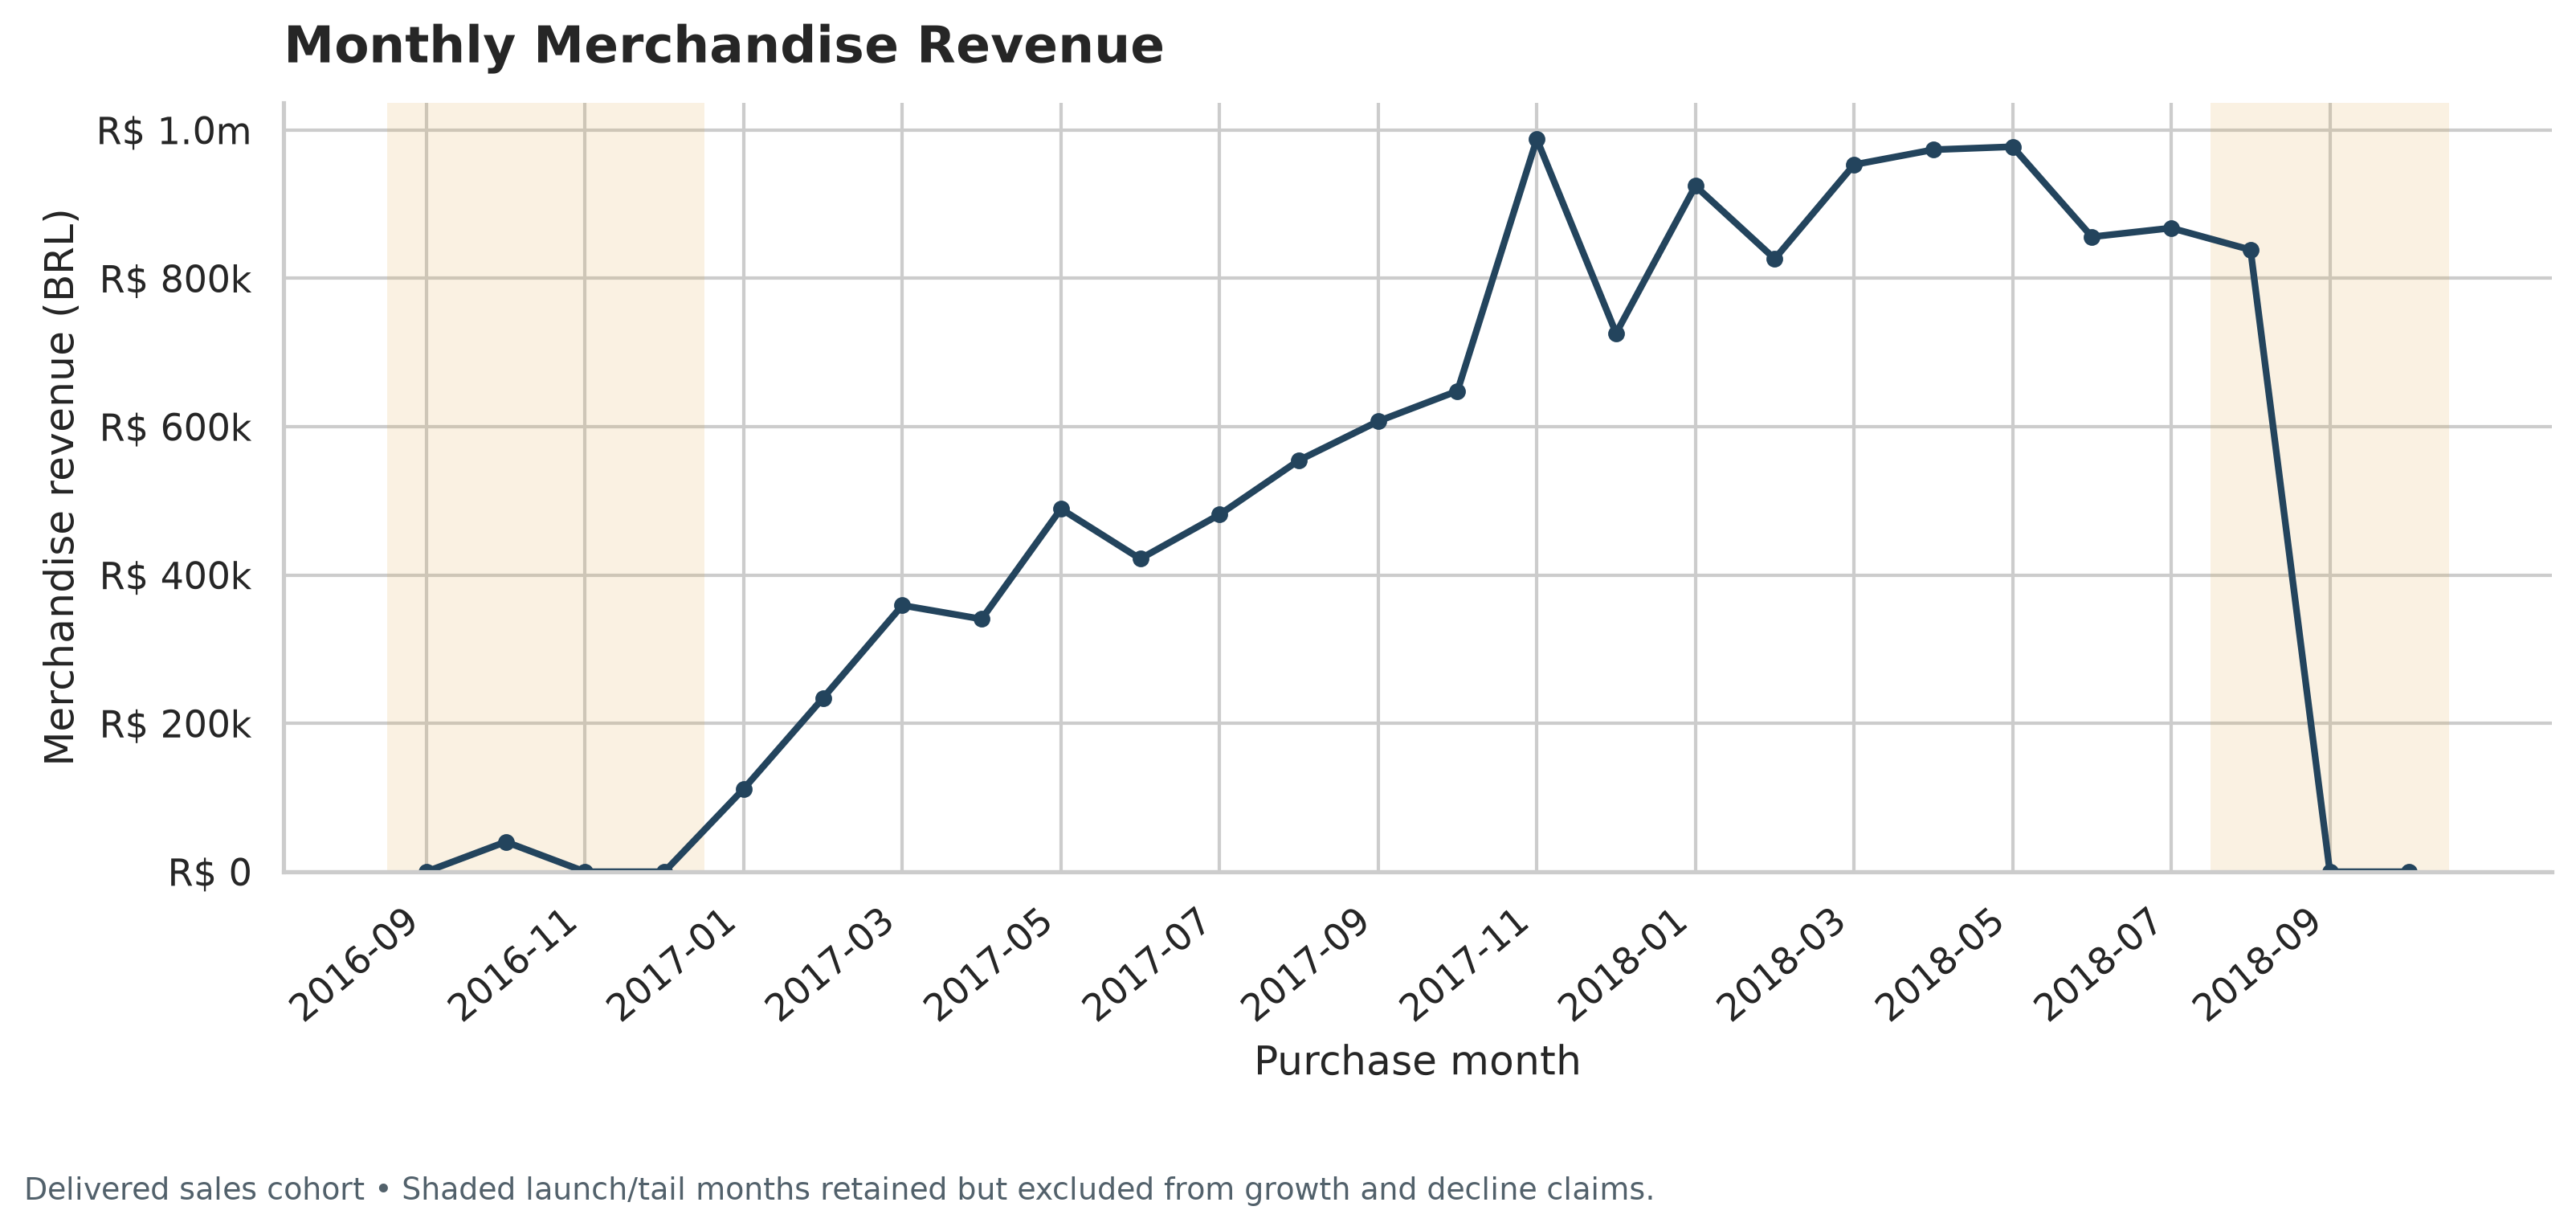

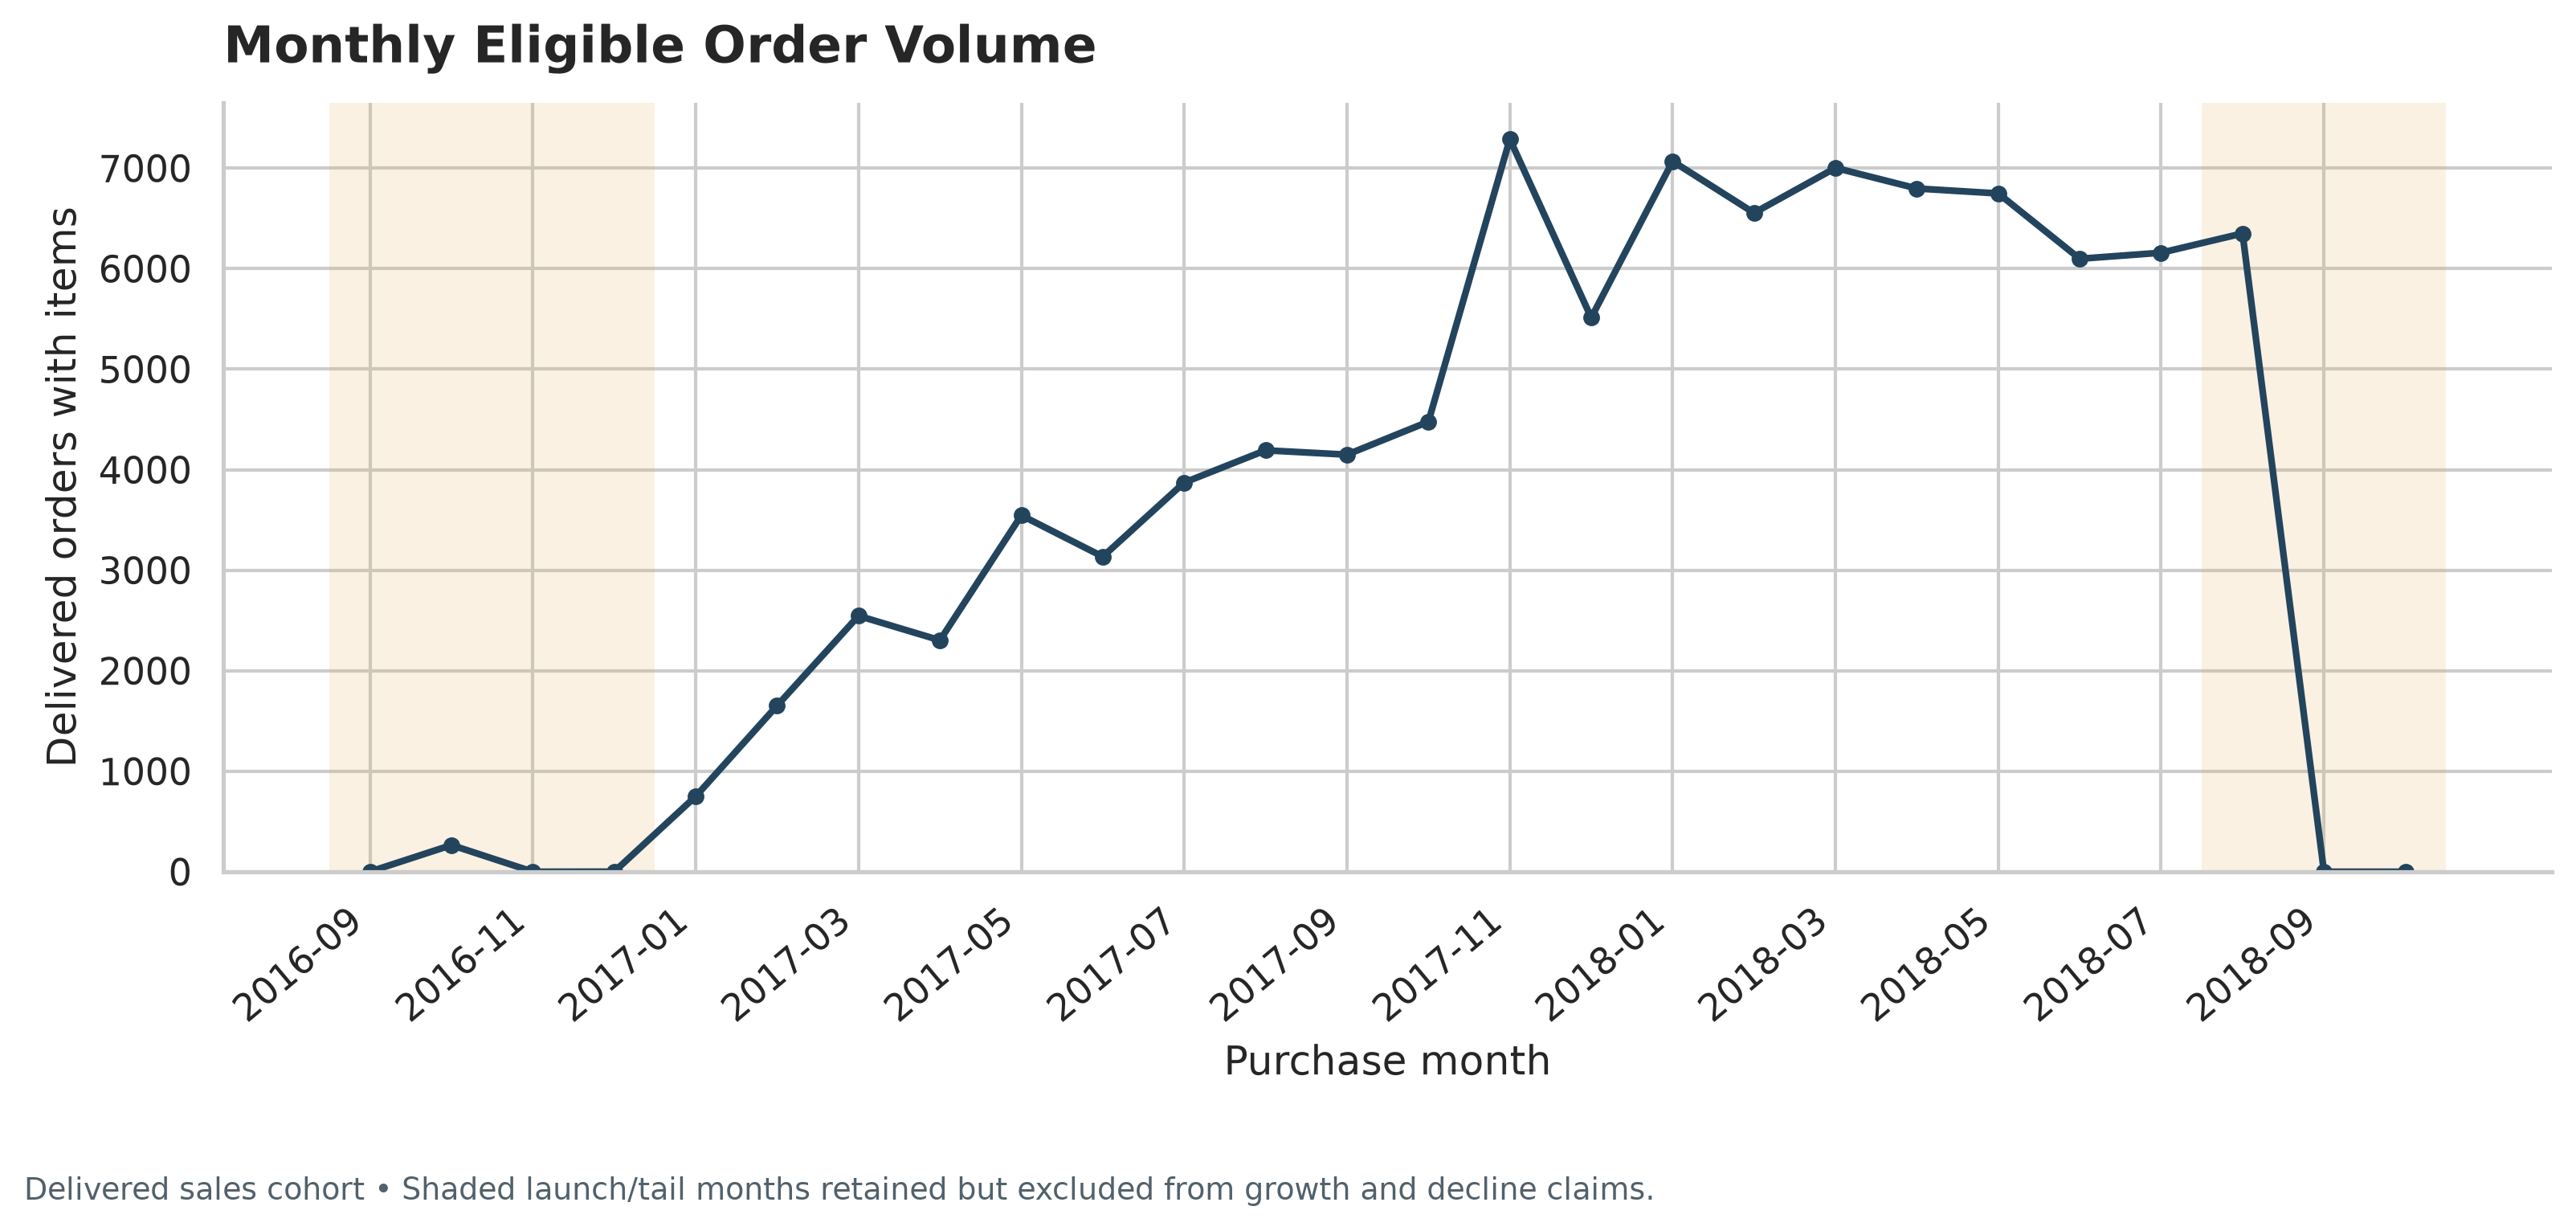

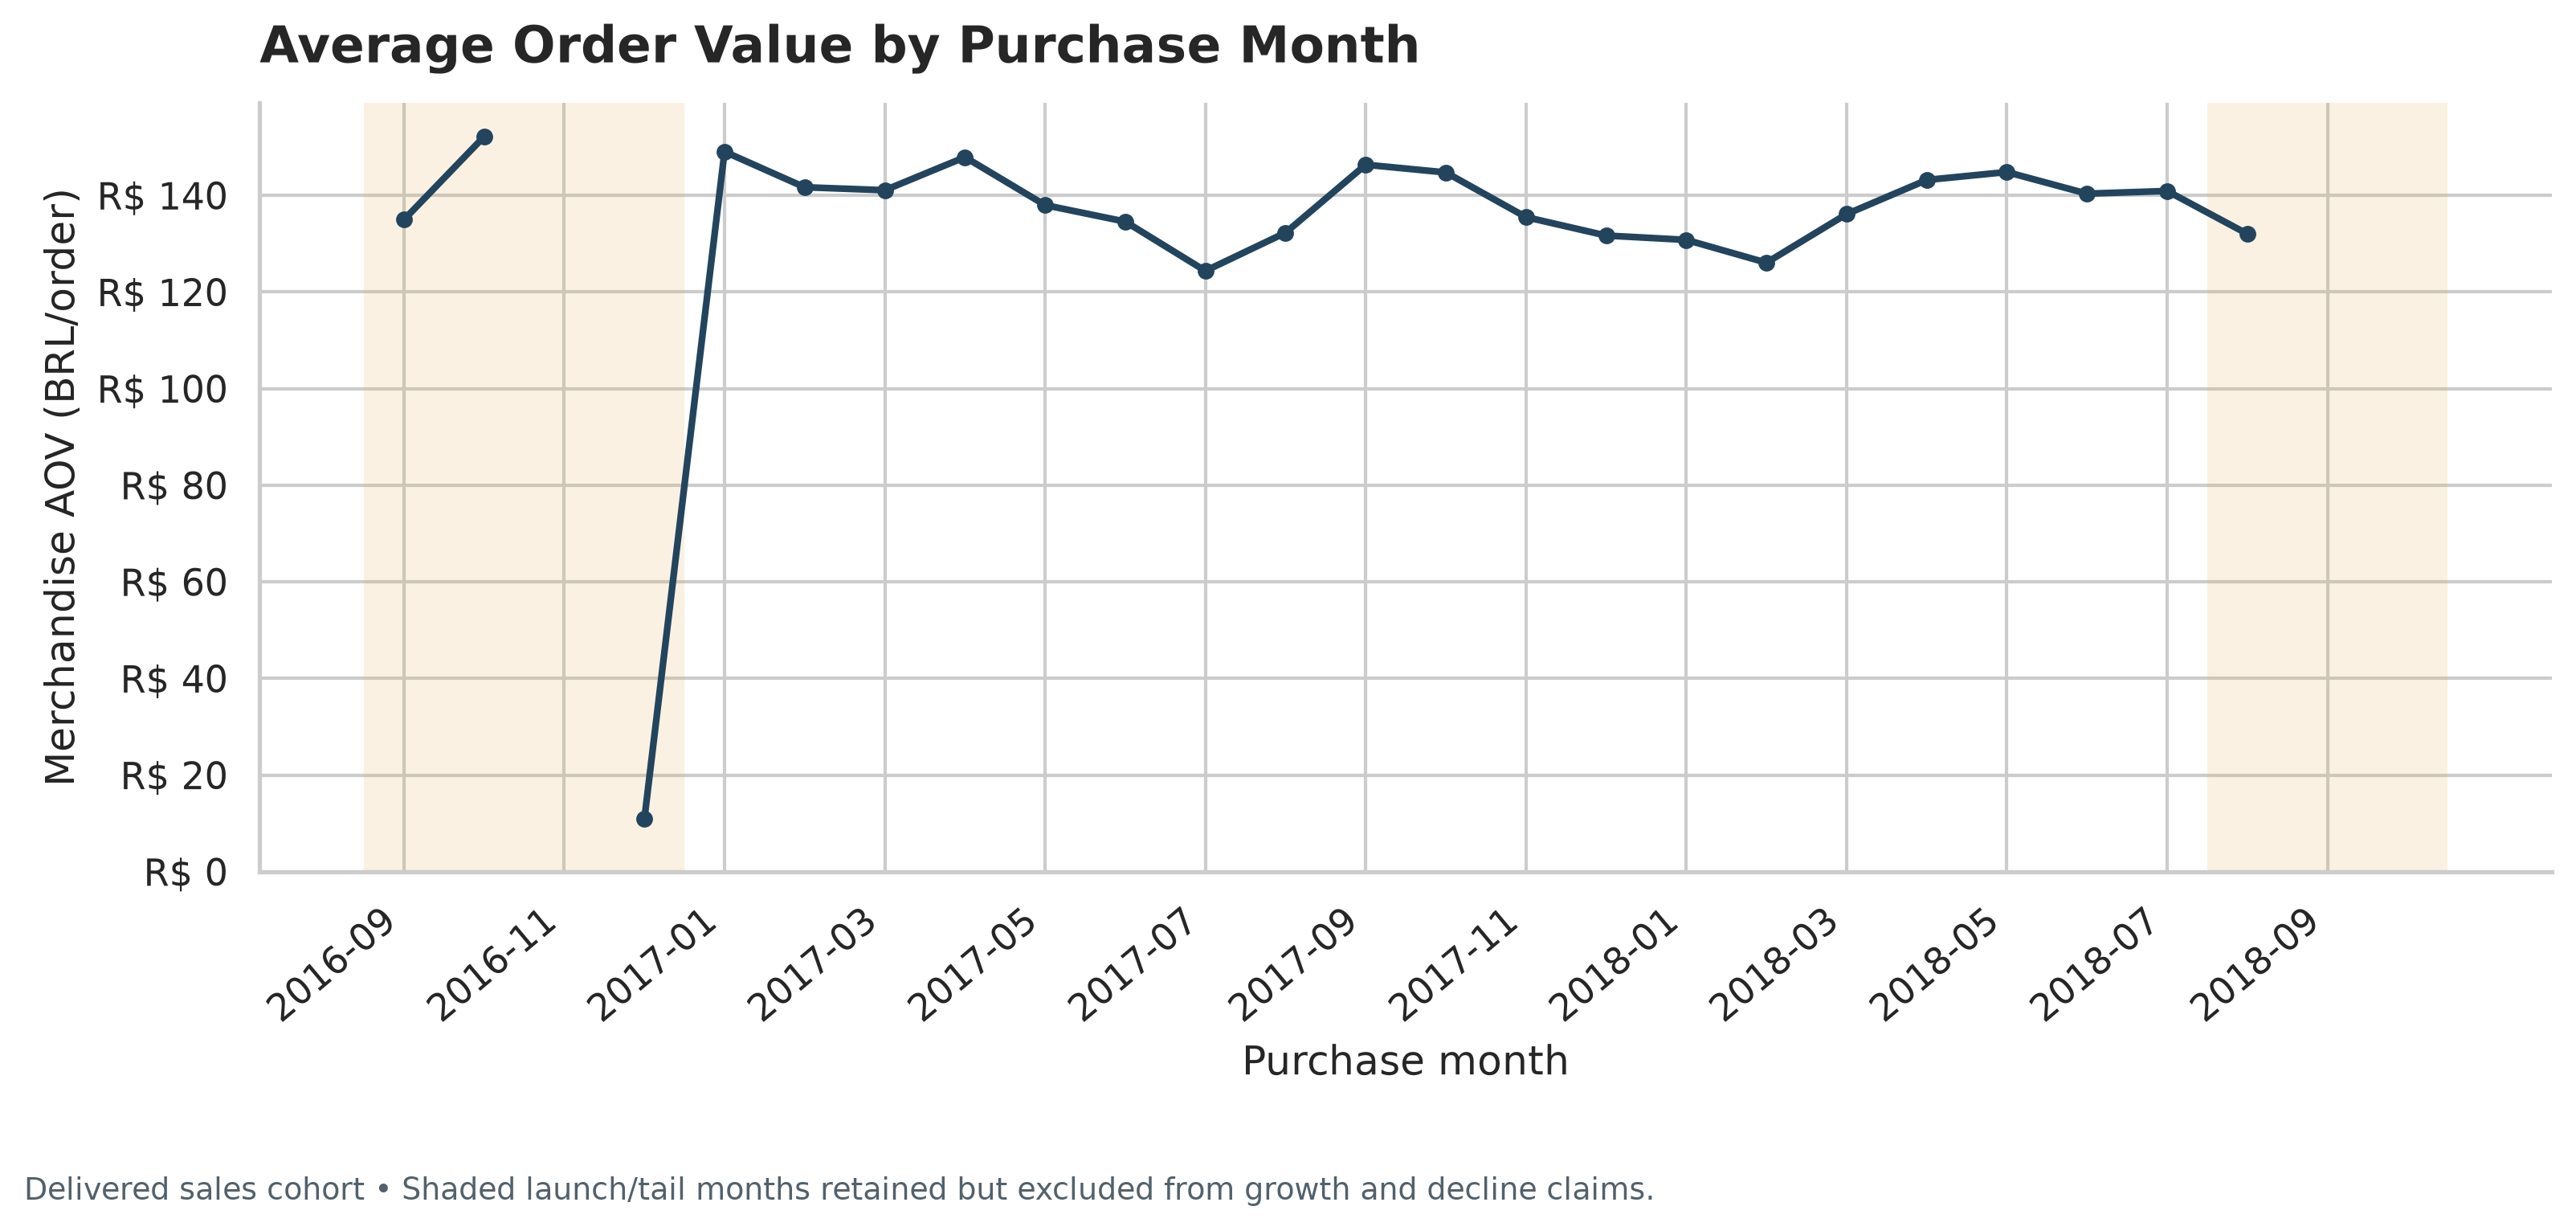

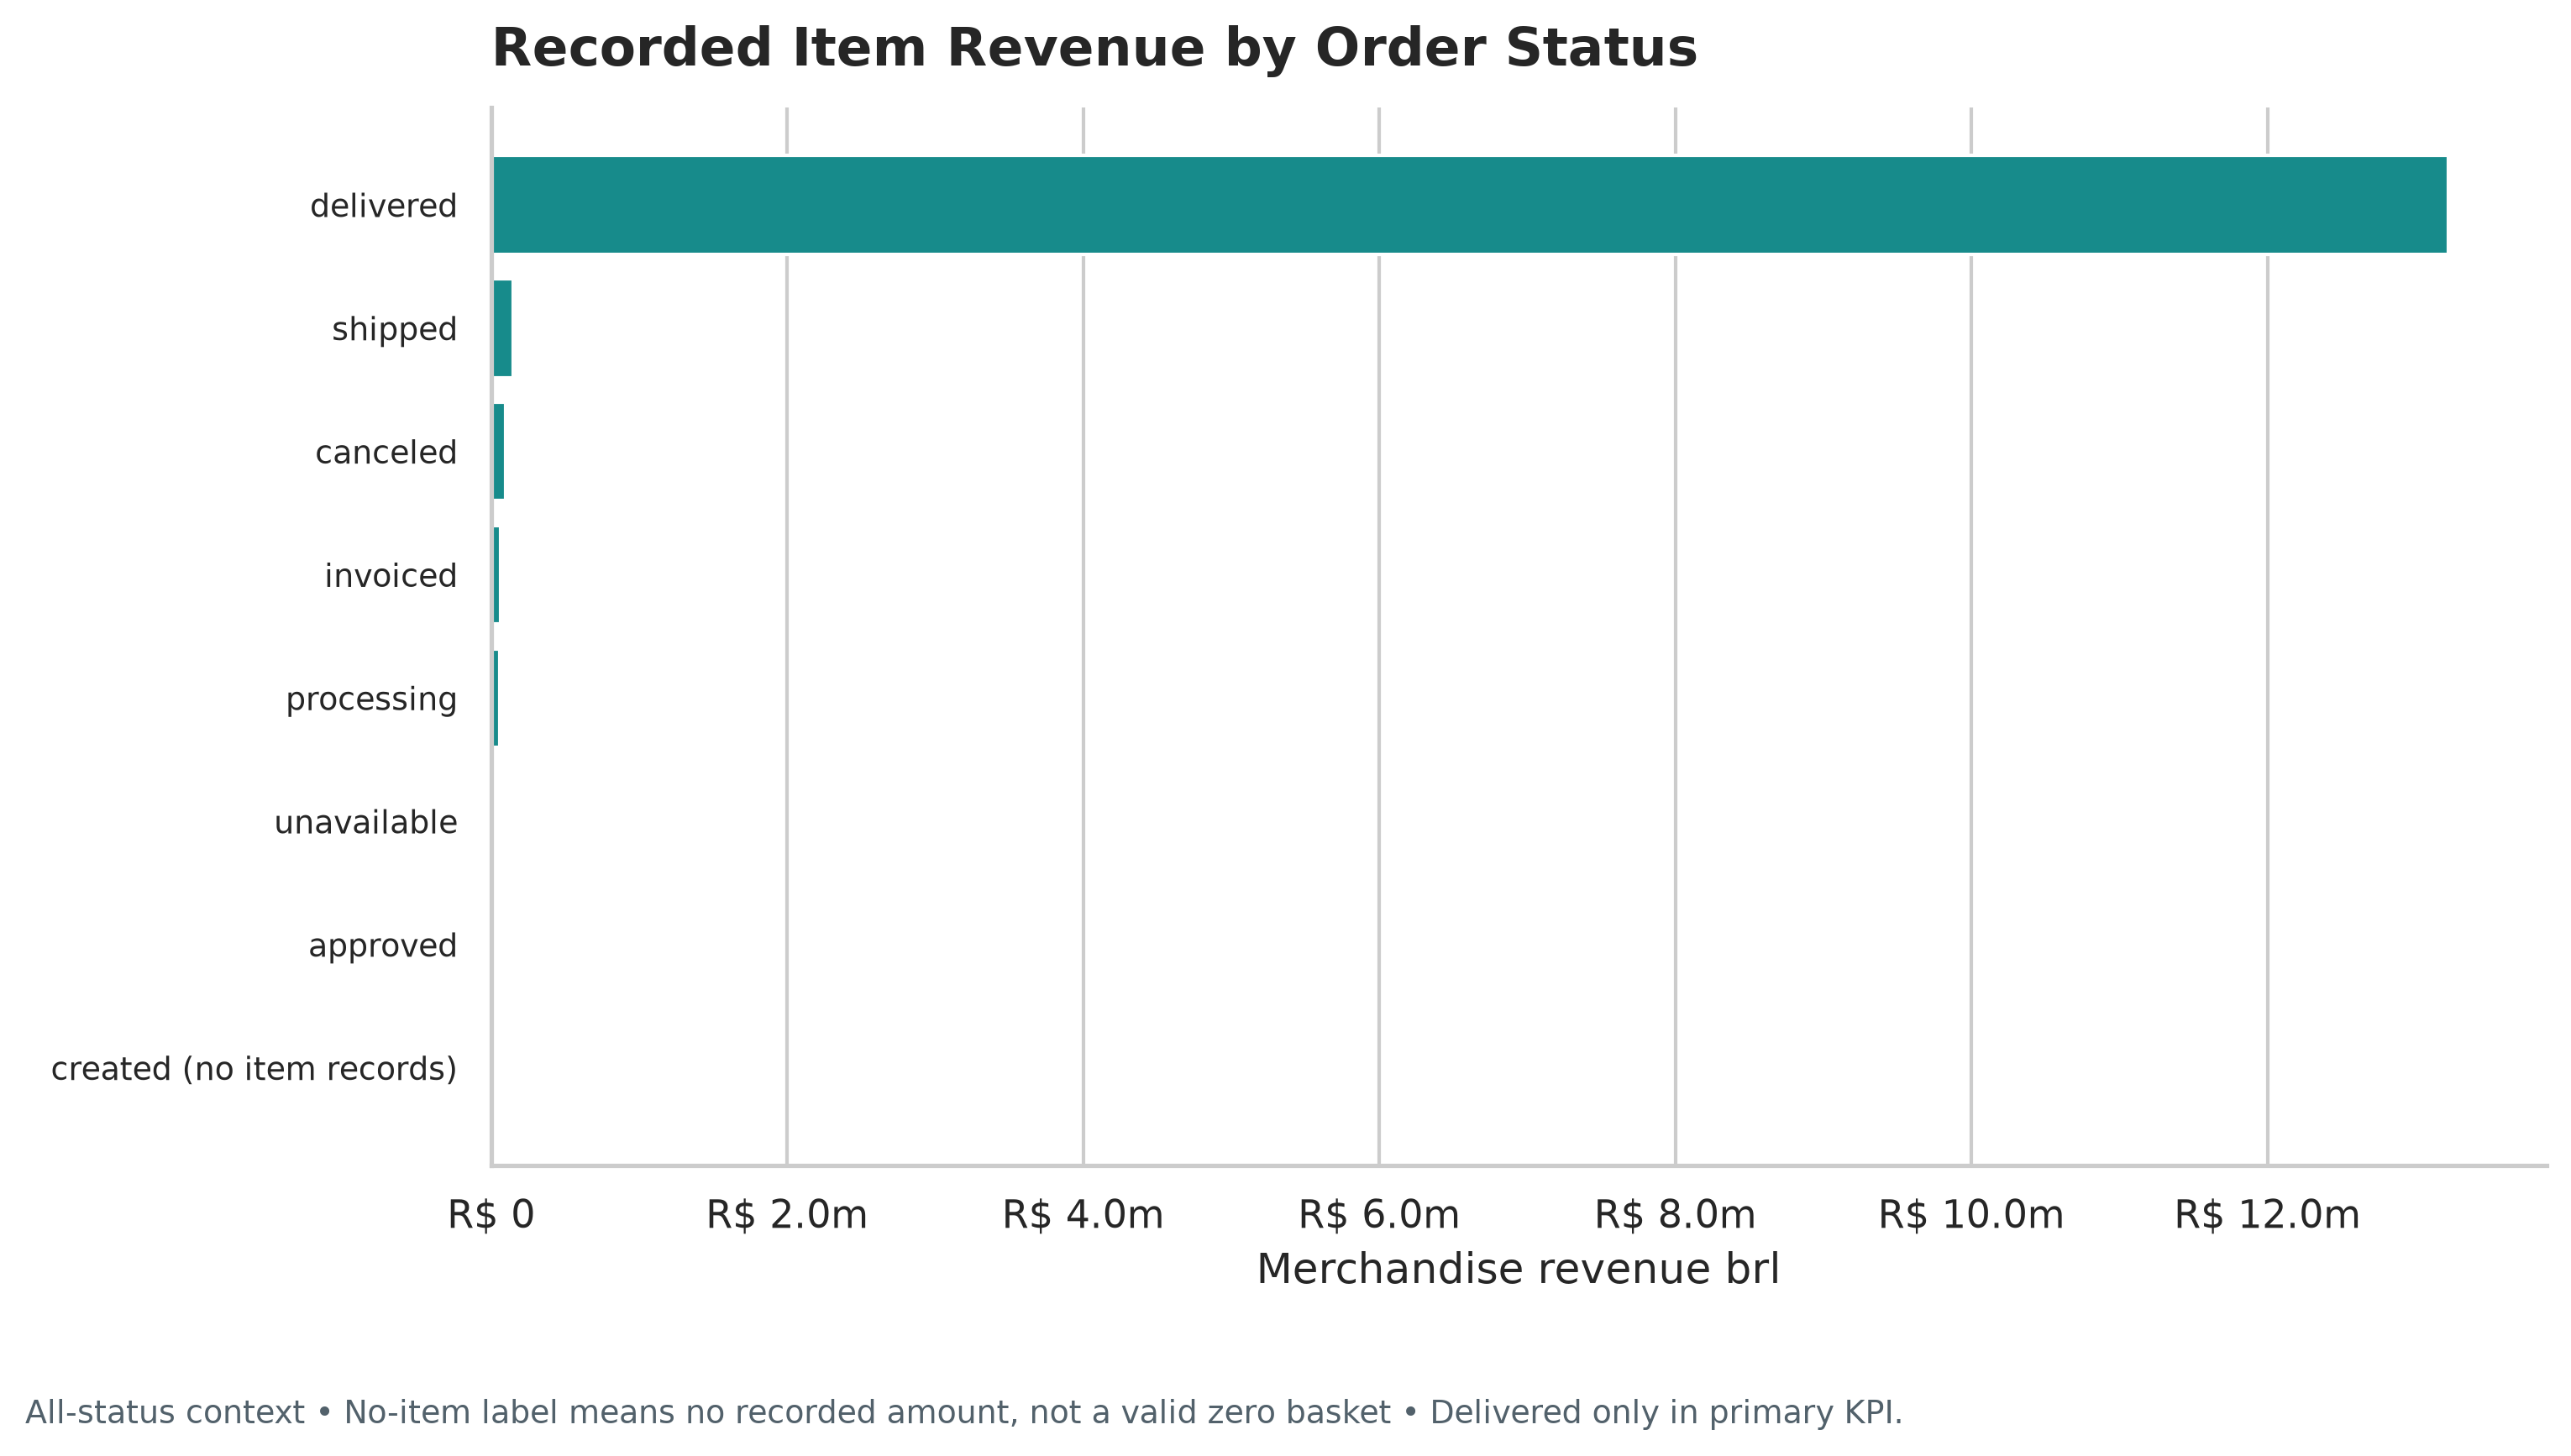

In [4]:
display(analysis["monthly"][["purchase_month", "eligible_orders", "excluded_order_count", "merchandise_revenue_brl", "average_order_value_brl", "average_items_per_order", "monthly_revenue_growth_pct", "comparable_month", "coverage_note"]].round(3))
display(analysis["status"])
comparable = analysis["monthly"].loc[analysis["monthly"]["comparable_month"]]
display(comparable.loc[[comparable["merchandise_revenue_cents"].idxmax(), comparable["merchandise_revenue_cents"].idxmin()], ["purchase_month", "merchandise_revenue_brl", "eligible_orders"]])
show_figures({"01", "02", "03", "04"})

## 4. Product and Category Performance

Use eligible item rows with a many-to-one product join. Known categories use the publisher's English label. Missing categories use `Unknown (missing category)` and untranslated Portuguese categories retain separate `Untranslated:` labels. No product names are invented.

Category revenue, items, average item price and cumulative shares reconcile to the same sales cohort. Each order can span categories; category distinct-order counts therefore cannot be added as a national order count.

,category_label,category_type,merchandise_revenue_cents,freight_cents,items_sold,eligible_orders,distinct_products,merchandise_revenue_brl,freight_brl,average_item_price_brl,revenue_contribution_pct,cumulative_revenue_pct,reviewed_order_categories,average_order_review_score
0,health_beauty,translated,123313172,17895781,9465,8647,2397,1233131.72,178957.81,130.283,9.327,9.327,8601,4.229
1,watches_gifts,translated,116617698,9815614,5859,5495,1300,1166176.98,98156.14,199.04,8.82,18.147,5454,4.121
2,bed_bath_table,translated,102343476,20177450,10953,9272,2991,1023434.76,201774.5,93.439,7.741,25.888,9177,3.999
3,sports_leisure,translated,95485255,16340436,8431,7530,2822,954852.55,163404.36,113.255,7.222,33.11,7486,4.228
4,computers_accessories,translated,88872461,14399916,7644,6530,1600,888724.61,143999.16,116.264,6.722,39.831,6499,4.081
5,furniture_decor,translated,71192769,16840223,8160,6307,2593,711927.69,168402.23,87.246,5.385,45.216,6260,4.058
6,housewares,translated,61562869,14276356,6795,5743,2282,615628.69,142763.56,90.6,4.656,49.872,5709,4.194
7,cool_stuff,translated,61020410,8147679,3718,3559,770,610204.1,81476.79,164.122,4.615,54.488,3531,4.217
8,auto,translated,57896665,9048810,4140,3810,1853,578966.65,90488.1,139.847,4.379,58.867,3792,4.146
9,toys,translated,47128648,7577458,4030,3804,1373,471286.48,75774.58,116.945,3.565,62.431,3774,4.238


,category_label,items_sold,average_item_price_brl
2,bed_bath_table,10953,93.439
0,health_beauty,9465,130.283
3,sports_leisure,8431,113.255
5,furniture_decor,8160,87.246
4,computers_accessories,7644,116.264
6,housewares,6795,90.6
1,watches_gifts,5859,199.04
13,telephony,4430,69.946
10,garden_tools,4268,110.238
8,auto,4140,139.847


,product_id,merchandise_revenue_cents,items_sold,eligible_orders,merchandise_revenue_brl
23546,bb50f2e236e5eea0100680137654686c,6356000,194,186,63560.0
13749,6cdd53843498f92890544667809f1595,5365230,153,148,53652.3
26997,d6160fb7873f184099d9bc95e30376af,4594935,33,33,45949.35
26436,d1c427060a0f73f6b889a5c7c61f2ac4,4562056,332,313,45620.56
19290,99a4788cb24856965c36a24e339b6058,4204966,477,456,42049.66
7881,3dd2a17168ec895c781a9191c1e95ad7,4078280,272,253,40782.8
4892,25c38557cf793876c5abdd5931f922db,3890732,38,38,38907.32
12074,5f504b3a1c75b73d6151be81eb05bdc9,3773390,63,63,37733.9
10616,53b36df67ebb7c41585e8d54d6772e08,3745463,321,304,37454.63
21617,aca2eb7d00ea1a7b8ebd4e68314663af,3710430,520,425,37104.3


,category_label,category_type,merchandise_revenue_cents,freight_cents,items_sold,eligible_orders,distinct_products,merchandise_revenue_brl,freight_brl,average_item_price_brl,revenue_contribution_pct,cumulative_revenue_pct,reviewed_order_categories,average_order_review_score
20,Unknown (missing category),missing,17072663,2696906,1537,1392,584,170726.63,26969.06,111.077833,1.291281,85.356254,1382,4.010492
62,Untranslated: portateis_cozinha_e_preparadores...,untranslated,393363,29442,14,13,9,3933.63,294.42,280.973571,0.029752,99.887987,13,3.615385
68,Untranslated: pc_gamer,untranslated,130695,12315,8,7,2,1306.95,123.15,163.36875,0.009885,99.974257,7,3.428571


Top 10 category revenue share: 62.43%


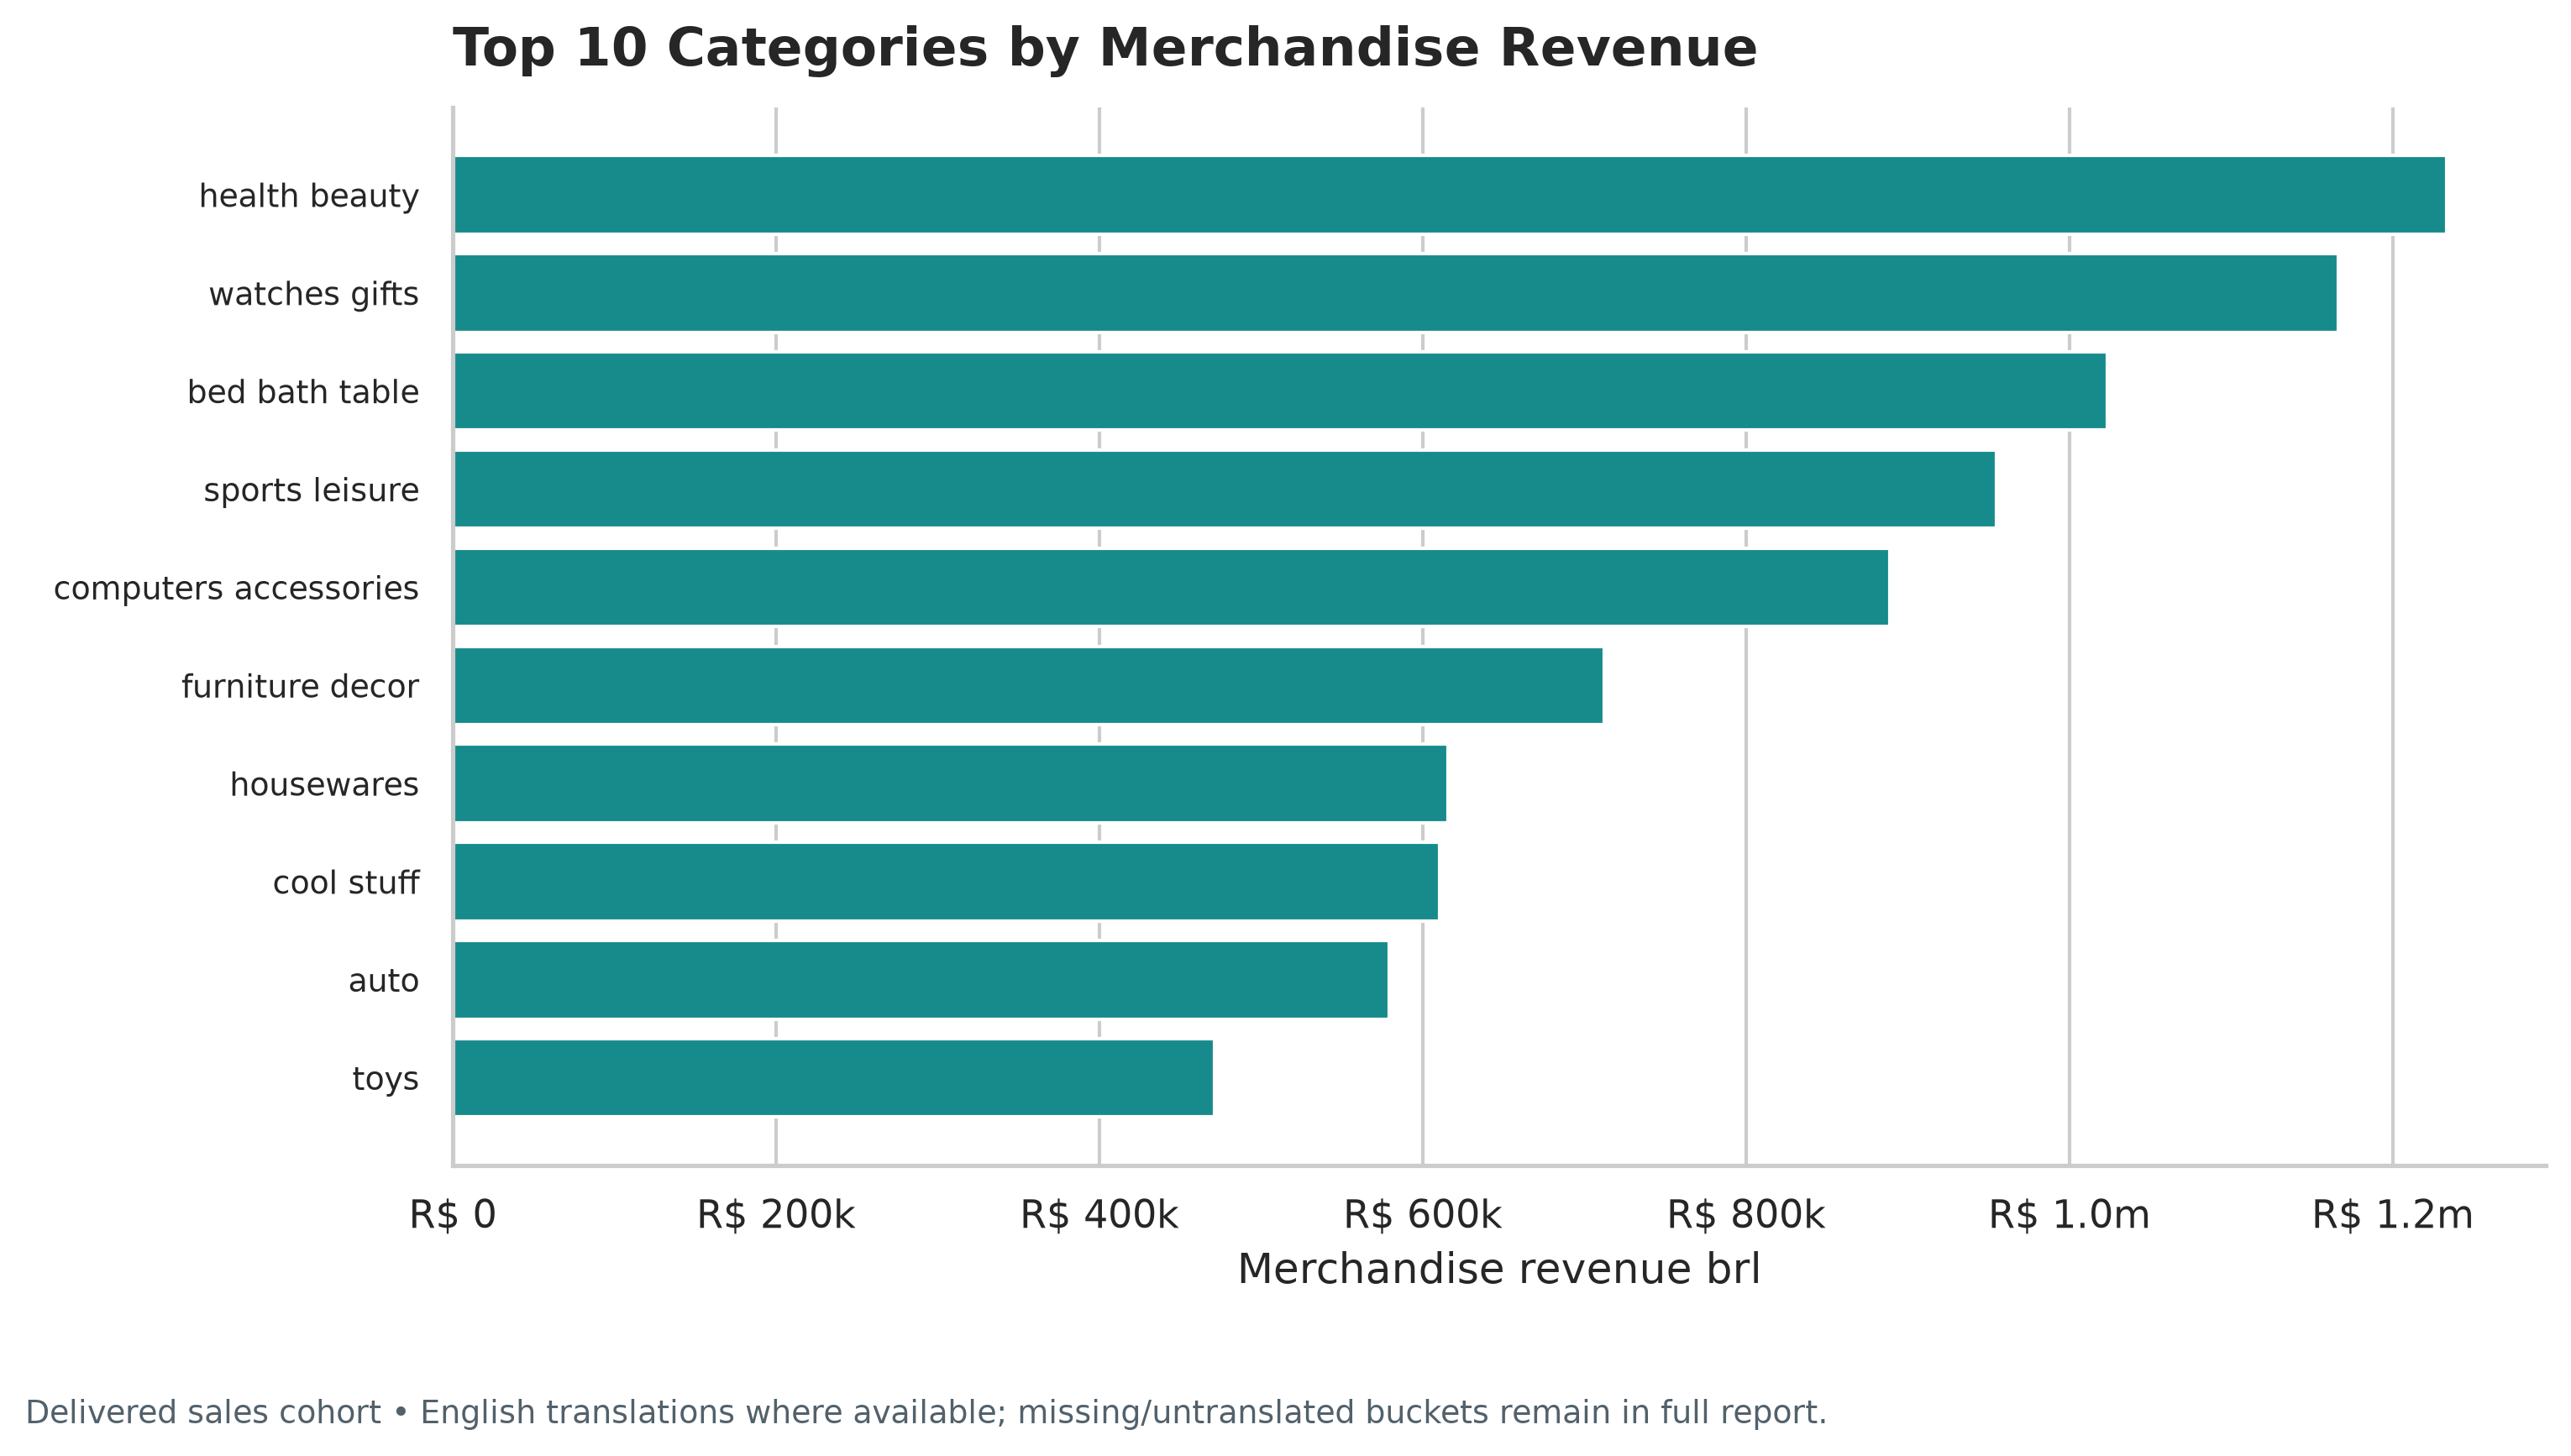

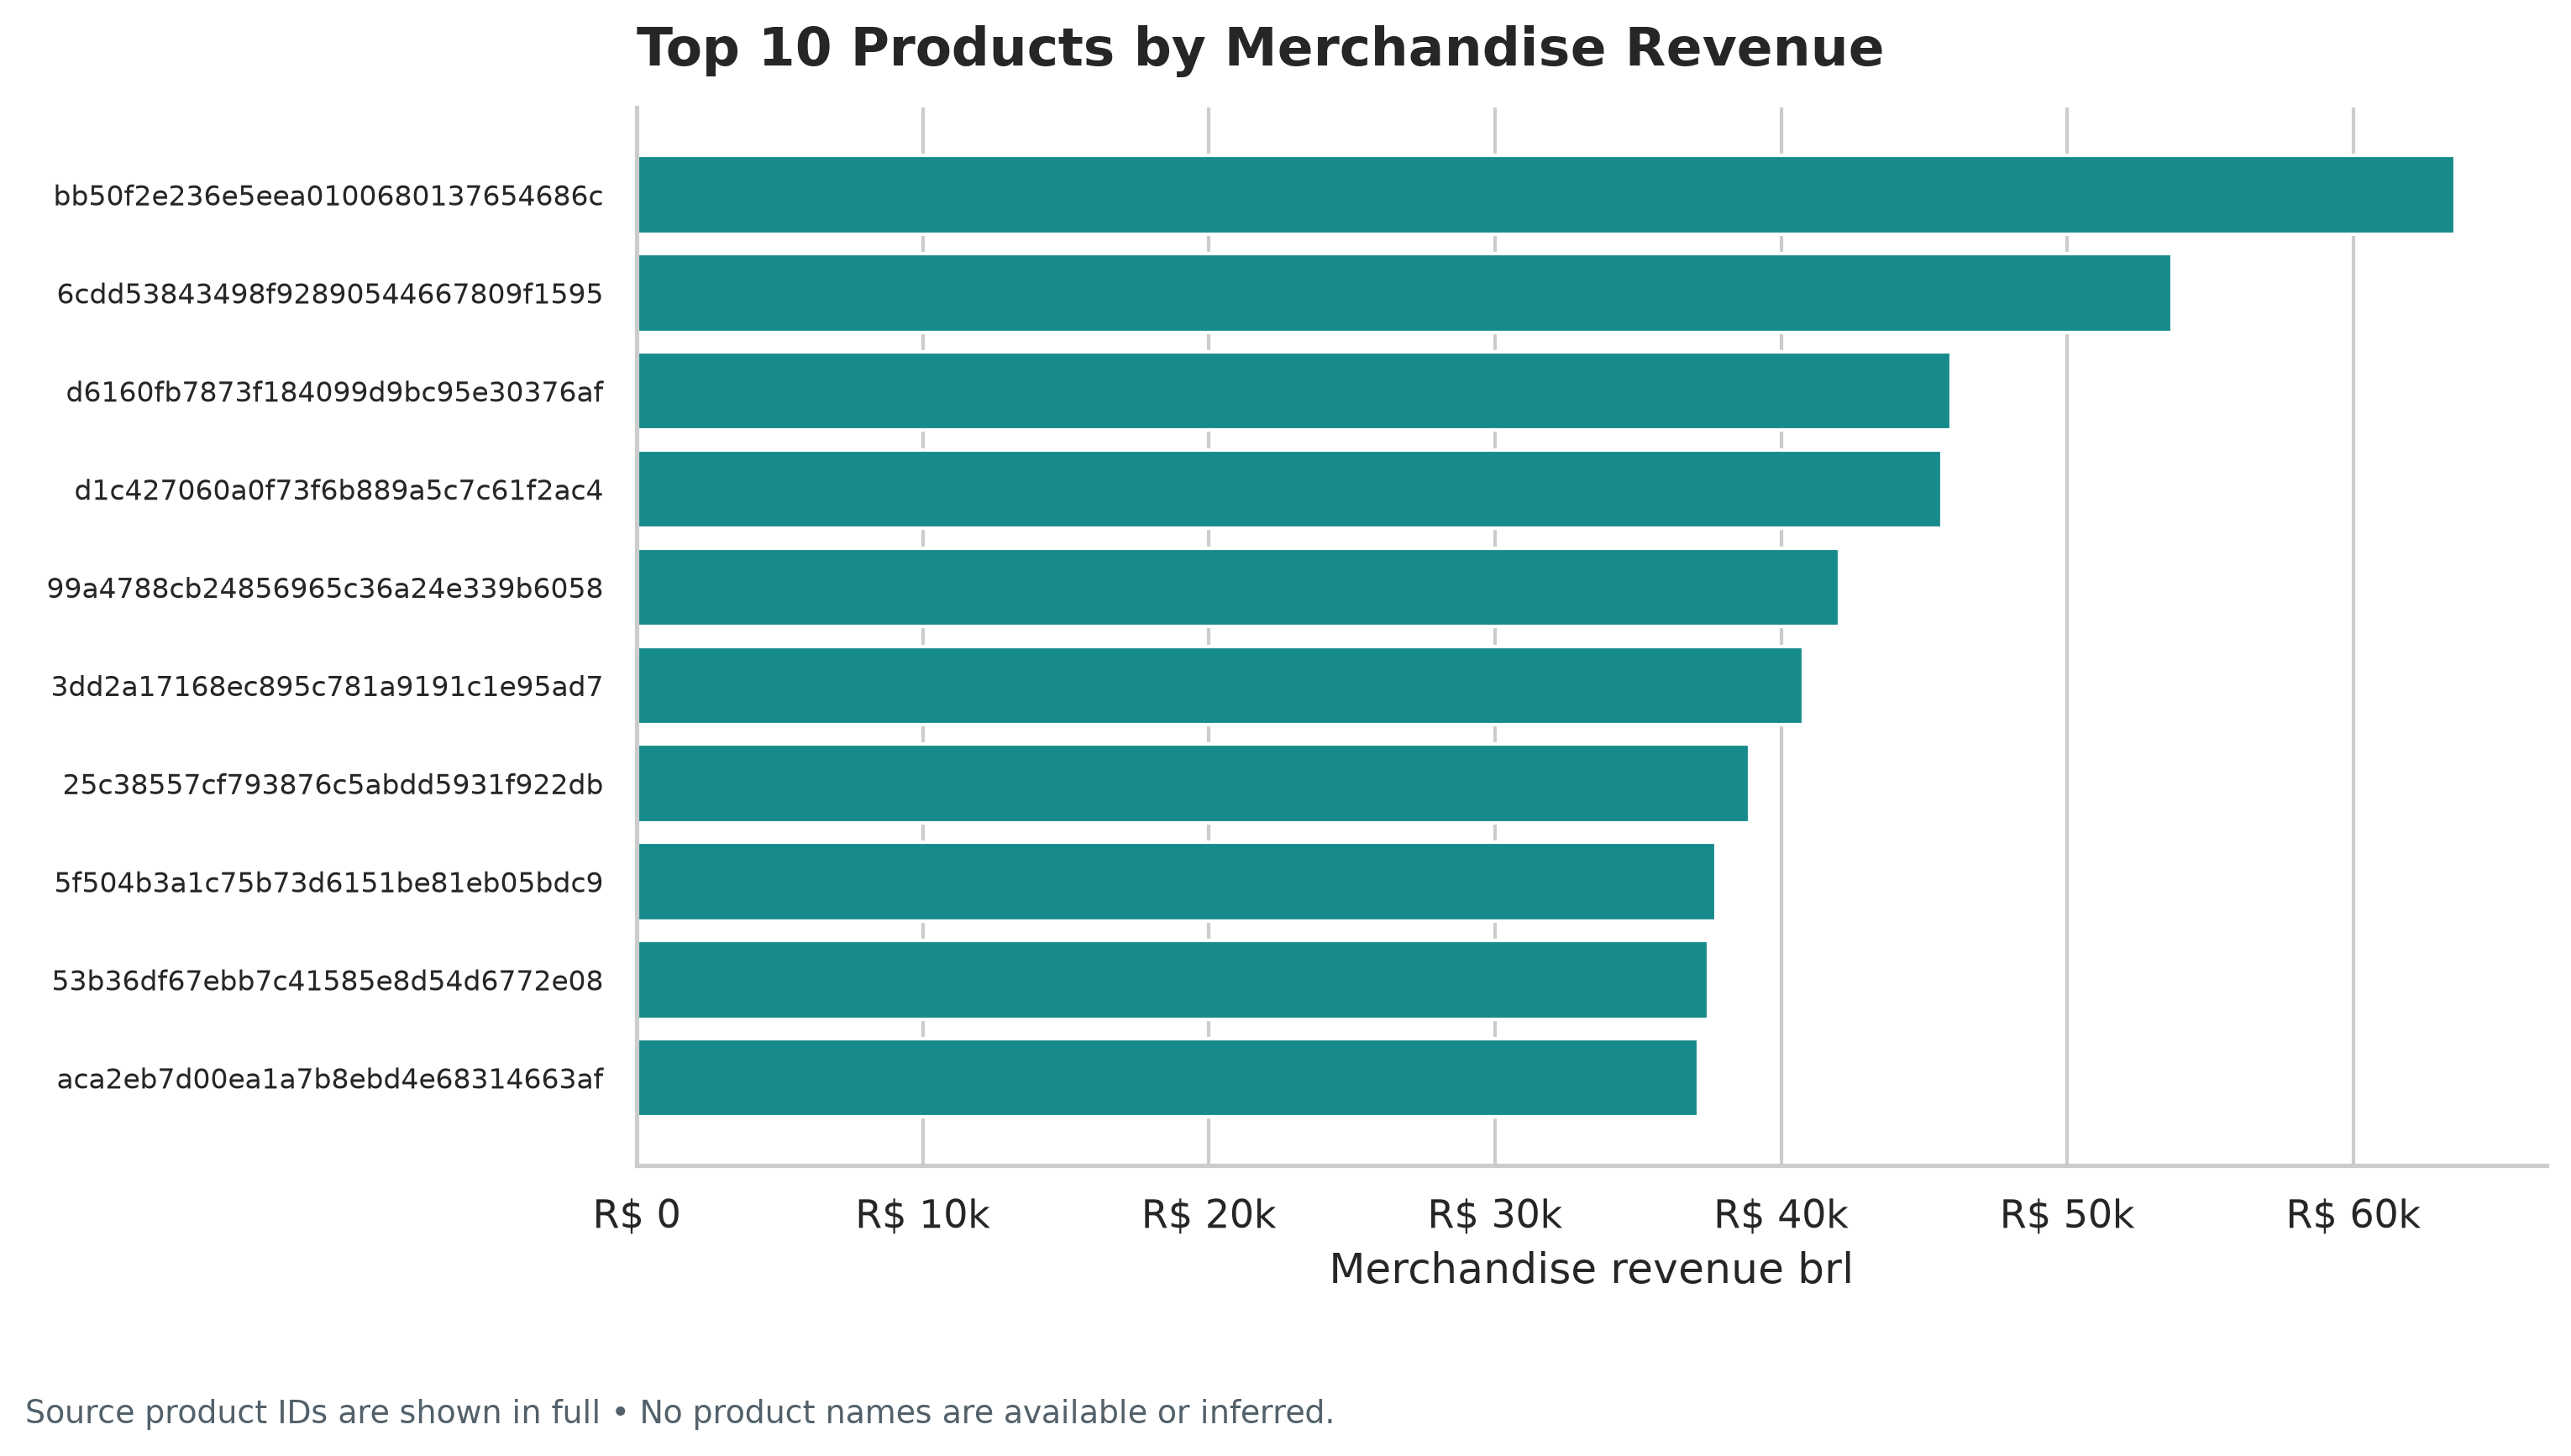

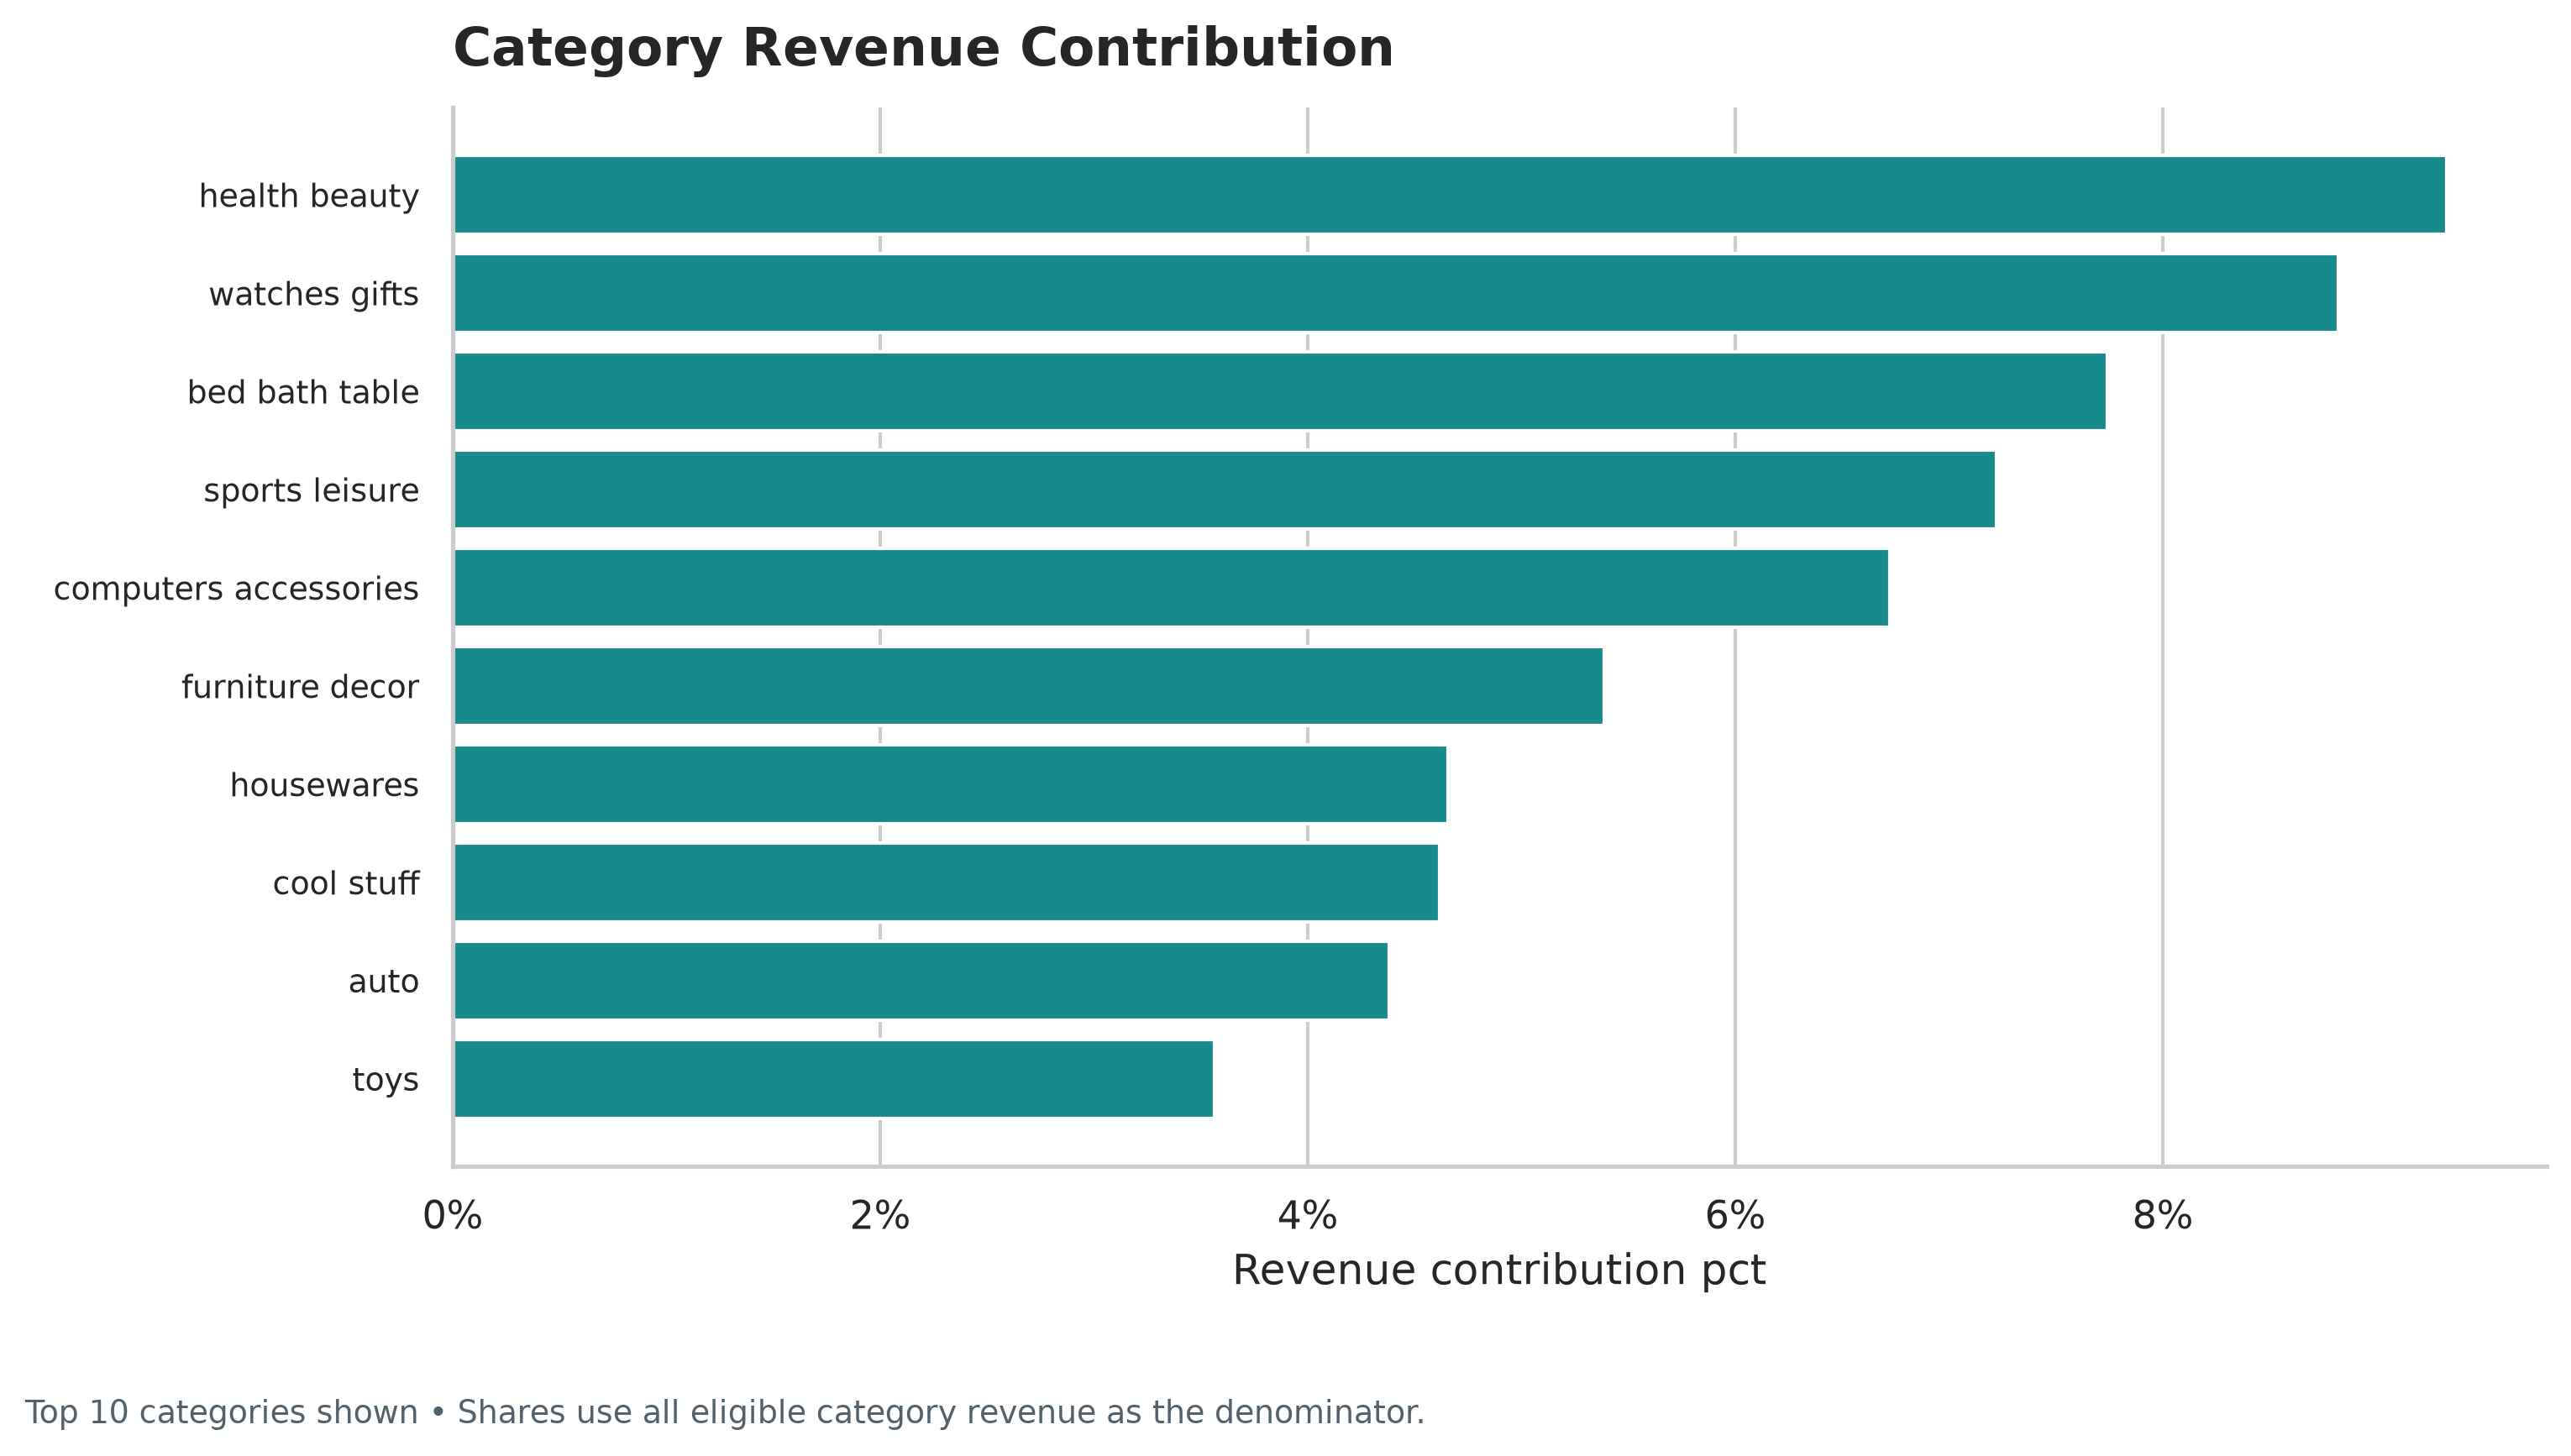

In [5]:
display(analysis["categories"].head(10).round(3))
display(analysis["categories"].nlargest(10, "items_sold")[["category_label", "items_sold", "average_item_price_brl"]].round(3))
display(analysis["products"].head(10))
display(analysis["categories"].loc[~analysis["categories"]["category_type"].eq("translated")])
print(f"Top 10 category revenue share: {analysis['categories'].head(10)['revenue_contribution_pct'].sum():.2f}%")
show_figures({"05", "06", "07"})

## 5. Customer Behavior and Geography

One row per `customer_unique_id` summarizes eligible distinct orders and merchandise revenue. “First-time” is only a one-observed-purchase proxy, not proof of lifetime acquisition; repeat means at least two observed eligible orders. No full RFM, retention or cohort analysis is performed.

State revenue follows each order's original customer record. Per-state distinct customer counts can overlap. For the customer-distribution chart only, each identity is assigned its last observed eligible order's source state, using purchase timestamp and order ID to resolve ties. This is not an authoritative residence estimate. Log-positioned customer-revenue histograms retain the entire distribution and label the scale explicitly.

,eligible_orders_per_customer,customers
0,1,90557
1,2,2573
2,3,181
3,4,28
4,5,9
5,6,5
6,7,3
7,9,1
8,15,1


,customer_unique_id,eligible_orders,items_sold,merchandise_revenue_cents,freight_cents,first_observed_purchase,last_observed_purchase,merchandise_revenue_brl,freight_brl,average_order_value_brl,purchase_segment,last_observed_customer_state
3724,0a0a92112bd4c708ca5fde585afaa872,1,8,1344000,22408,2017-09-29 15:24:52,2017-09-29 15:24:52,13440.0,224.08,13440.0,One observed order,RJ
79636,da122df9eeddfedc1dc1f5349a1a690c,2,2,738800,18363,2017-04-01 15:58:40,2017-04-01 15:58:41,7388.0,183.63,3694.0,Repeat: 2+ observed orders,RJ
43168,763c8b1c9c68a0229c42c9fc6f662b93,1,4,716000,11488,2018-07-15 14:49:44,2018-07-15 14:49:44,7160.0,114.88,7160.0,One observed order,ES
80463,dc4802a71eae9be1dd28f5d788ceb526,1,1,673500,19431,2017-02-12 20:37:36,2017-02-12 20:37:36,6735.0,194.31,6735.0,One observed order,MS
25436,459bef486812aa25204be022145caa62,1,1,672900,19321,2018-07-25 18:10:17,2018-07-25 18:10:17,6729.0,193.21,6729.0,One observed order,ES
93081,ff4159b92c40ebe40454e3e6a7c35ed6,1,1,649900,22766,2017-05-24 18:14:34,2017-05-24 18:14:34,6499.0,227.66,6499.0,One observed order,SP
23411,4007669dec559734d6f53e029e360987,1,6,593460,14694,2017-11-24 11:03:35,2017-11-24 11:03:35,5934.6,146.94,5934.6,One observed order,MG
87148,eebb5dda148d3893cdaf5b5ca3040ccb,1,1,469000,7434,2017-04-18 18:50:13,2017-04-18 18:50:13,4690.0,74.34,4690.0,One observed order,SP
26640,48e1ac109decbb87765a3eade6854098,1,1,459000,9178,2018-06-22 12:23:19,2018-06-22 12:23:19,4590.0,91.78,4590.0,One observed order,PB
59163,a229eba70ec1c2abef51f04987deb7a5,1,2,440000,4550,2018-05-31 22:57:07,2018-05-31 22:57:07,4400.0,45.5,4400.0,One observed order,RJ


,customer_state,merchandise_revenue_cents,eligible_orders,unique_customers_with_orders_in_state,freight_cents,merchandise_revenue_brl,average_freight_per_order_brl,customers_by_last_observed_state
25,SP,506763316,40501,39156,70206999,5067633.16,17.334633,39150
18,RJ,175965113,12350,11917,29575044,1759651.13,23.947404,11914
10,MG,155248183,11354,11001,26640984,1552481.83,23.463963,10995
22,RS,72889747,5345,5168,13257532,728897.47,24.803615,5167
17,PR,66606351,4923,4769,11564529,666063.51,23.490817,4766
23,SC,50701213,3546,3449,8811565,507012.13,24.849309,3446
4,BA,49358414,3256,3158,9755367,493584.14,29.961201,3156
6,DF,29649841,2080,2019,4962494,296498.41,23.858144,2016
8,GO,28283670,1957,1895,5137565,282836.7,26.252248,1893
7,ES,26864345,1995,1928,4901448,268643.45,24.568662,1928


count       93358.0
mean      141.62148
std      215.694014
min            0.85
50%           89.73
90%          279.99
95%         419.809
99%         1004.99
max         13440.0
Name: merchandise_revenue_brl, dtype: Float64

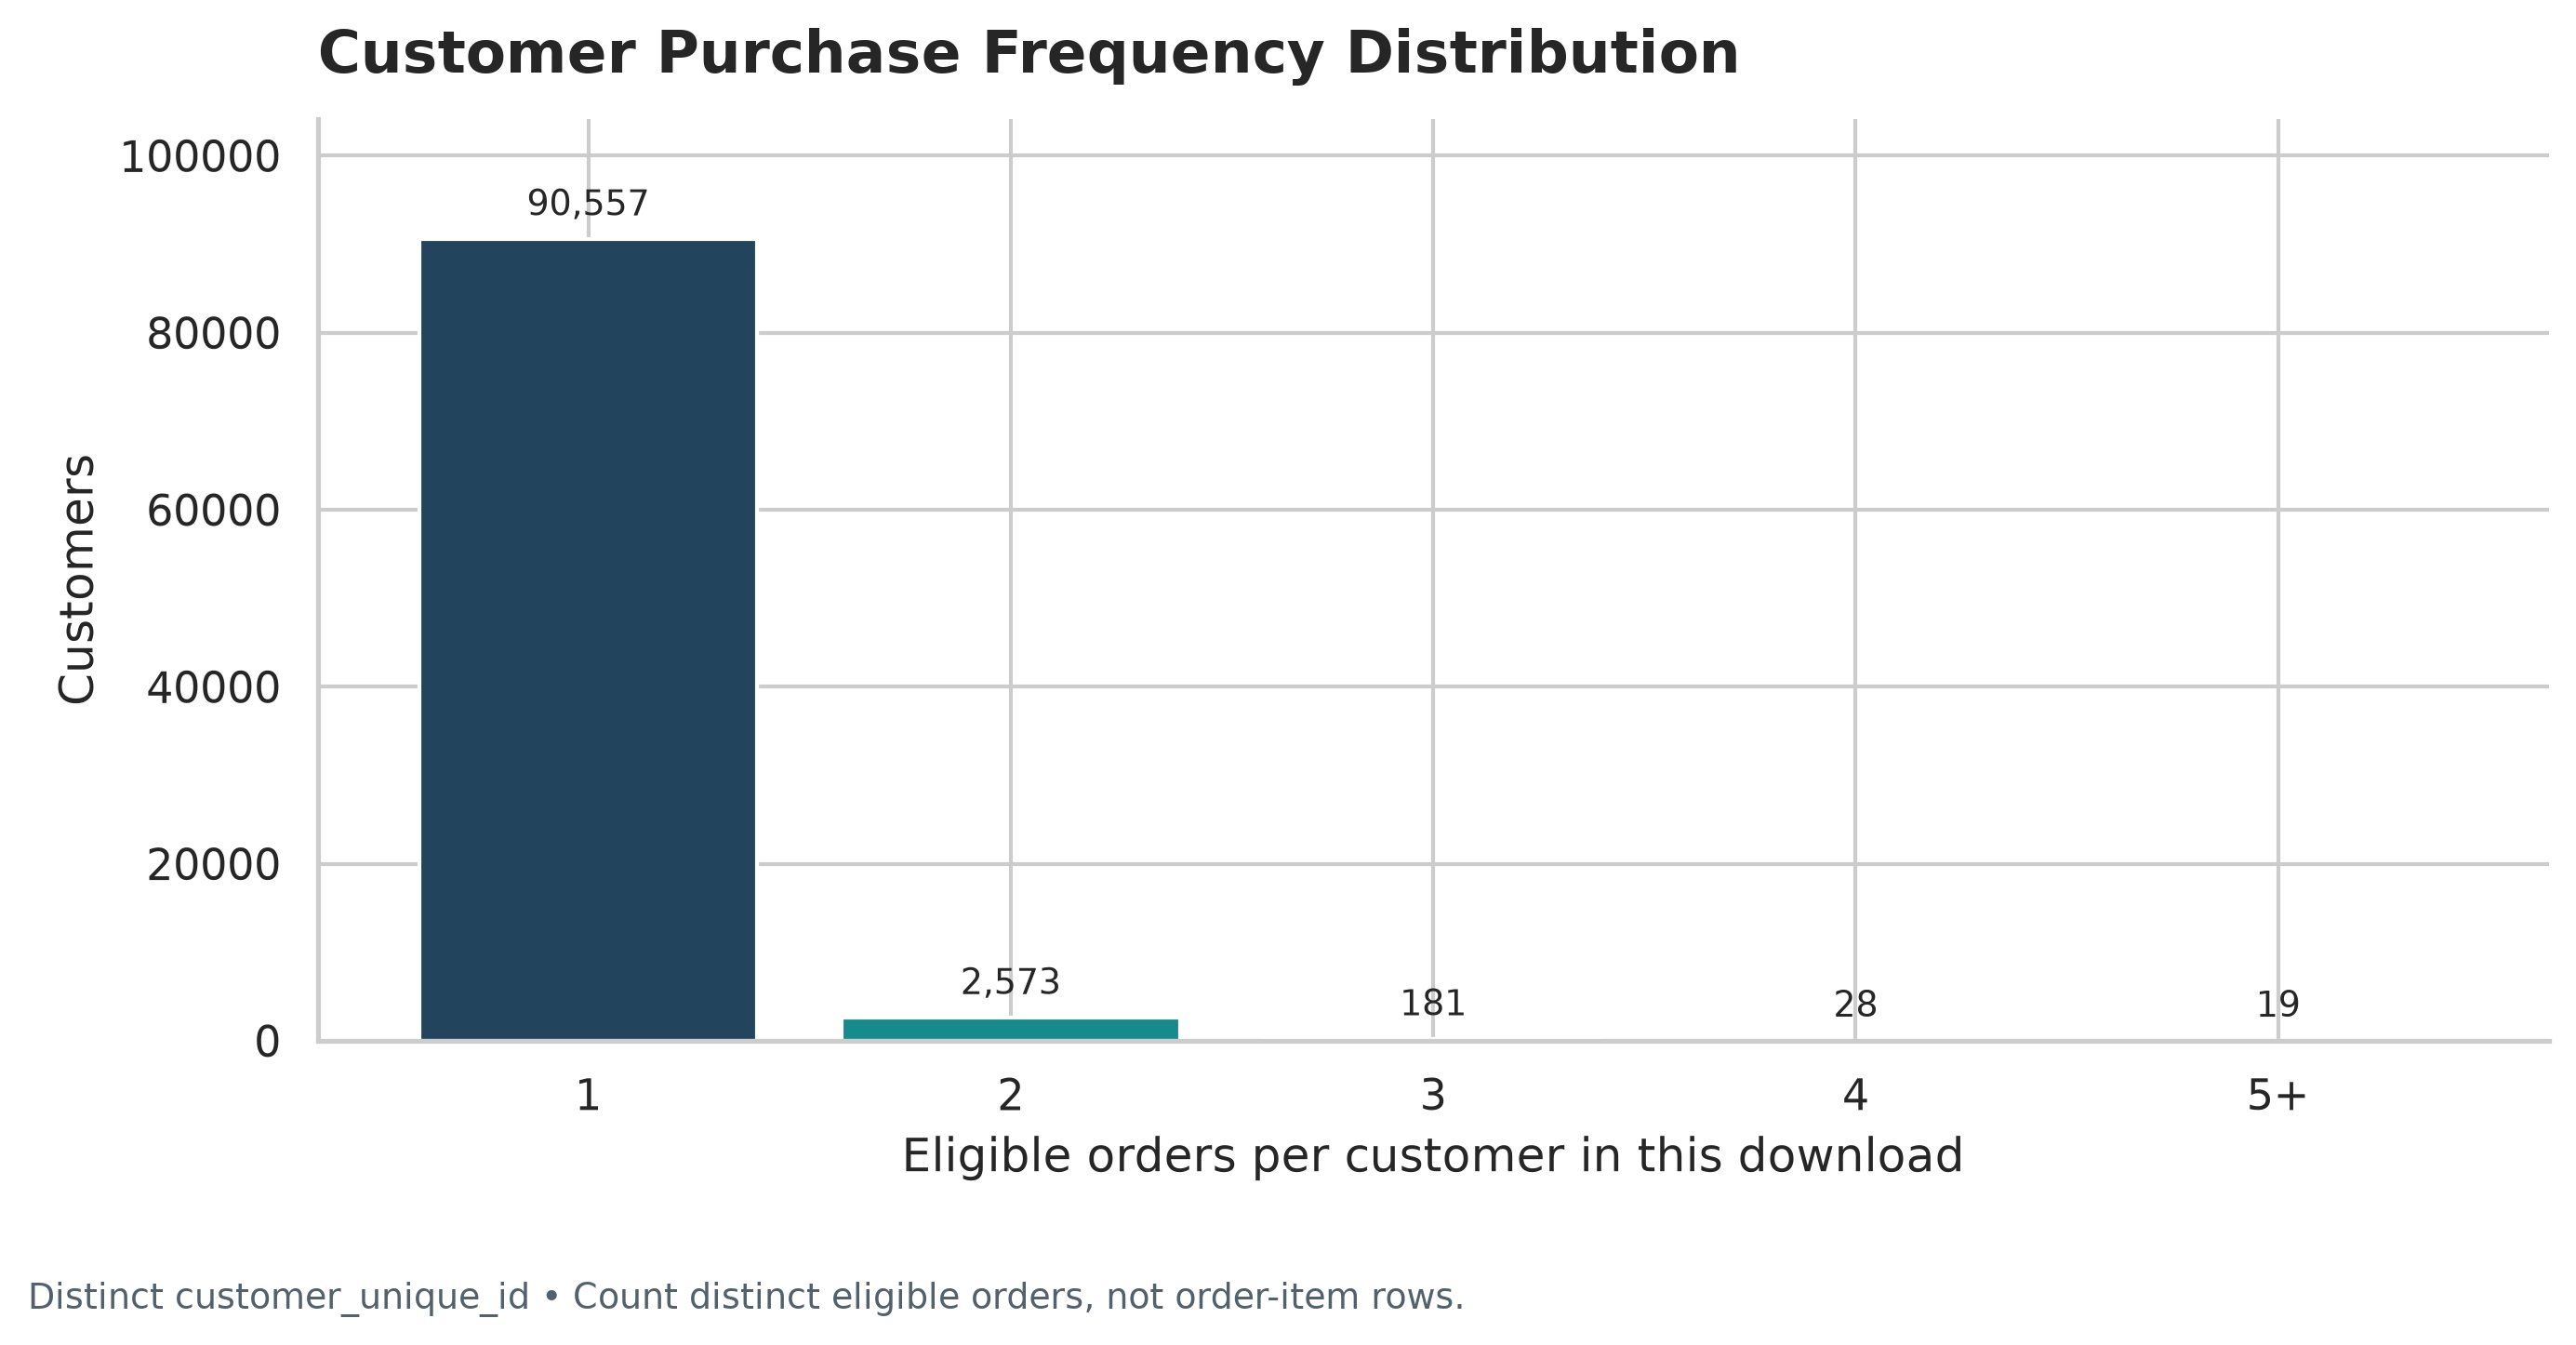

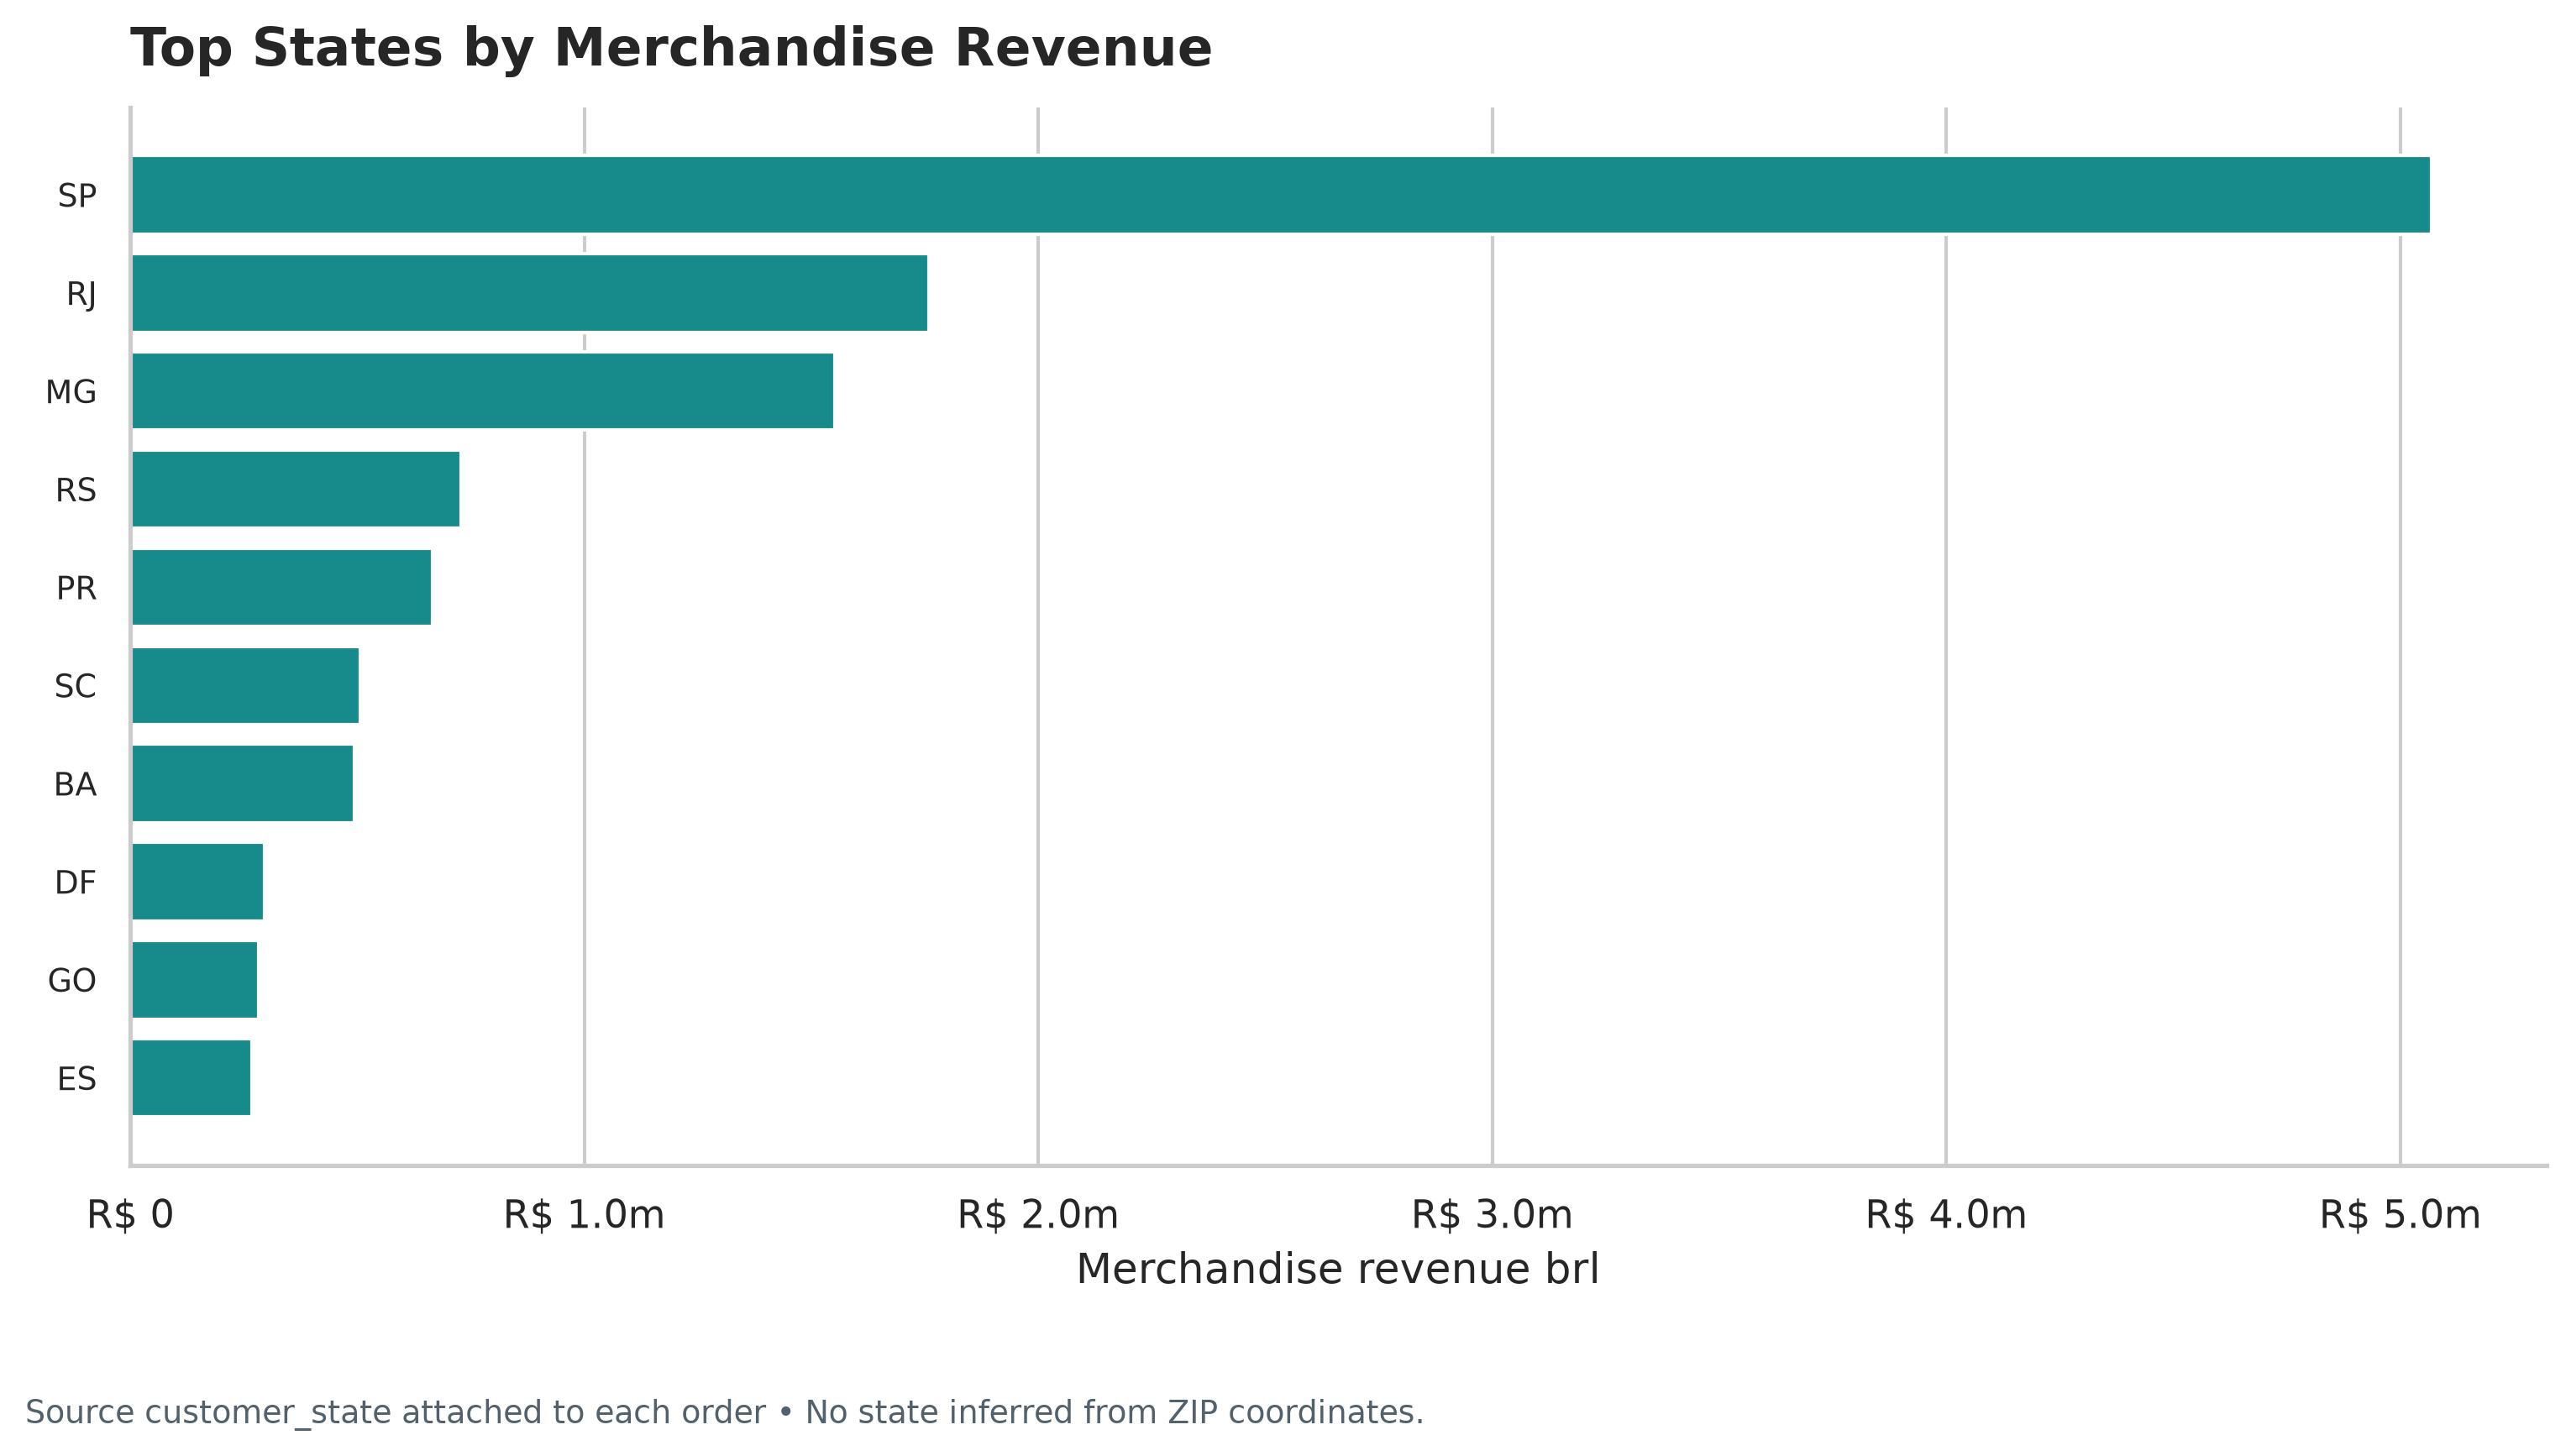

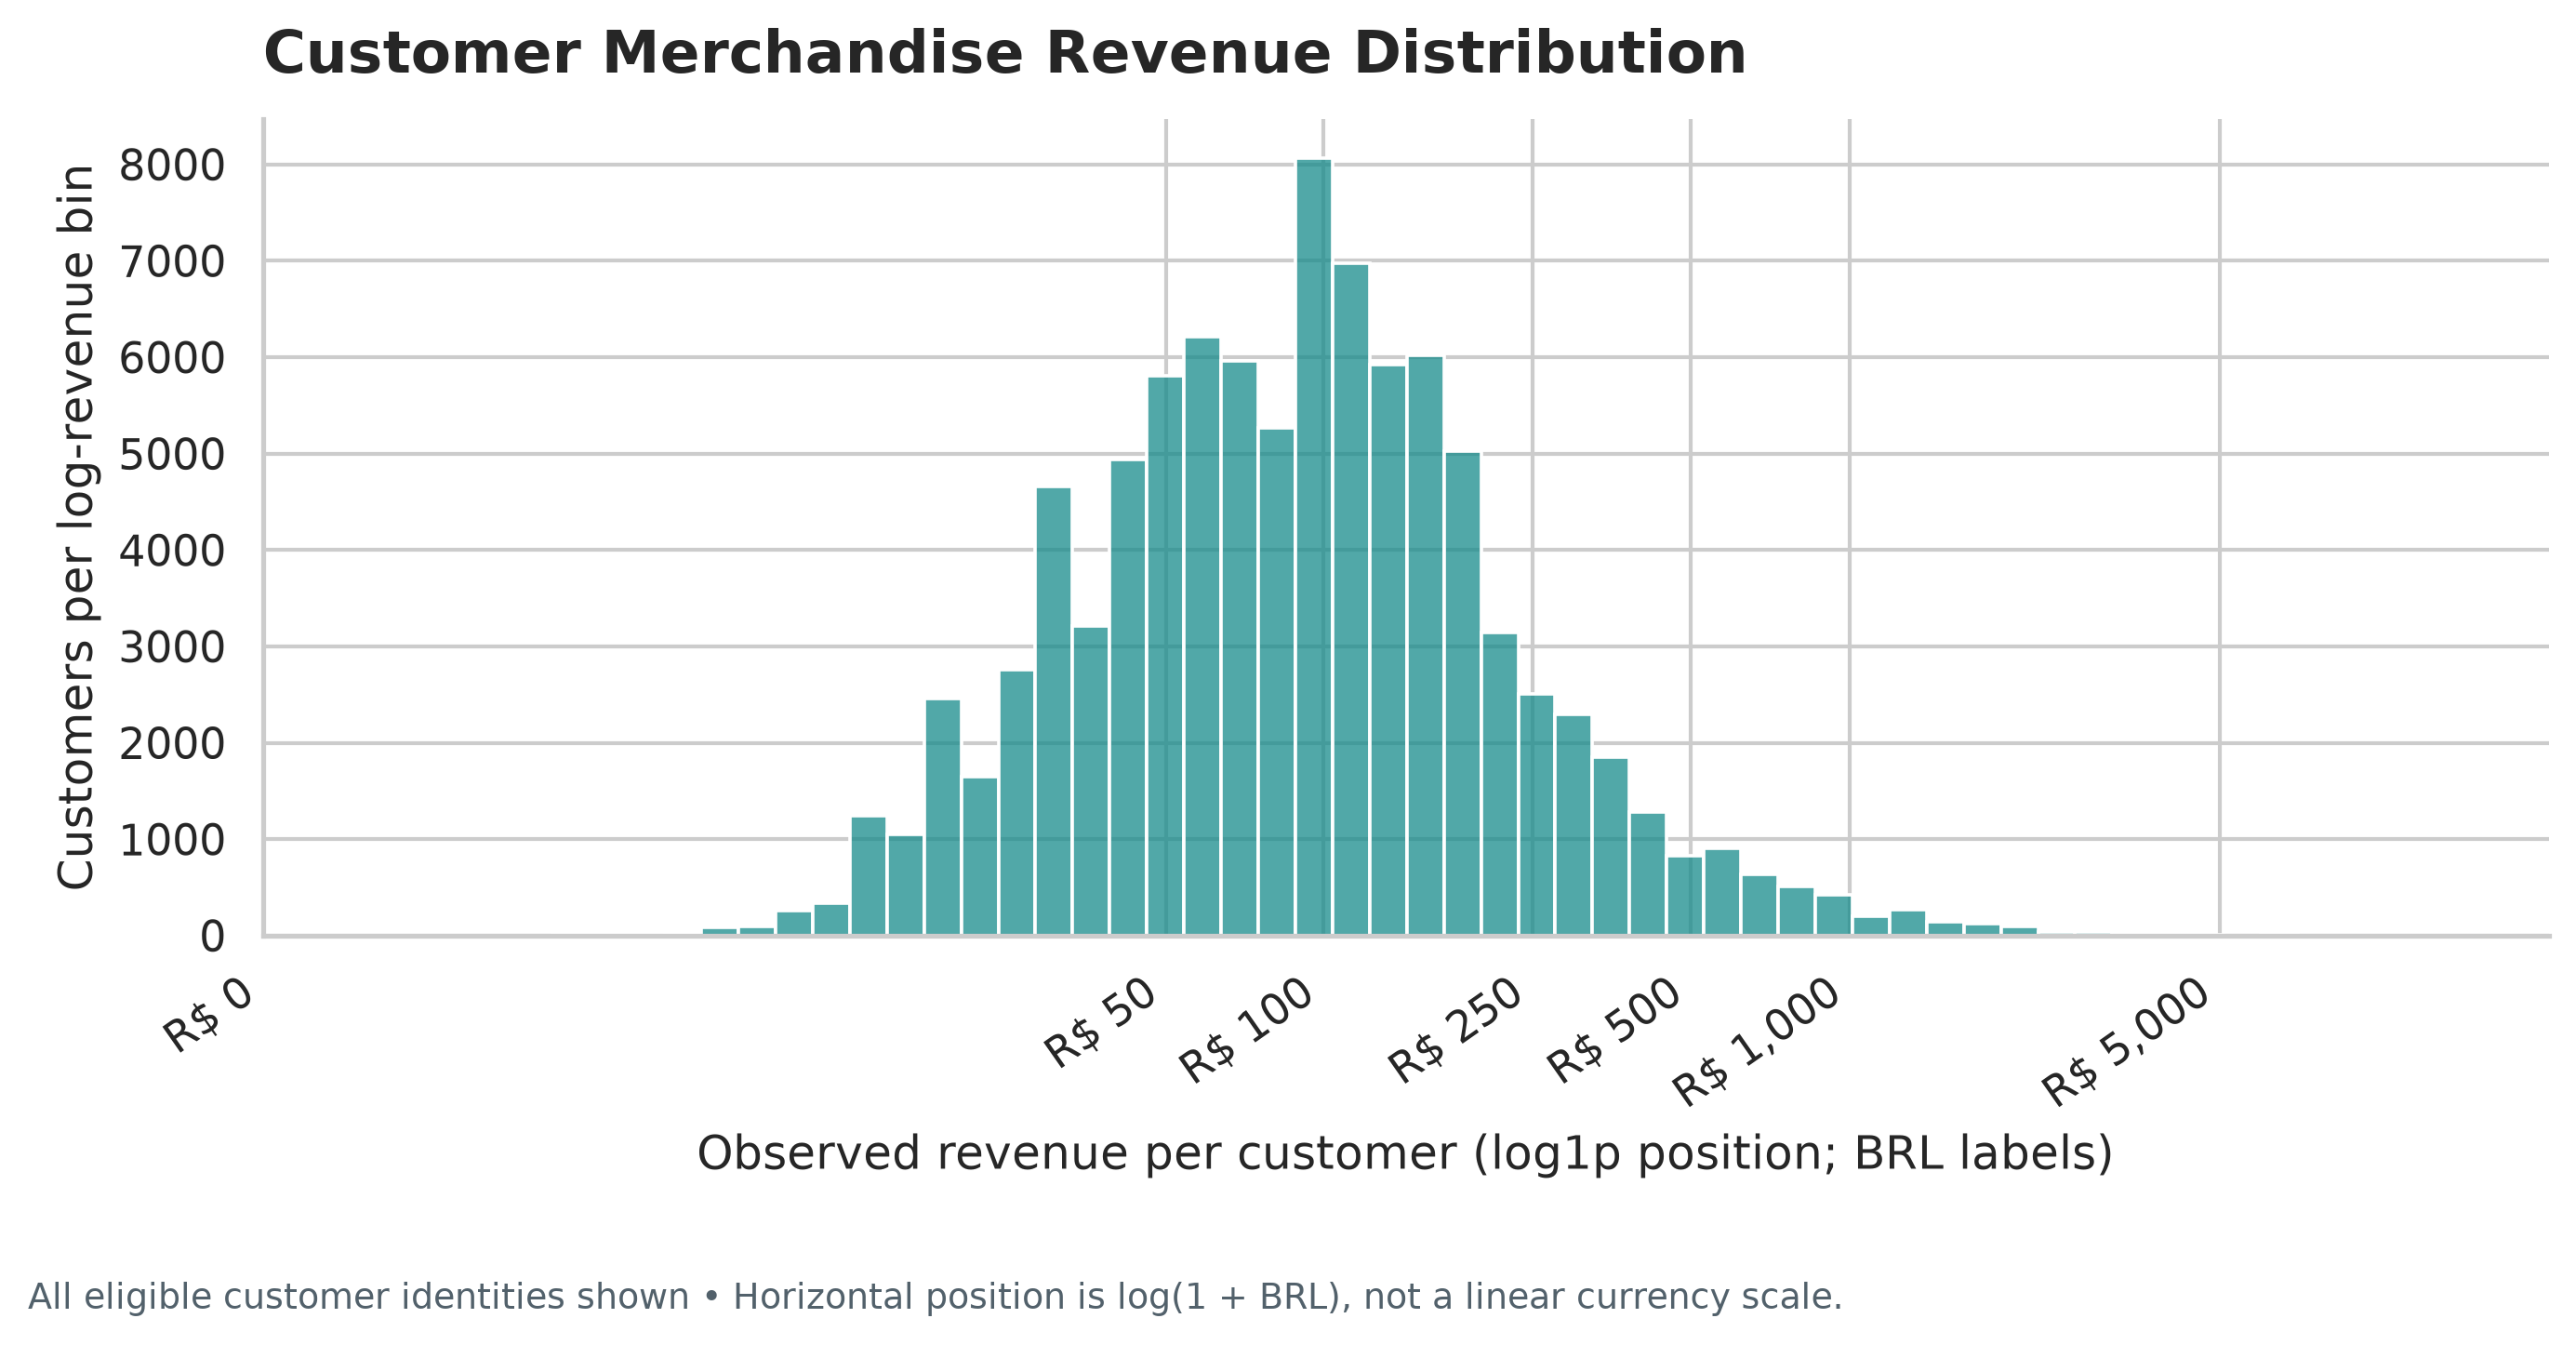

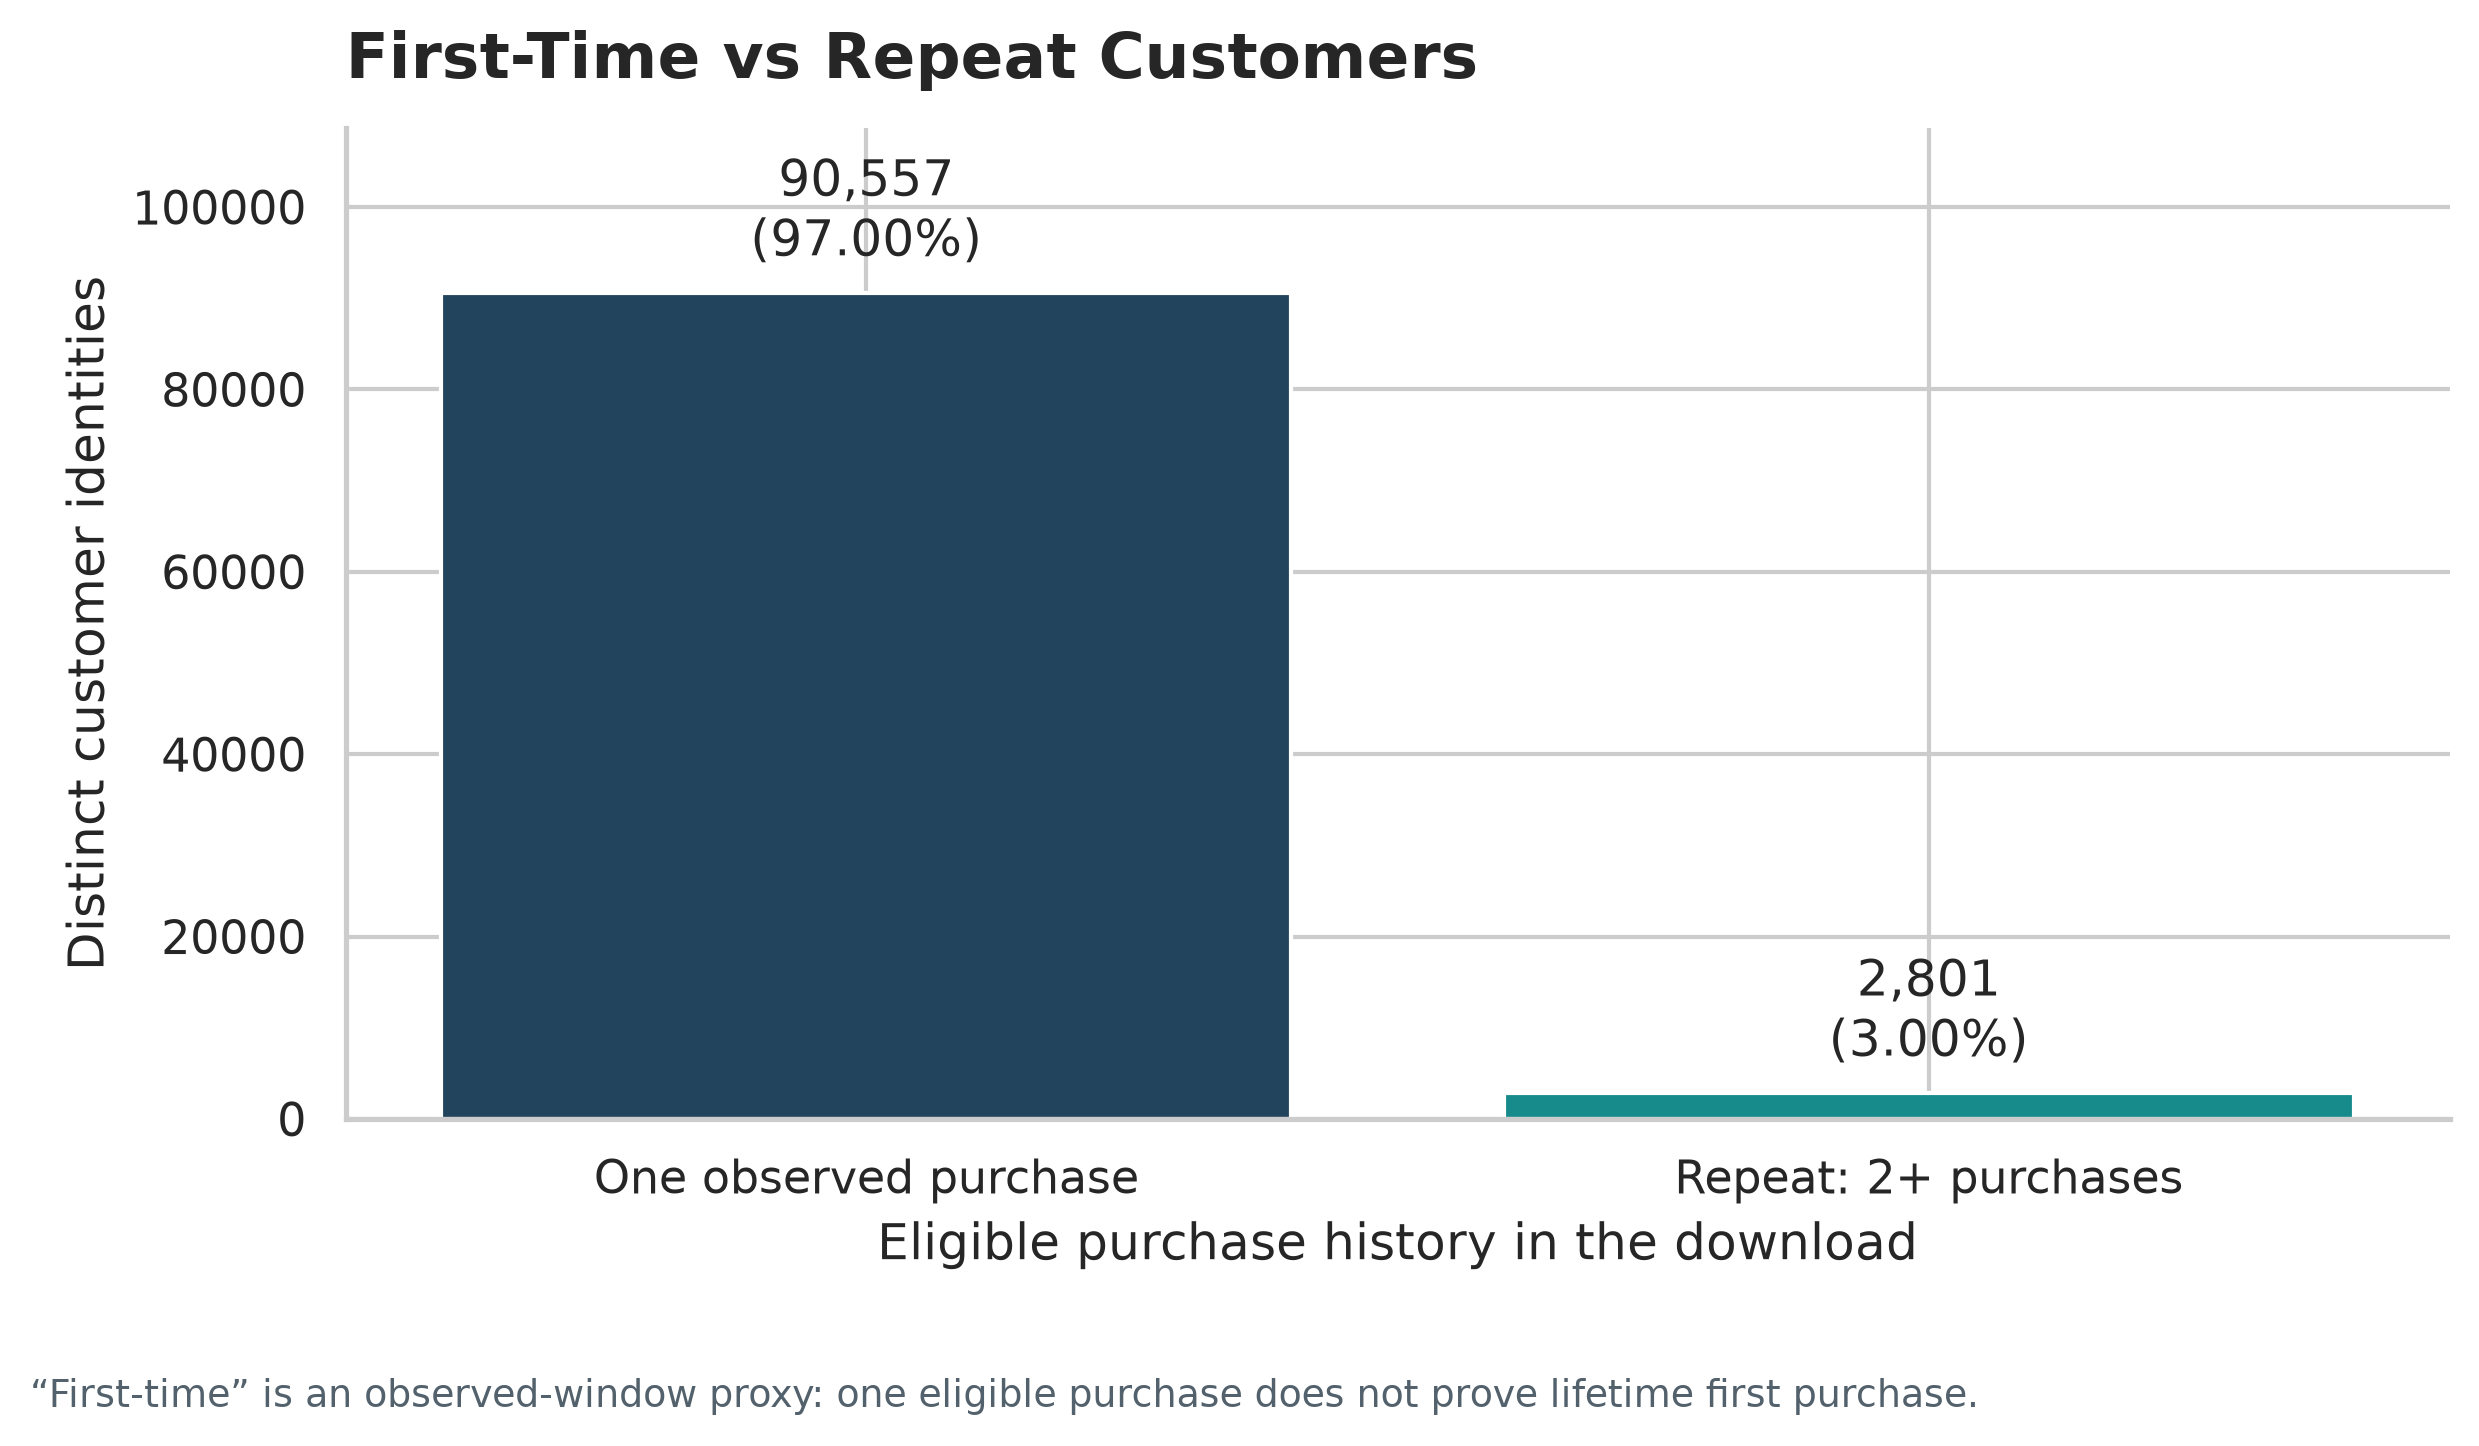

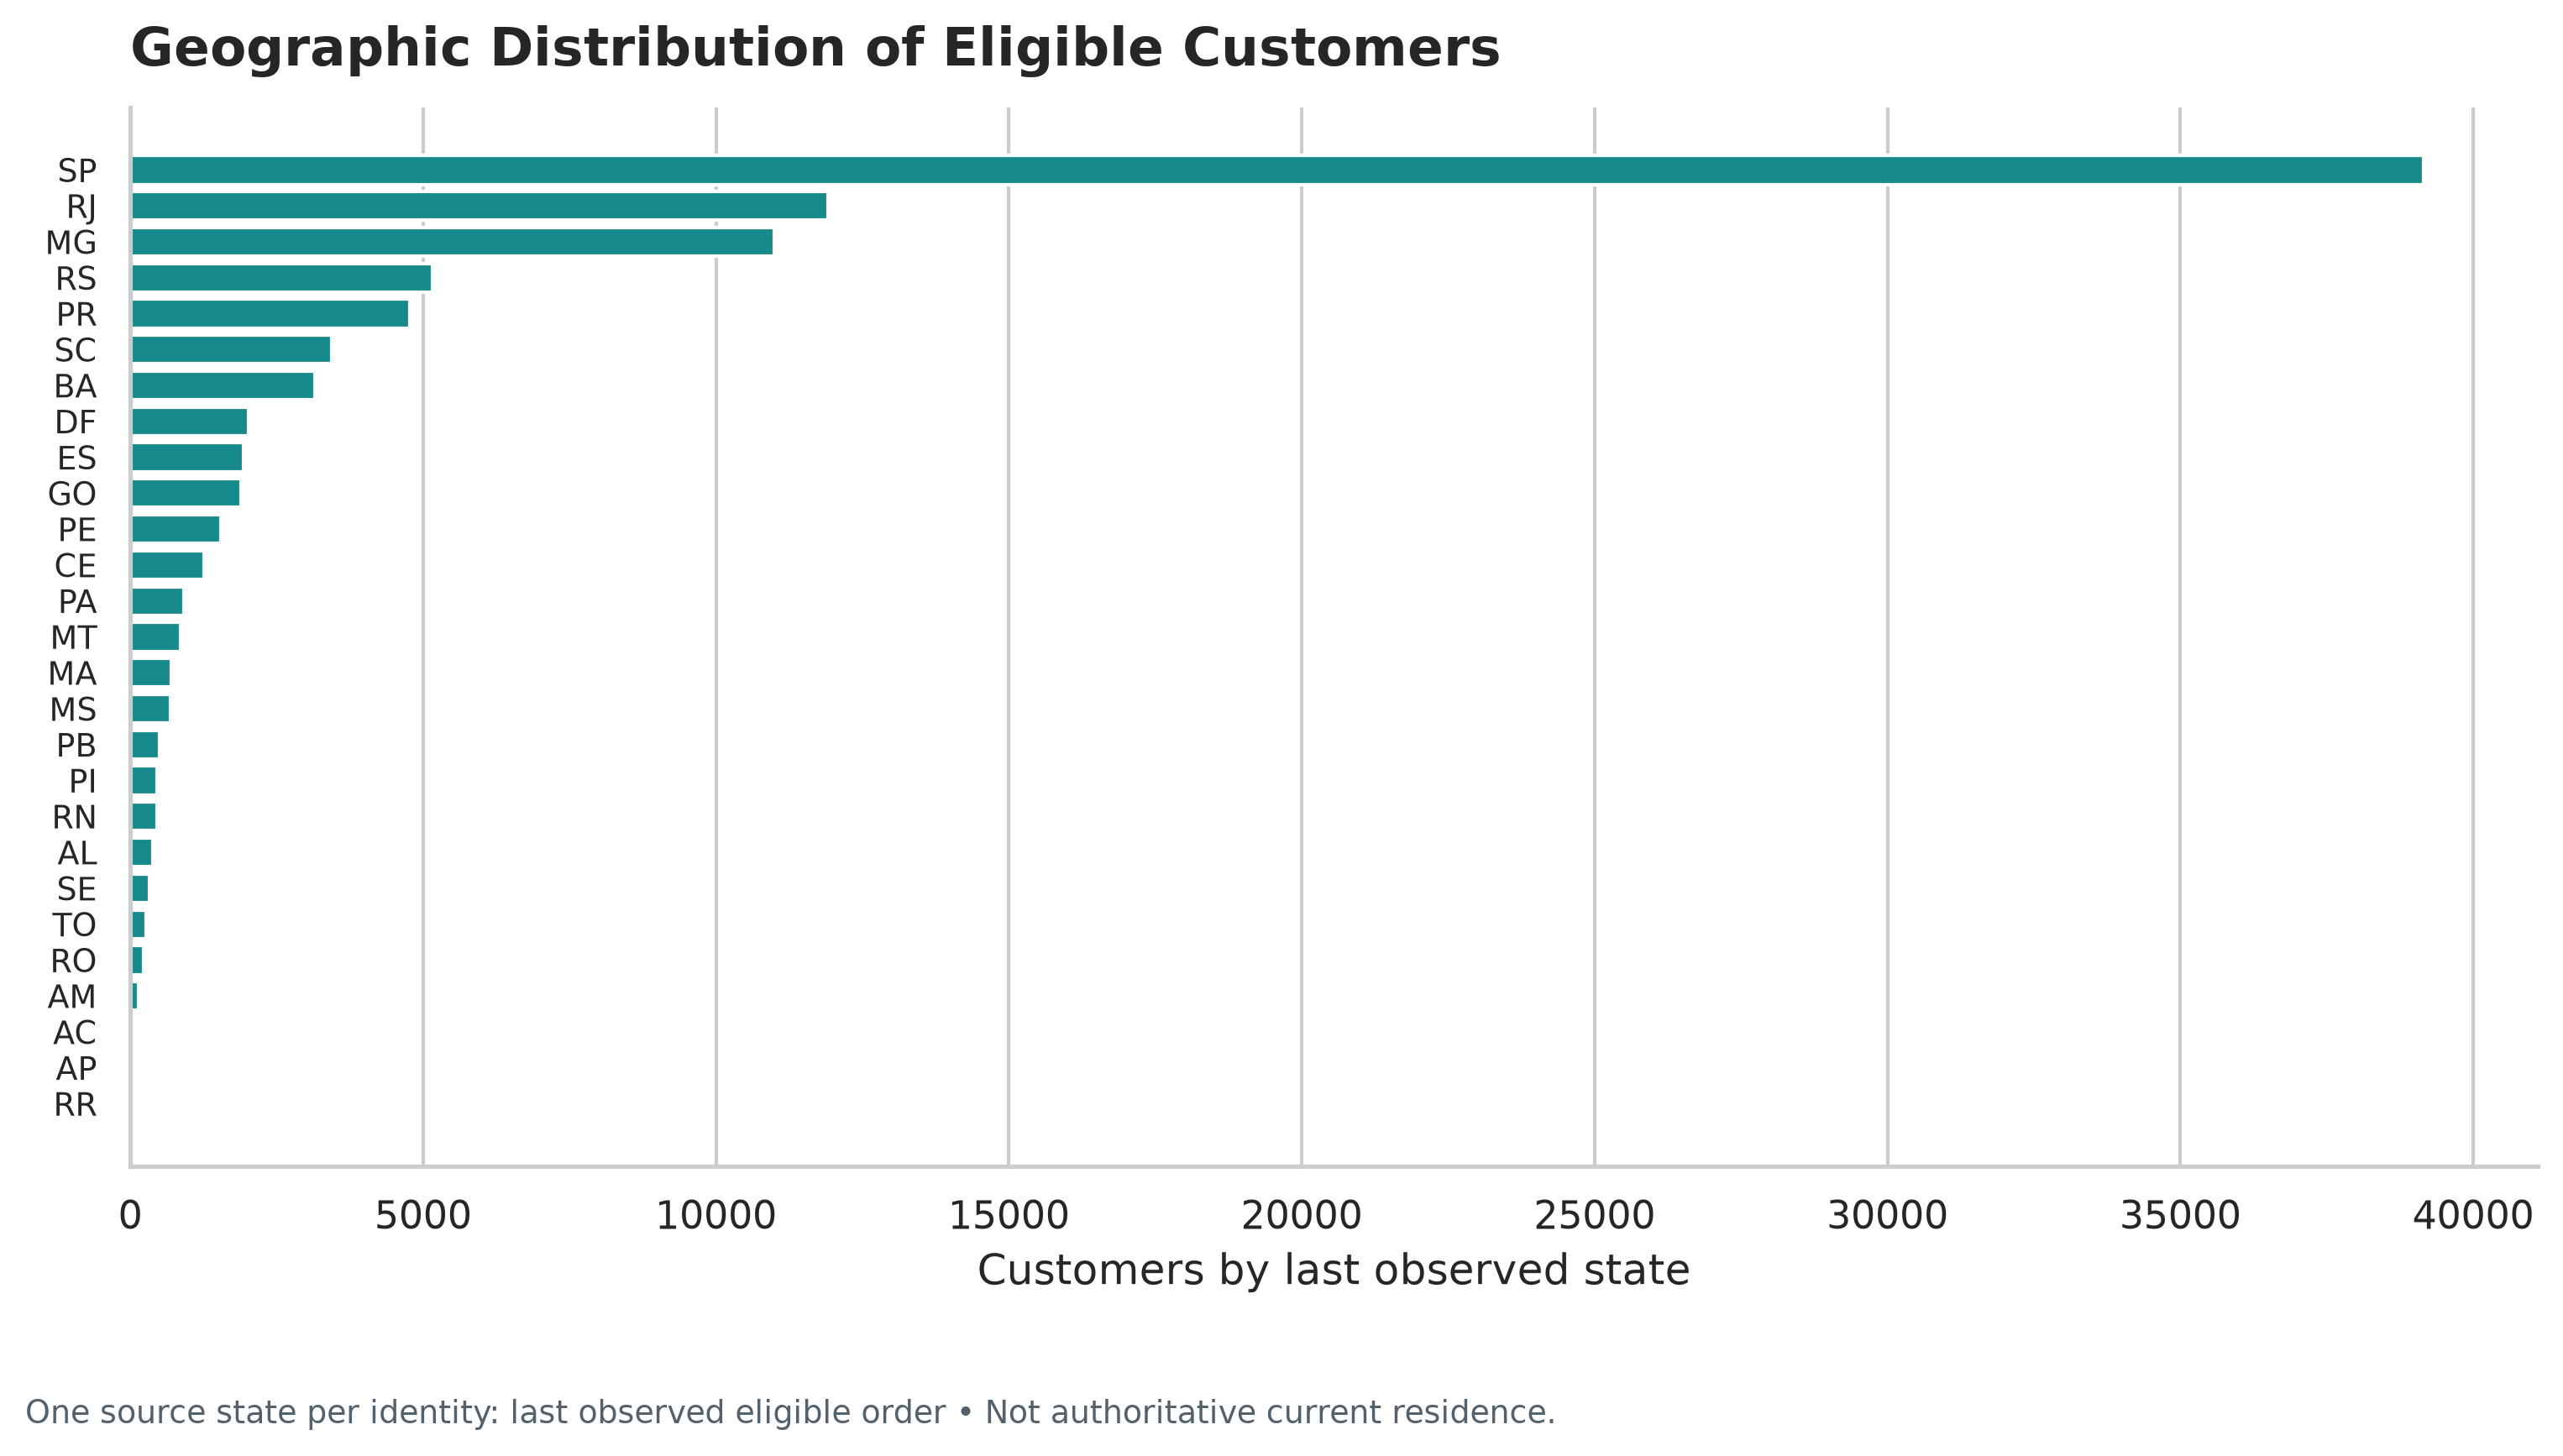

In [6]:
display(analysis["frequency"])
display(analysis["customers"].head(10))
display(analysis["states"])
display(analysis["customers"]["merchandise_revenue_brl"].describe(percentiles=[.5, .9, .95, .99]))
show_figures({"08", "09", "10", "11", "12"})

## 6. Payments and Order-Level Reconciliation

Payment methods and installments are payment-record analyses, not counts of unique orders. Orders may have multiple payment sequences and types. The report labels each view and denominator. Installments are shown for all methods in the table and credit-card records in the chart; non-positive values are retained and flagged.

Order-level payment totals are compared with order-level merchandise plus freight only where both exist. Missing item/payment records do not become invented zero amounts. Preserve differences and investigate them; do not require total payments to equal merchandise revenue or force recorded differences to zero. All-source payment totals are context and are labelled separately from eligible sales payments.

,analysis_type,group,population,payment_transactions,distinct_orders,recorded_payment_cents,recorded_payment_brl,payment_transaction_denominator,payment_transaction_share_pct,nonpositive_installment_records,...,orders_with_items,orders_with_payments,comparable_orders,noncomparable_orders,merchandise_revenue_cents,freight_cents,exactly_reconciled_orders,payment_above_items_and_freight_orders,payment_below_items_and_freight_orders,comparable_payment_difference_cents
0,scope_summary,all recorded payments,all source order statuses,103886.0,99440.0,1600887212,16008872.12,103886.0,100.000000,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,scope_summary,eligible sales payments,eligible delivered sales,100756.0,96477.0,1542246177,15422461.77,100756.0,100.000000,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,payment_type,boleto,eligible delivered sales,19191.0,19191.0,276993258,2769932.58,100756.0,19.047005,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,payment_type,credit_card,eligible delivered sales,74586.0,74304.0,1210109488,12101094.88,100756.0,74.026361,2.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,payment_type,debit_card,eligible delivered sales,1486.0,1485.0,20842112,208421.12,100756.0,1.474850,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,payment_type,voucher,eligible delivered sales,5493.0,3679.0,34301319,343013.19,100756.0,5.451785,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,analysis_type,group,population,payment_transactions,distinct_orders,recorded_payment_cents,recorded_payment_brl,payment_transaction_denominator,payment_transaction_share_pct,nonpositive_installment_records,...,orders_with_items,orders_with_payments,comparable_orders,noncomparable_orders,merchandise_revenue_cents,freight_cents,exactly_reconciled_orders,payment_above_items_and_freight_orders,payment_below_items_and_freight_orders,comparable_payment_difference_cents
54,payment_types_per_order,0,eligible delivered sales orders,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
55,payment_types_per_order,1,eligible delivered sales orders,NaN,NaN,1509786629,15097866.29,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
56,payment_types_per_order,2,eligible delivered sales orders,NaN,NaN,32459548,324595.48,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
57,payment_transactions_per_order,0,eligible delivered sales orders,NaN,NaN,<NA>,<NA>,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
58,payment_transactions_per_order,1,eligible delivered sales orders,NaN,NaN,1495075893,14950758.93,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
59,payment_transactions_per_order,2,eligible delivered sales orders,NaN,NaN,39503008,395030.08,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
60,payment_transactions_per_order,3,eligible delivered sales orders,NaN,NaN,3744248,37442.48,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
61,payment_transactions_per_order,4,eligible delivered sales orders,NaN,NaN,1077622,10776.22,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
62,payment_transactions_per_order,5,eligible delivered sales orders,NaN,NaN,671172,6711.72,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
63,payment_transactions_per_order,6,eligible delivered sales orders,NaN,NaN,647032,6470.32,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,analysis_type,group,population,payment_transactions,distinct_orders,recorded_payment_cents,recorded_payment_brl,payment_transaction_denominator,payment_transaction_share_pct,nonpositive_installment_records,...,orders_with_items,orders_with_payments,comparable_orders,noncomparable_orders,merchandise_revenue_cents,freight_cents,exactly_reconciled_orders,payment_above_items_and_freight_orders,payment_below_items_and_freight_orders,comparable_payment_difference_cents
77,order_reconciliation_by_status,approved,all source order statuses,NaN,NaN,24108,241.08,NaN,NaN,NaN,...,2.0,2.0,2.0,0.0,20960,3148,2.0,0.0,0.0,0
78,order_reconciliation_by_status,canceled,all source order statuses,NaN,NaN,14325560,143255.6,NaN,NaN,NaN,...,461.0,625.0,461.0,164.0,9523527,1065045,459.0,2.0,0.0,3201
79,order_reconciliation_by_status,created,all source order statuses,NaN,NaN,68810,688.1,NaN,NaN,NaN,...,0.0,5.0,0.0,5.0,<NA>,<NA>,0.0,0.0,0.0,<NA>
80,order_reconciliation_by_status,delivered,all source order statuses,NaN,NaN,1542246177,15422461.77,NaN,NaN,NaN,...,96478.0,96477.0,96477.0,1.0,1322149811,219827564,95908.0,362.0,207.0,283148
81,order_reconciliation_by_status,invoiced,all source order statuses,NaN,NaN,6913799,69137.99,NaN,NaN,NaN,...,312.0,314.0,312.0,2.0,6152637,746238,311.0,1.0,0.0,1
82,order_reconciliation_by_status,processing,all source order statuses,NaN,NaN,6939411,69394.11,NaN,NaN,NaN,...,301.0,301.0,301.0,0.0,6043922,895489,301.0,0.0,0.0,0
83,order_reconciliation_by_status,shipped,all source order statuses,NaN,NaN,17721396,177213.96,NaN,NaN,NaN,...,1106.0,1107.0,1106.0,1.0,15072744,2640190,1102.0,2.0,2.0,689
84,order_reconciliation_by_status,unavailable,all source order statuses,NaN,NaN,12647951,126479.51,NaN,NaN,NaN,...,6.0,609.0,6.0,603.0,200769,13280,6.0,0.0,0.0,0


,order_id,payment_sequential,payment_type,payment_installments,payment_value,dq_invalid_payment_installments,dq_invalid_payment_value,dq_negative_payment_value,dq_zero_payment_value,dq_nonpositive_installments,dq_noninteger_payment_installments,payment_value_cents
46982,744bade1fcf9ff3f31d860ace076d422,2,credit_card,0,58.69,False,False,False,False,True,False,5869
79014,1a57108394169c0b47d8f876acc9ba2d,2,credit_card,0,129.94,False,False,False,False,True,False,12994


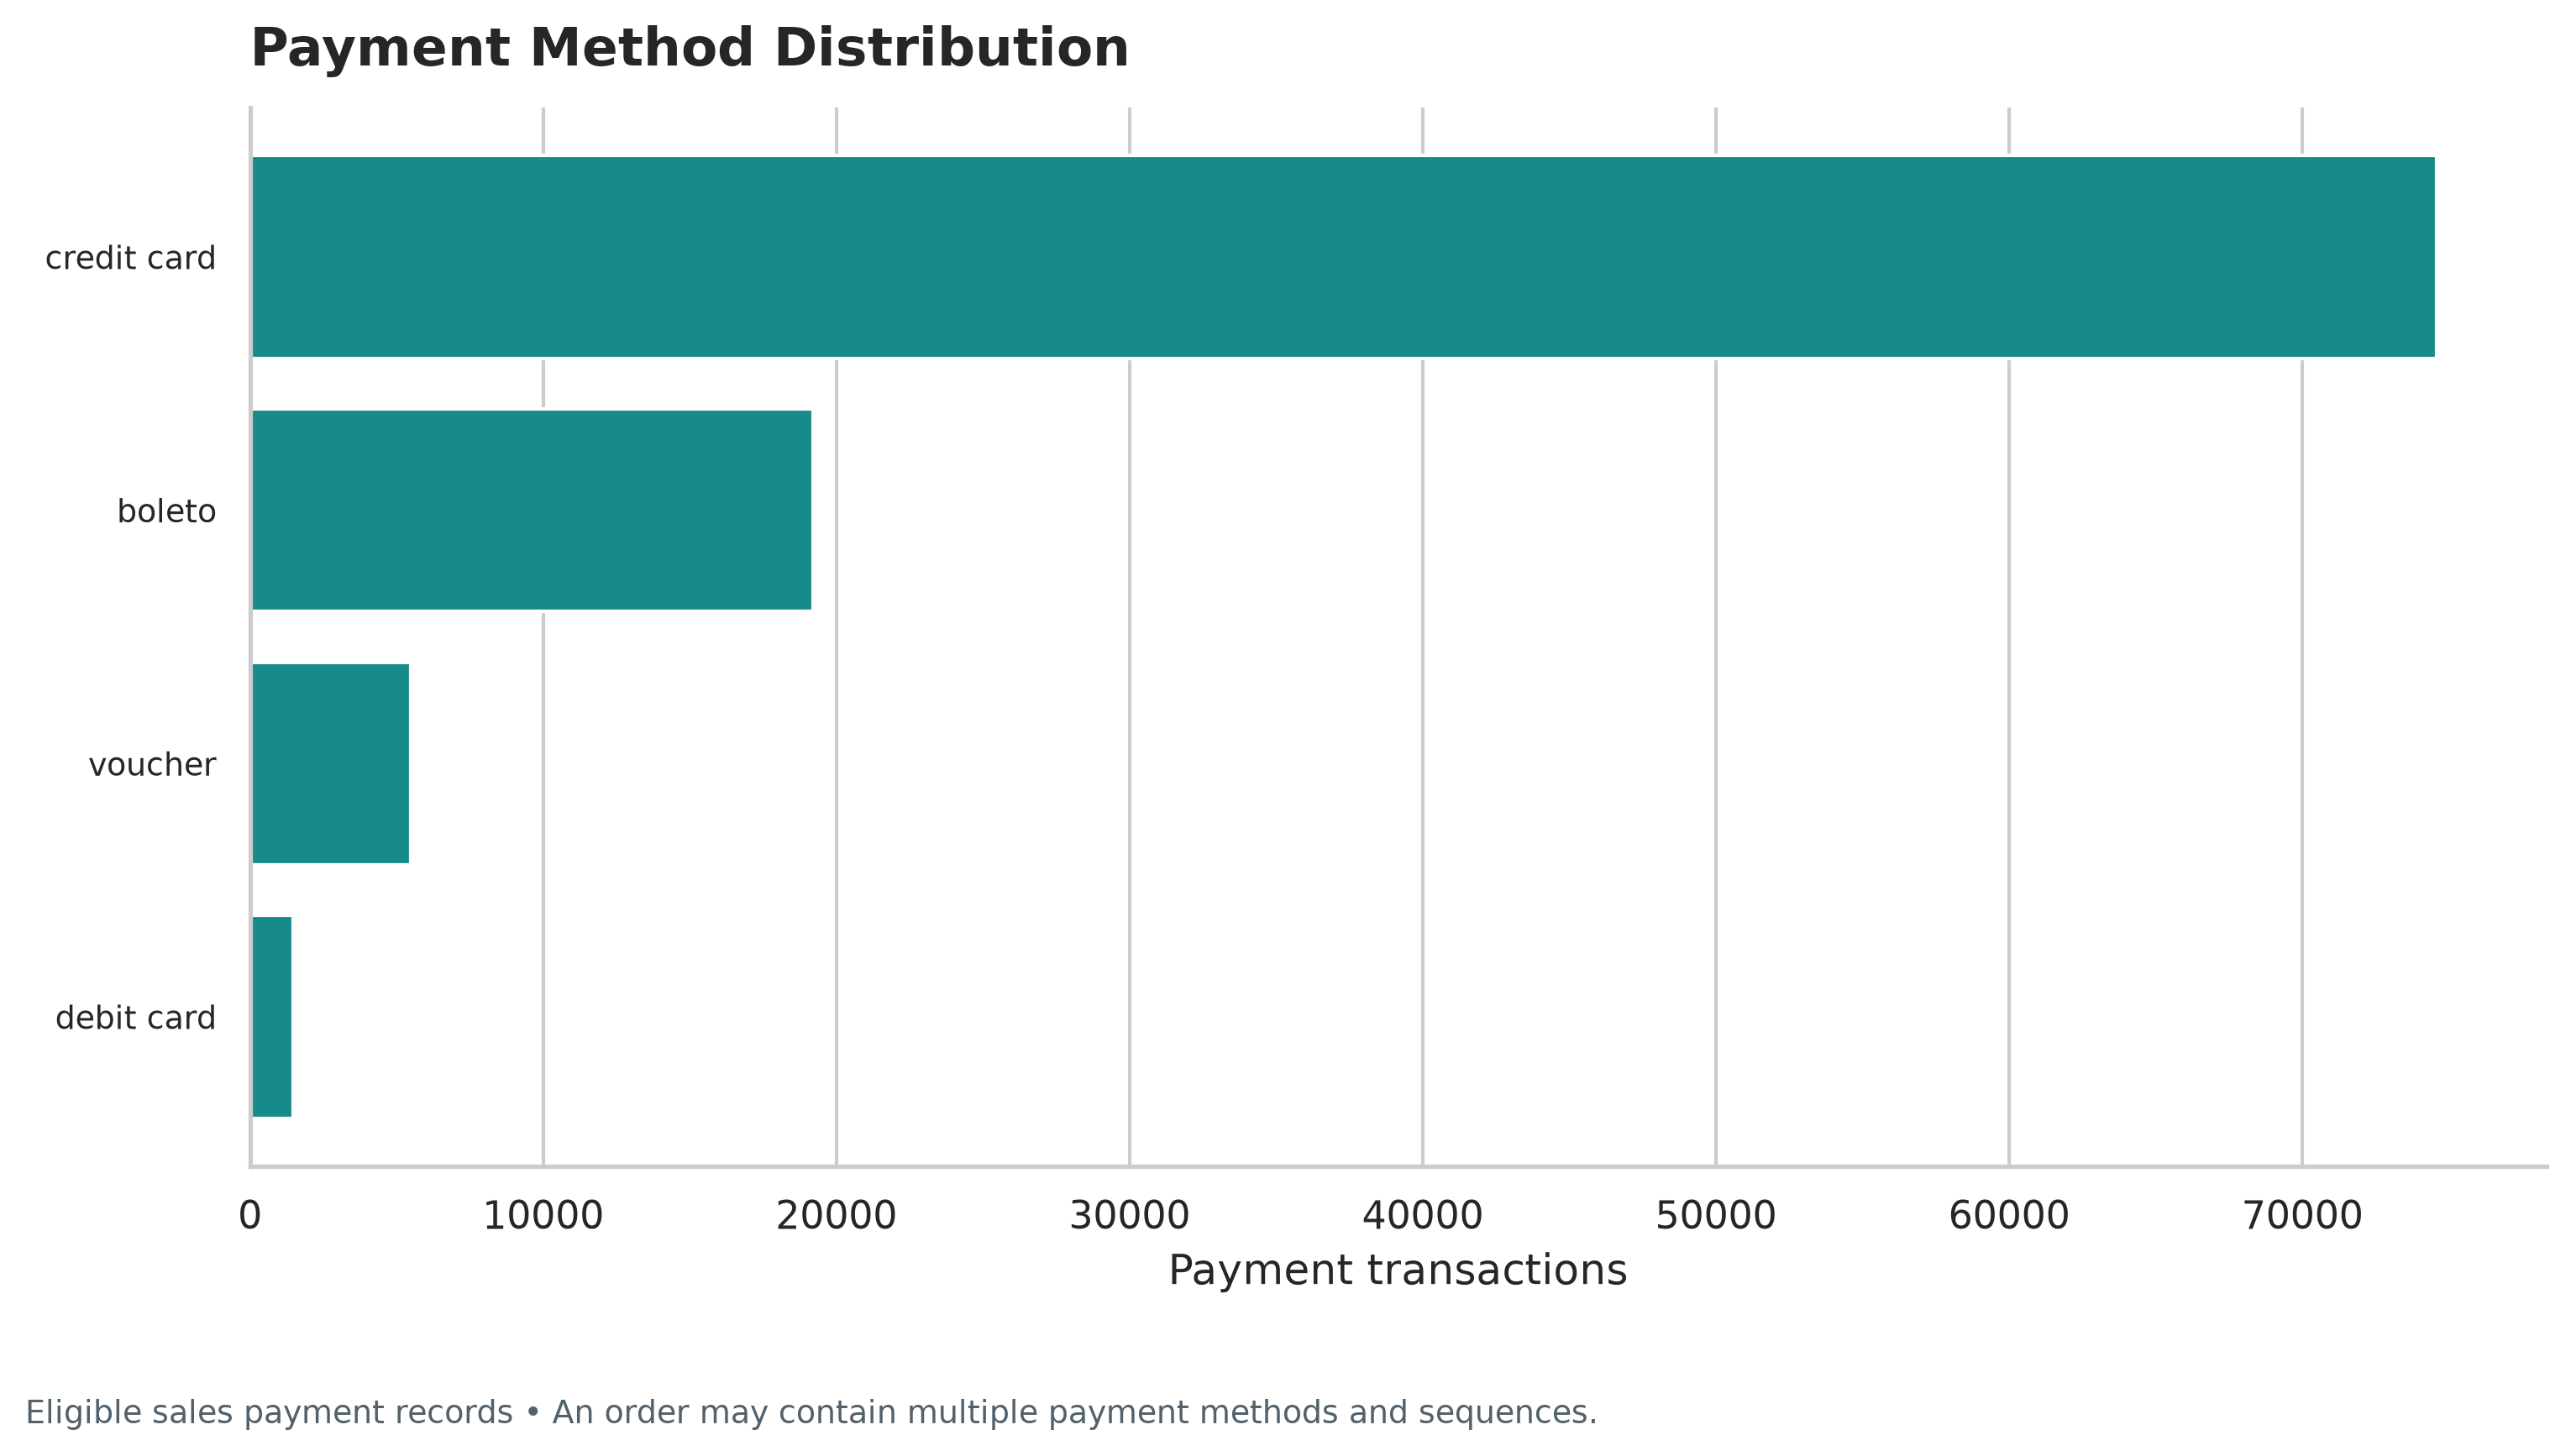

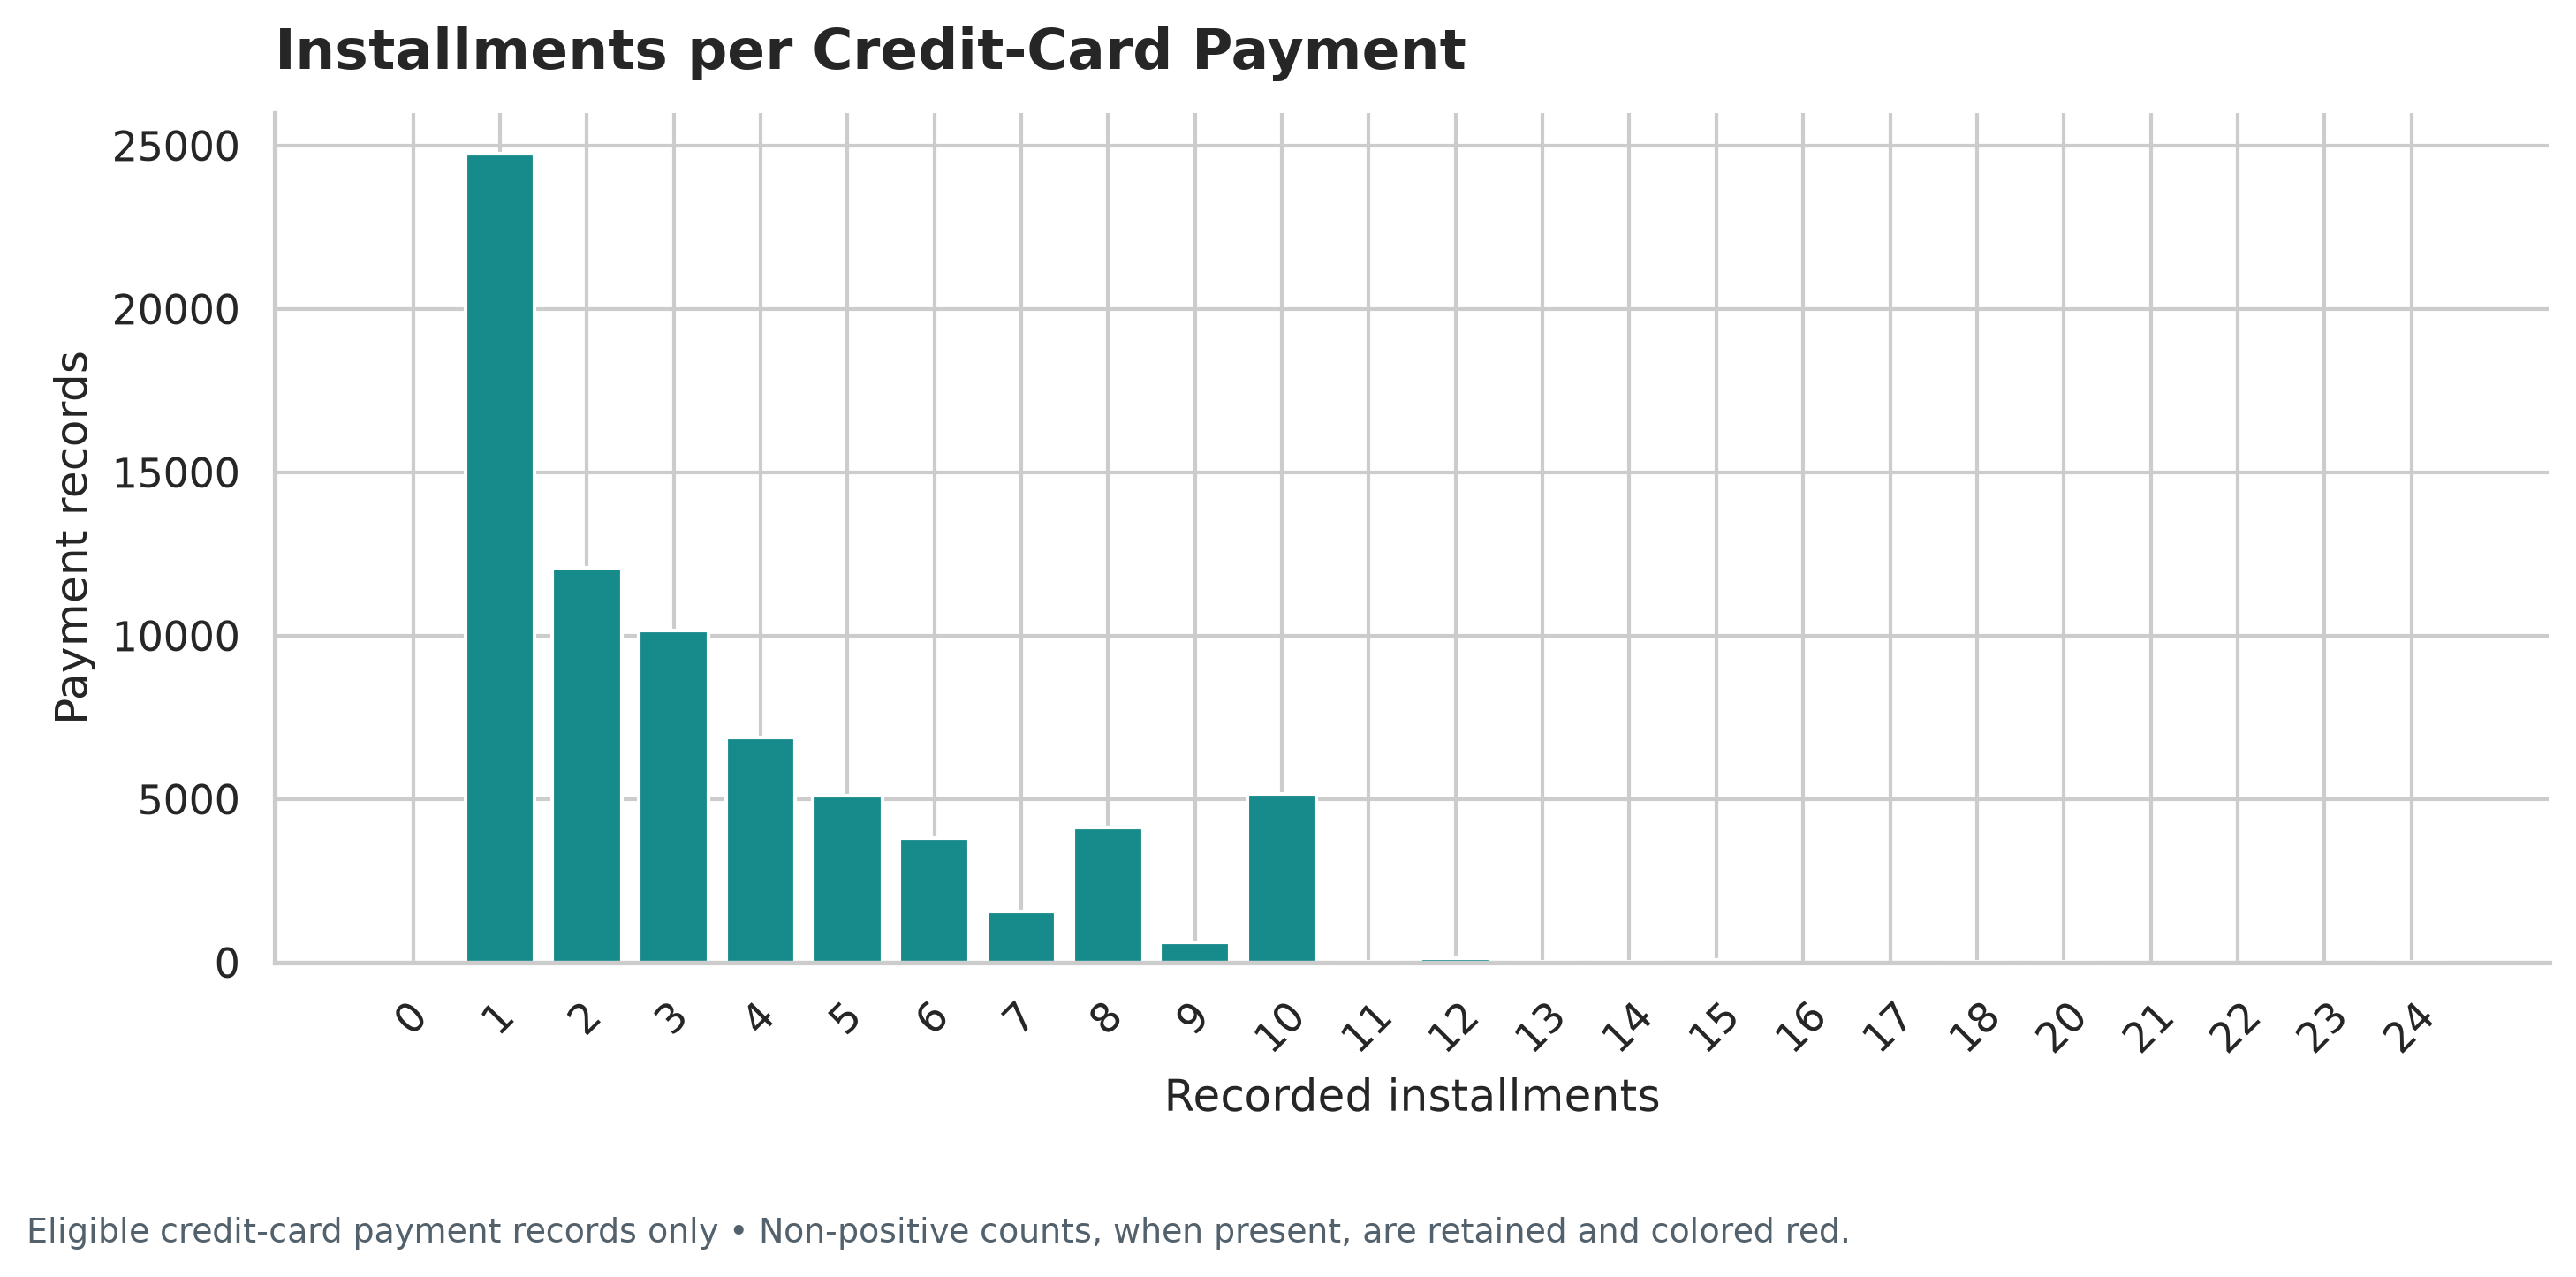

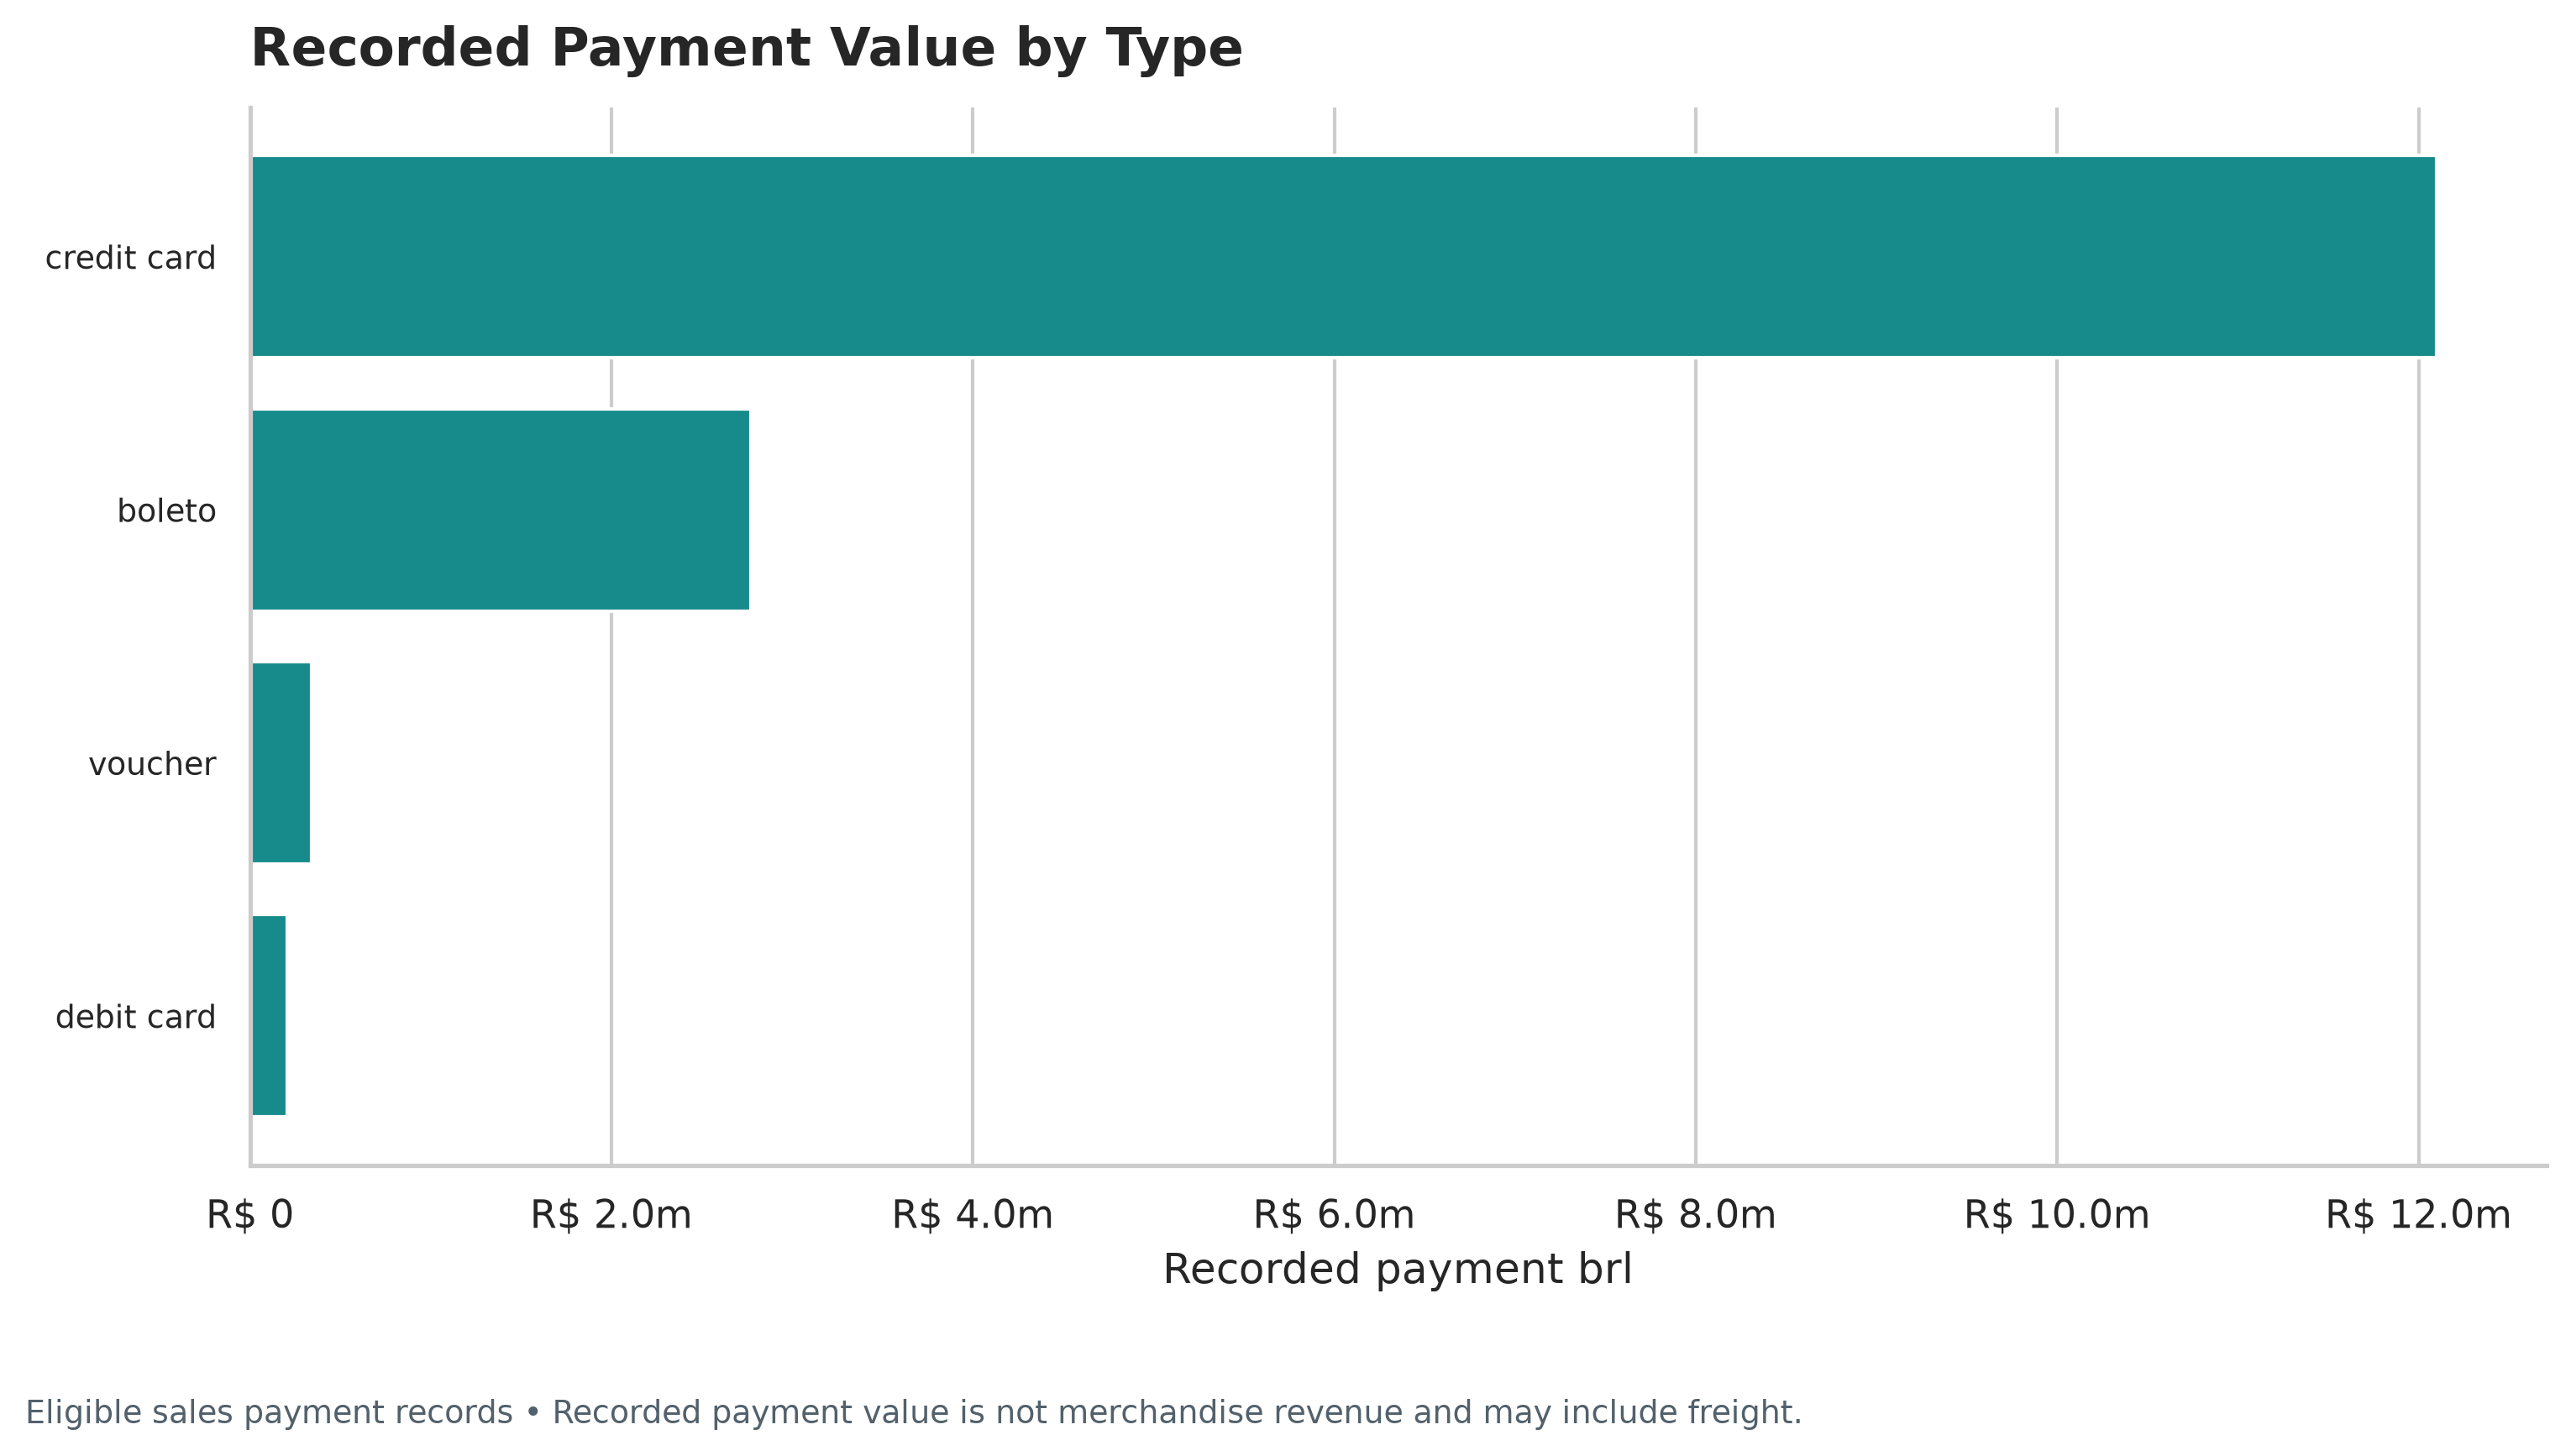

In [7]:
display(analysis["payments"].loc[analysis["payments"]["analysis_type"].isin(["scope_summary", "payment_type"])])
display(analysis["payments"].loc[analysis["payments"]["analysis_type"].isin(["payment_types_per_order", "payment_transactions_per_order"])])
display(analysis["payments"].loc[analysis["payments"]["analysis_type"].eq("order_reconciliation_by_status")])
display(analysis["data"]["payments"].loc[analysis["data"]["payments"]["payment_installments"].le(0)])
show_figures({"13", "14", "15"})

## 7. Delivery Performance

Only delivered-status orders count as delivered; canceled orders with delivery timestamps are excluded. Calendar-date comparison is the primary on-time rule, so delivery during the estimated day is on time. Signed delay equals actual date minus estimated date.

The on-time denominator requires actual and estimated dates only. Duration requires purchase and actual endpoints plus no known purchase/approval/carrier/delivery ordering contradiction. Missing intermediate milestones alone do not invalidate an available end-to-end interval. Duration exclusions are not applied to sales or on-time classification. No source rows are removed. Every state reports separate on-time, duration and freight denominators.

,customer_state,population,delivered_orders,on_time_eligible_orders,on_time_excluded_orders,on_time_orders,late_orders,on_time_rate_pct,late_rate_pct,duration_eligible_orders,...,average_delivery_duration_days,median_delivery_duration_days,p90_delivery_duration_days,average_signed_delay_days,freight_eligible_orders,average_freight_charge_brl,on_time_reviewed_orders,on_time_average_order_review_score,late_reviewed_orders,late_average_order_review_score
0,ALL,order_status == delivered,96478,96470,8,89936,6534,93.2269,6.7731,95097,...,12.6185,10.2718,23.1560,-11.8759,96478,22.7853,89443,4.2906,6381,2.2718
1,AC,order_status == delivered,80,80,0,77,3,96.2500,3.7500,77,...,21.1701,18.3794,31.4195,-20.7250,80,45.5545,77,4.1818,3,1.6667
2,AL,order_status == delivered,397,397,0,312,85,78.5894,21.4106,393,...,24.3781,22.3329,38.7569,-8.7078,397,38.5813,312,4.3045,82,2.1341
3,AM,order_status == delivered,145,145,0,141,4,97.2414,2.7586,144,...,26.4255,25.8623,39.1416,-19.5655,145,37.4457,140,4.3071,4,2.0000
4,AP,order_status == delivered,67,67,0,65,2,97.0149,2.9851,67,...,27.1851,24.3470,34.6647,-19.6866,67,41.2985,64,4.2344,2,4.5000
5,BA,order_status == delivered,3256,3256,0,2860,396,87.8378,12.1622,3210,...,19.3830,16.9521,31.8683,-10.7945,3256,29.9612,2845,4.1425,384,2.3555
6,CE,order_status == delivered,1279,1279,0,1103,176,86.2392,13.7608,1260,...,21.3931,18.2272,34.7359,-10.8045,1279,36.4968,1099,4.2429,174,2.0402
7,DF,order_status == delivered,2080,2080,0,1962,118,94.3269,5.6731,2041,...,13.0535,11.5759,21.8275,-12.0481,2080,23.8581,1952,4.2643,118,1.9746
8,ES,order_status == delivered,1995,1995,0,1781,214,89.2732,10.7268,1968,...,15.8467,13.7114,25.3898,-10.4962,1995,24.5687,1764,4.2619,205,2.5122
9,GO,order_status == delivered,1957,1957,0,1829,128,93.4594,6.5406,1921,...,15.6771,13.9964,24.9685,-12.1855,1957,26.2522,1822,4.2330,124,2.2137


,delay_band,reviewed_orders,average_order_review_score
0,14+ days early,41861,4.3241
1,7–13 days early,33883,4.2996
2,1–6 days early,12419,4.1794
3,On estimated day,1280,4.0355
4,1–3 days late,1852,3.291
5,4–7 days late,1748,2.1055
6,8–14 days late,1446,1.6715
7,15+ days late,1335,1.7258


Canceled orders with delivery timestamps, excluded from delivered metrics: 6


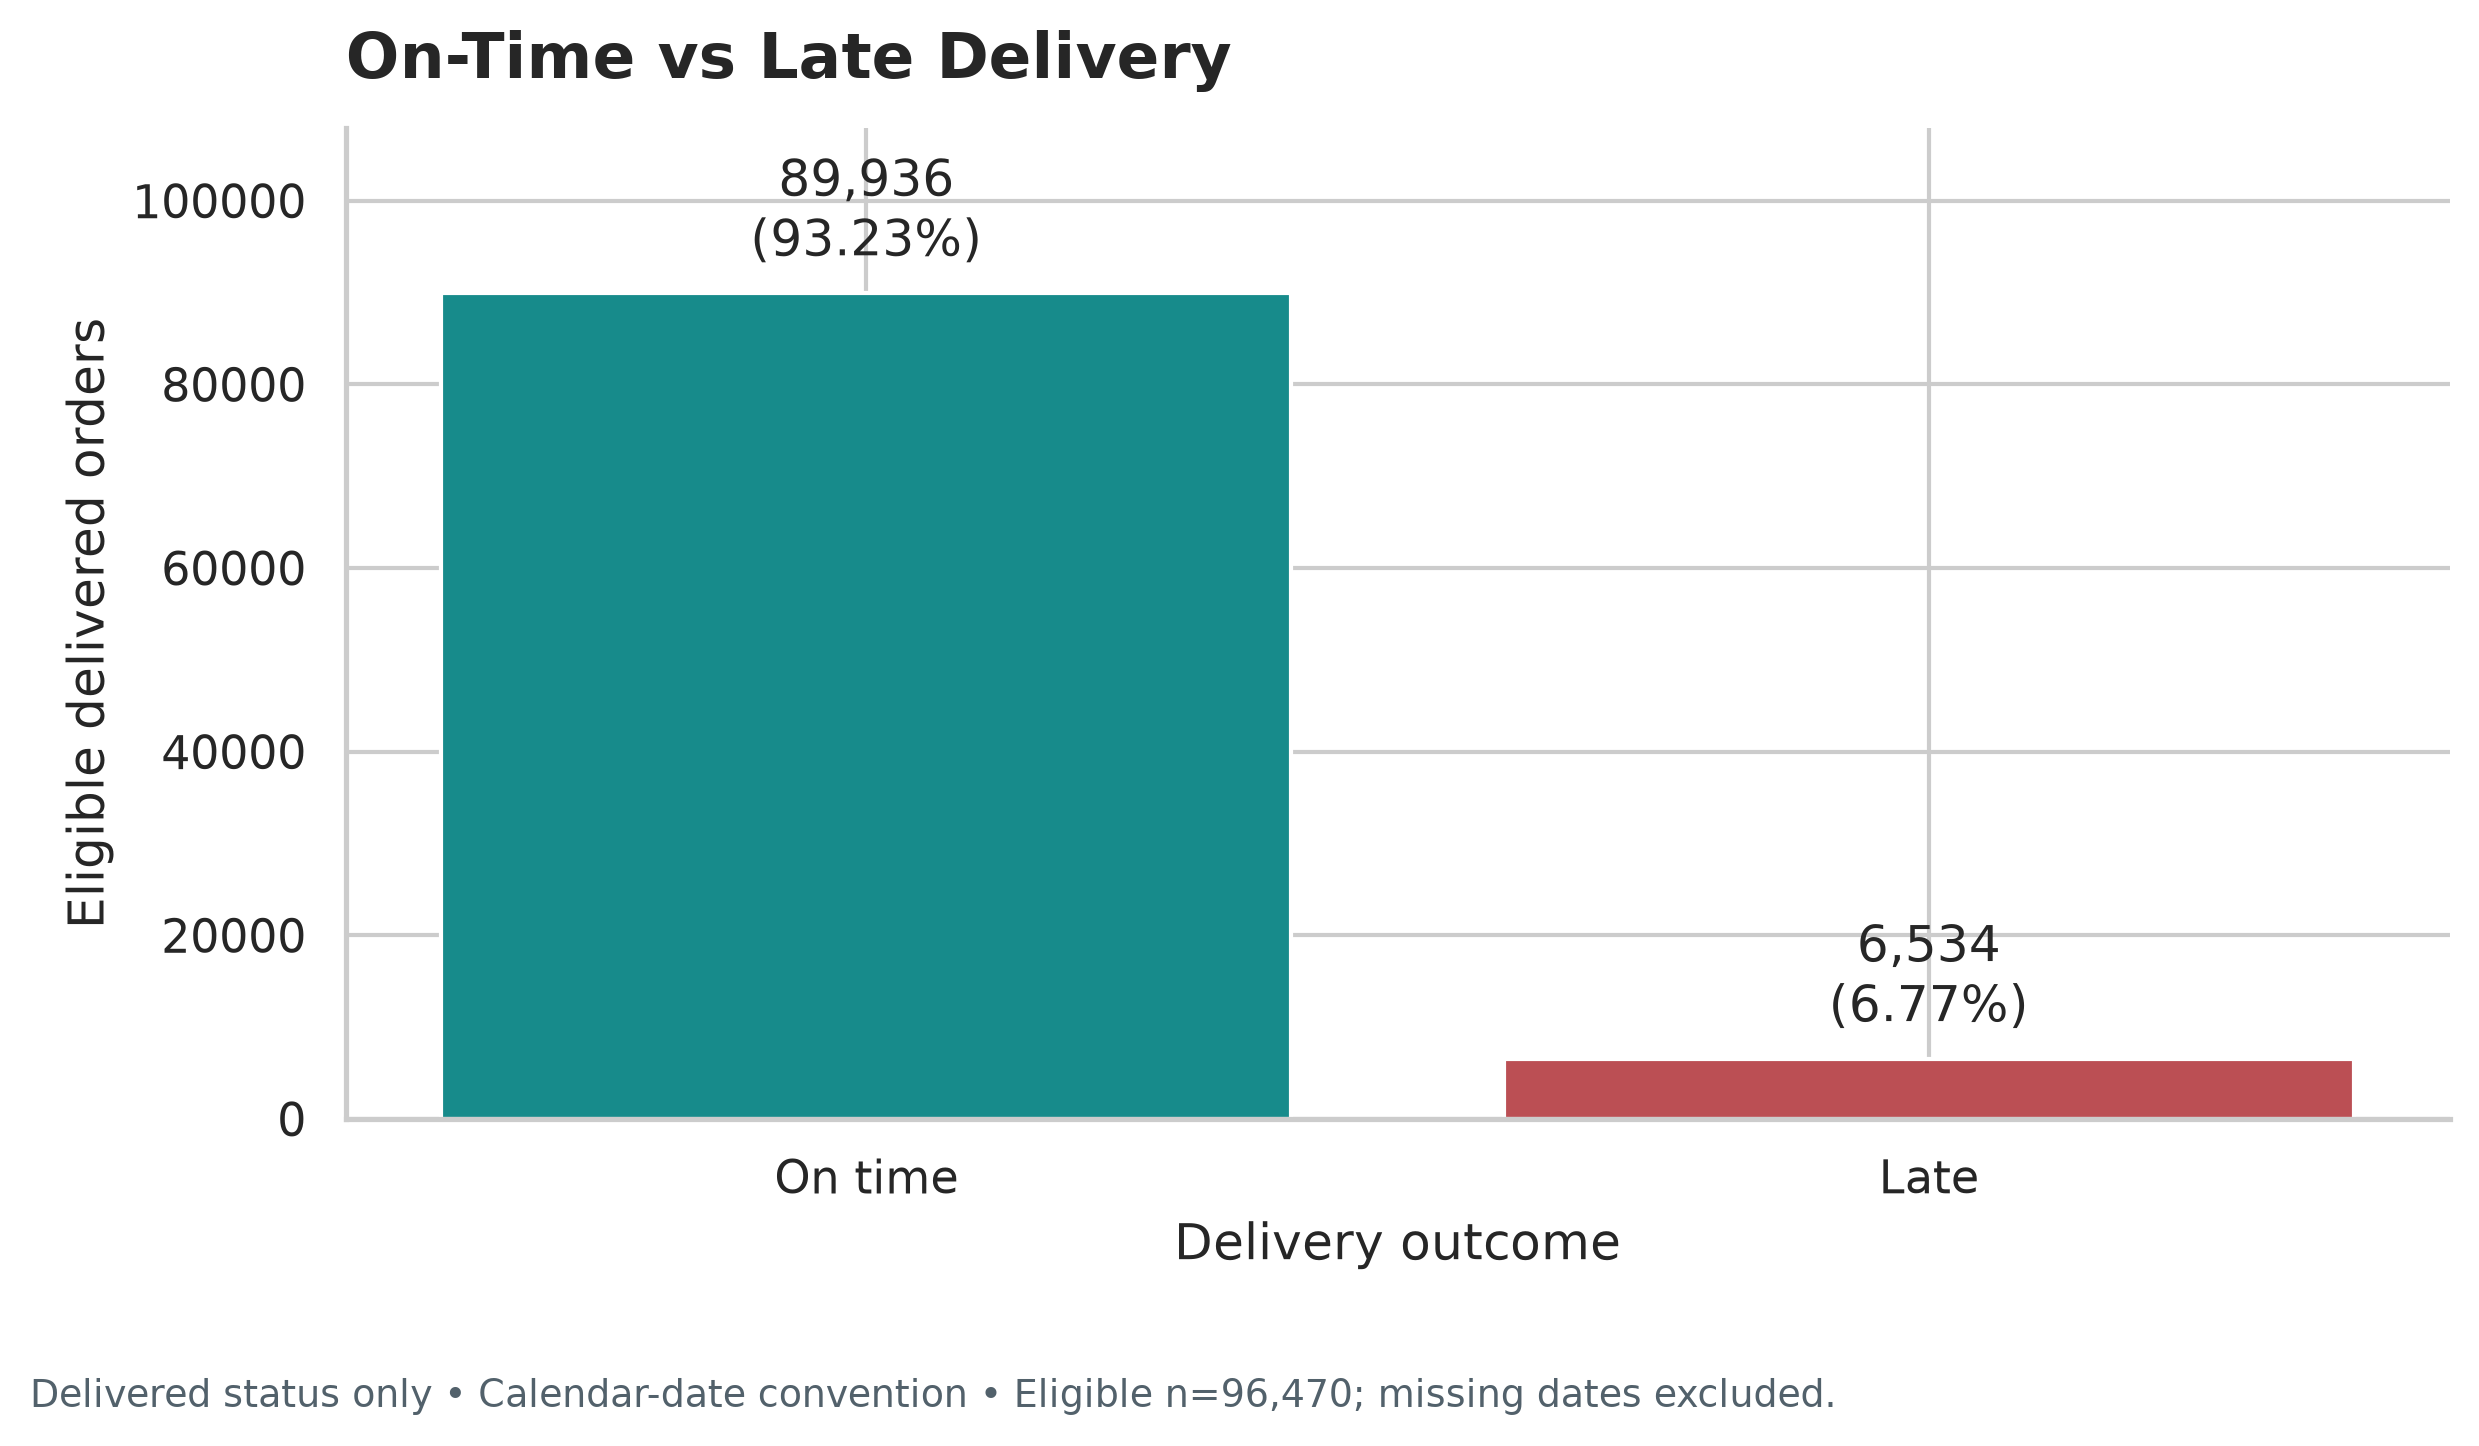

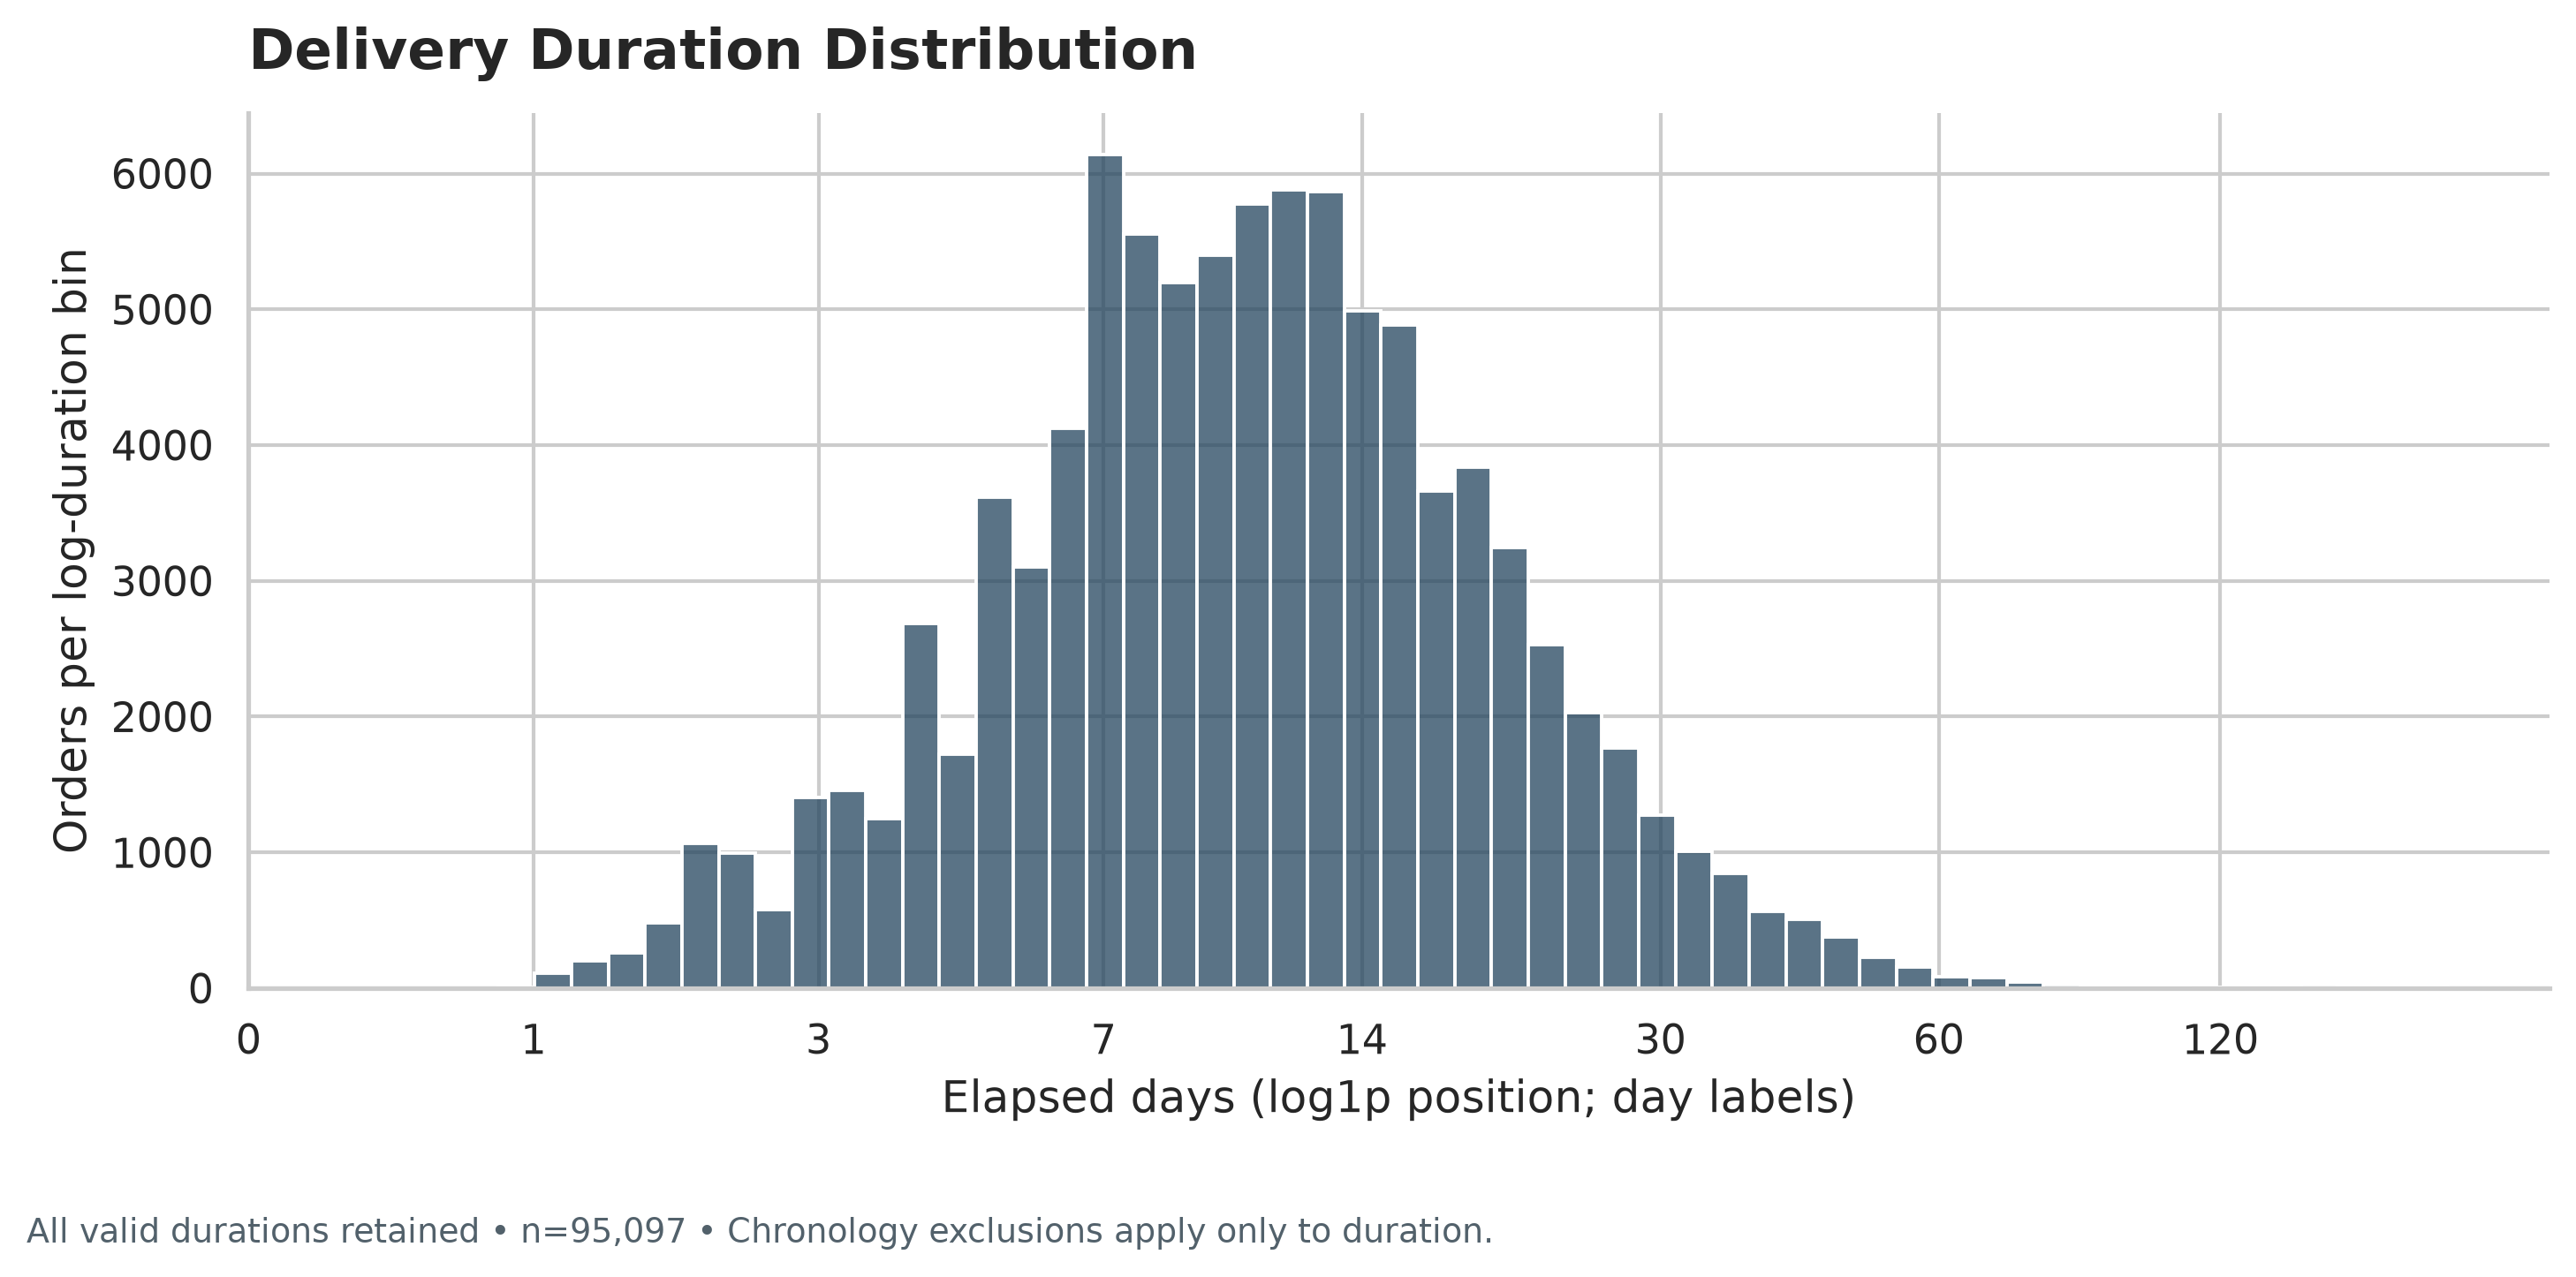

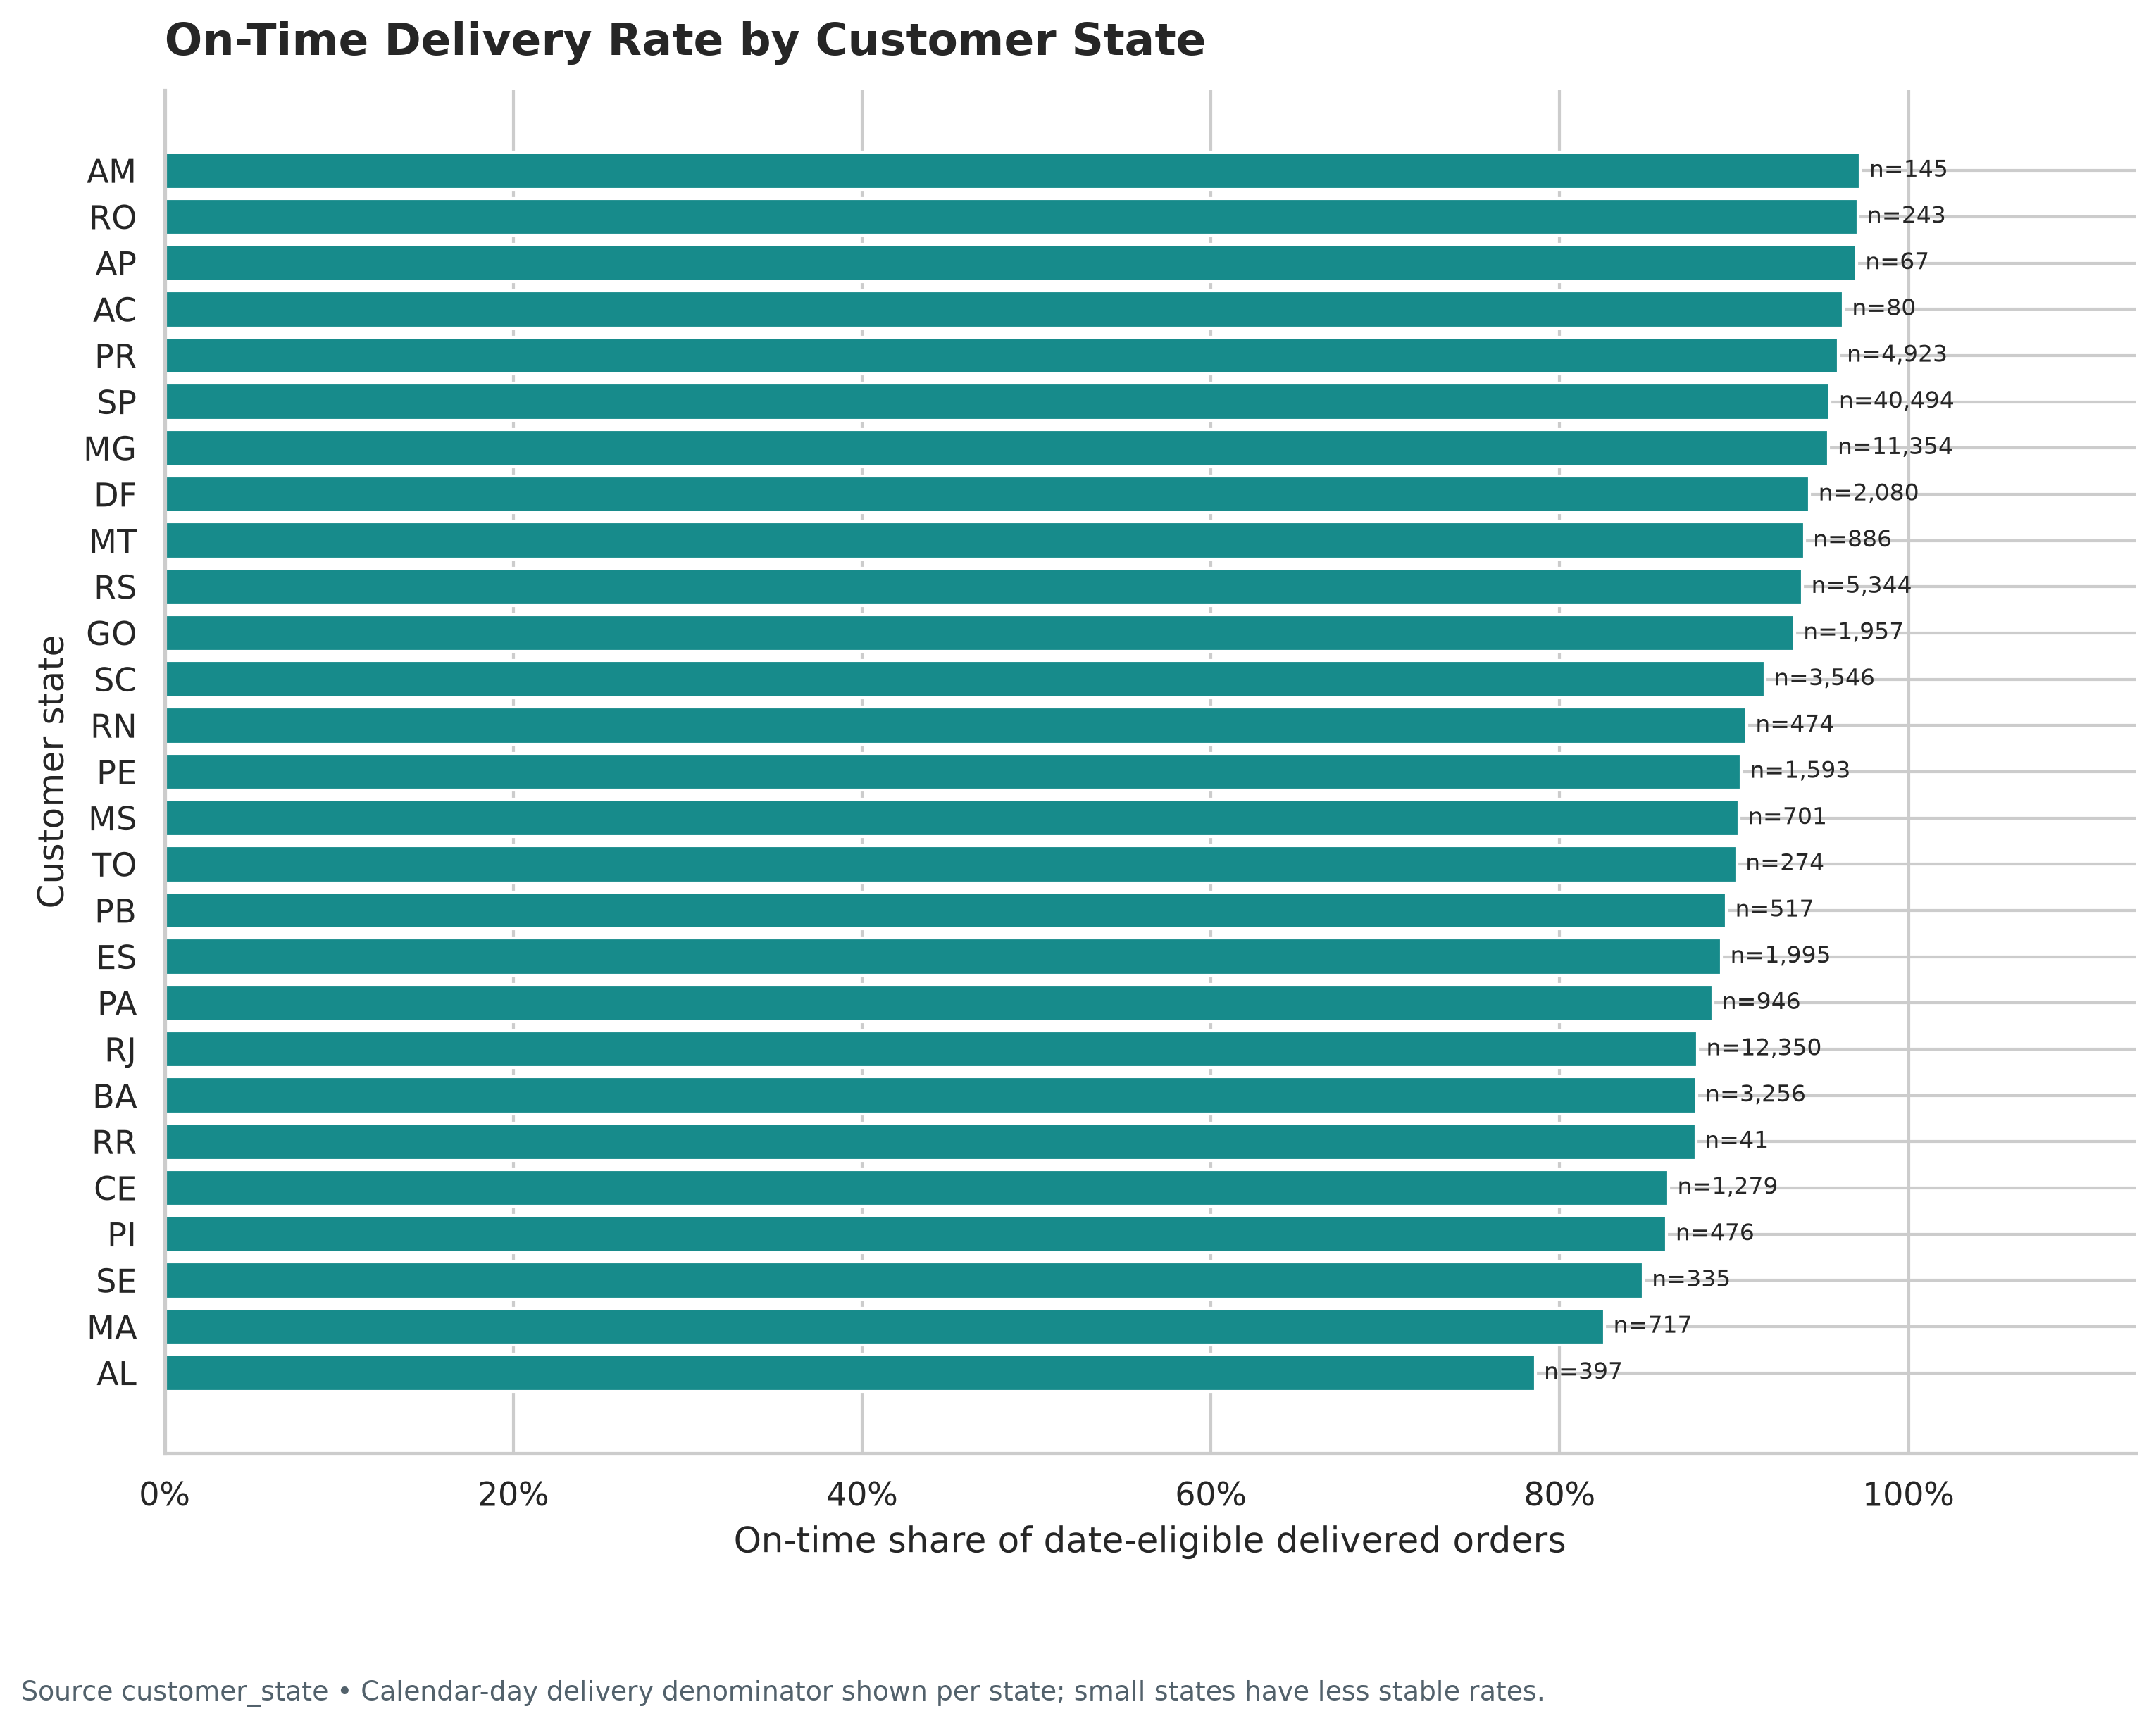

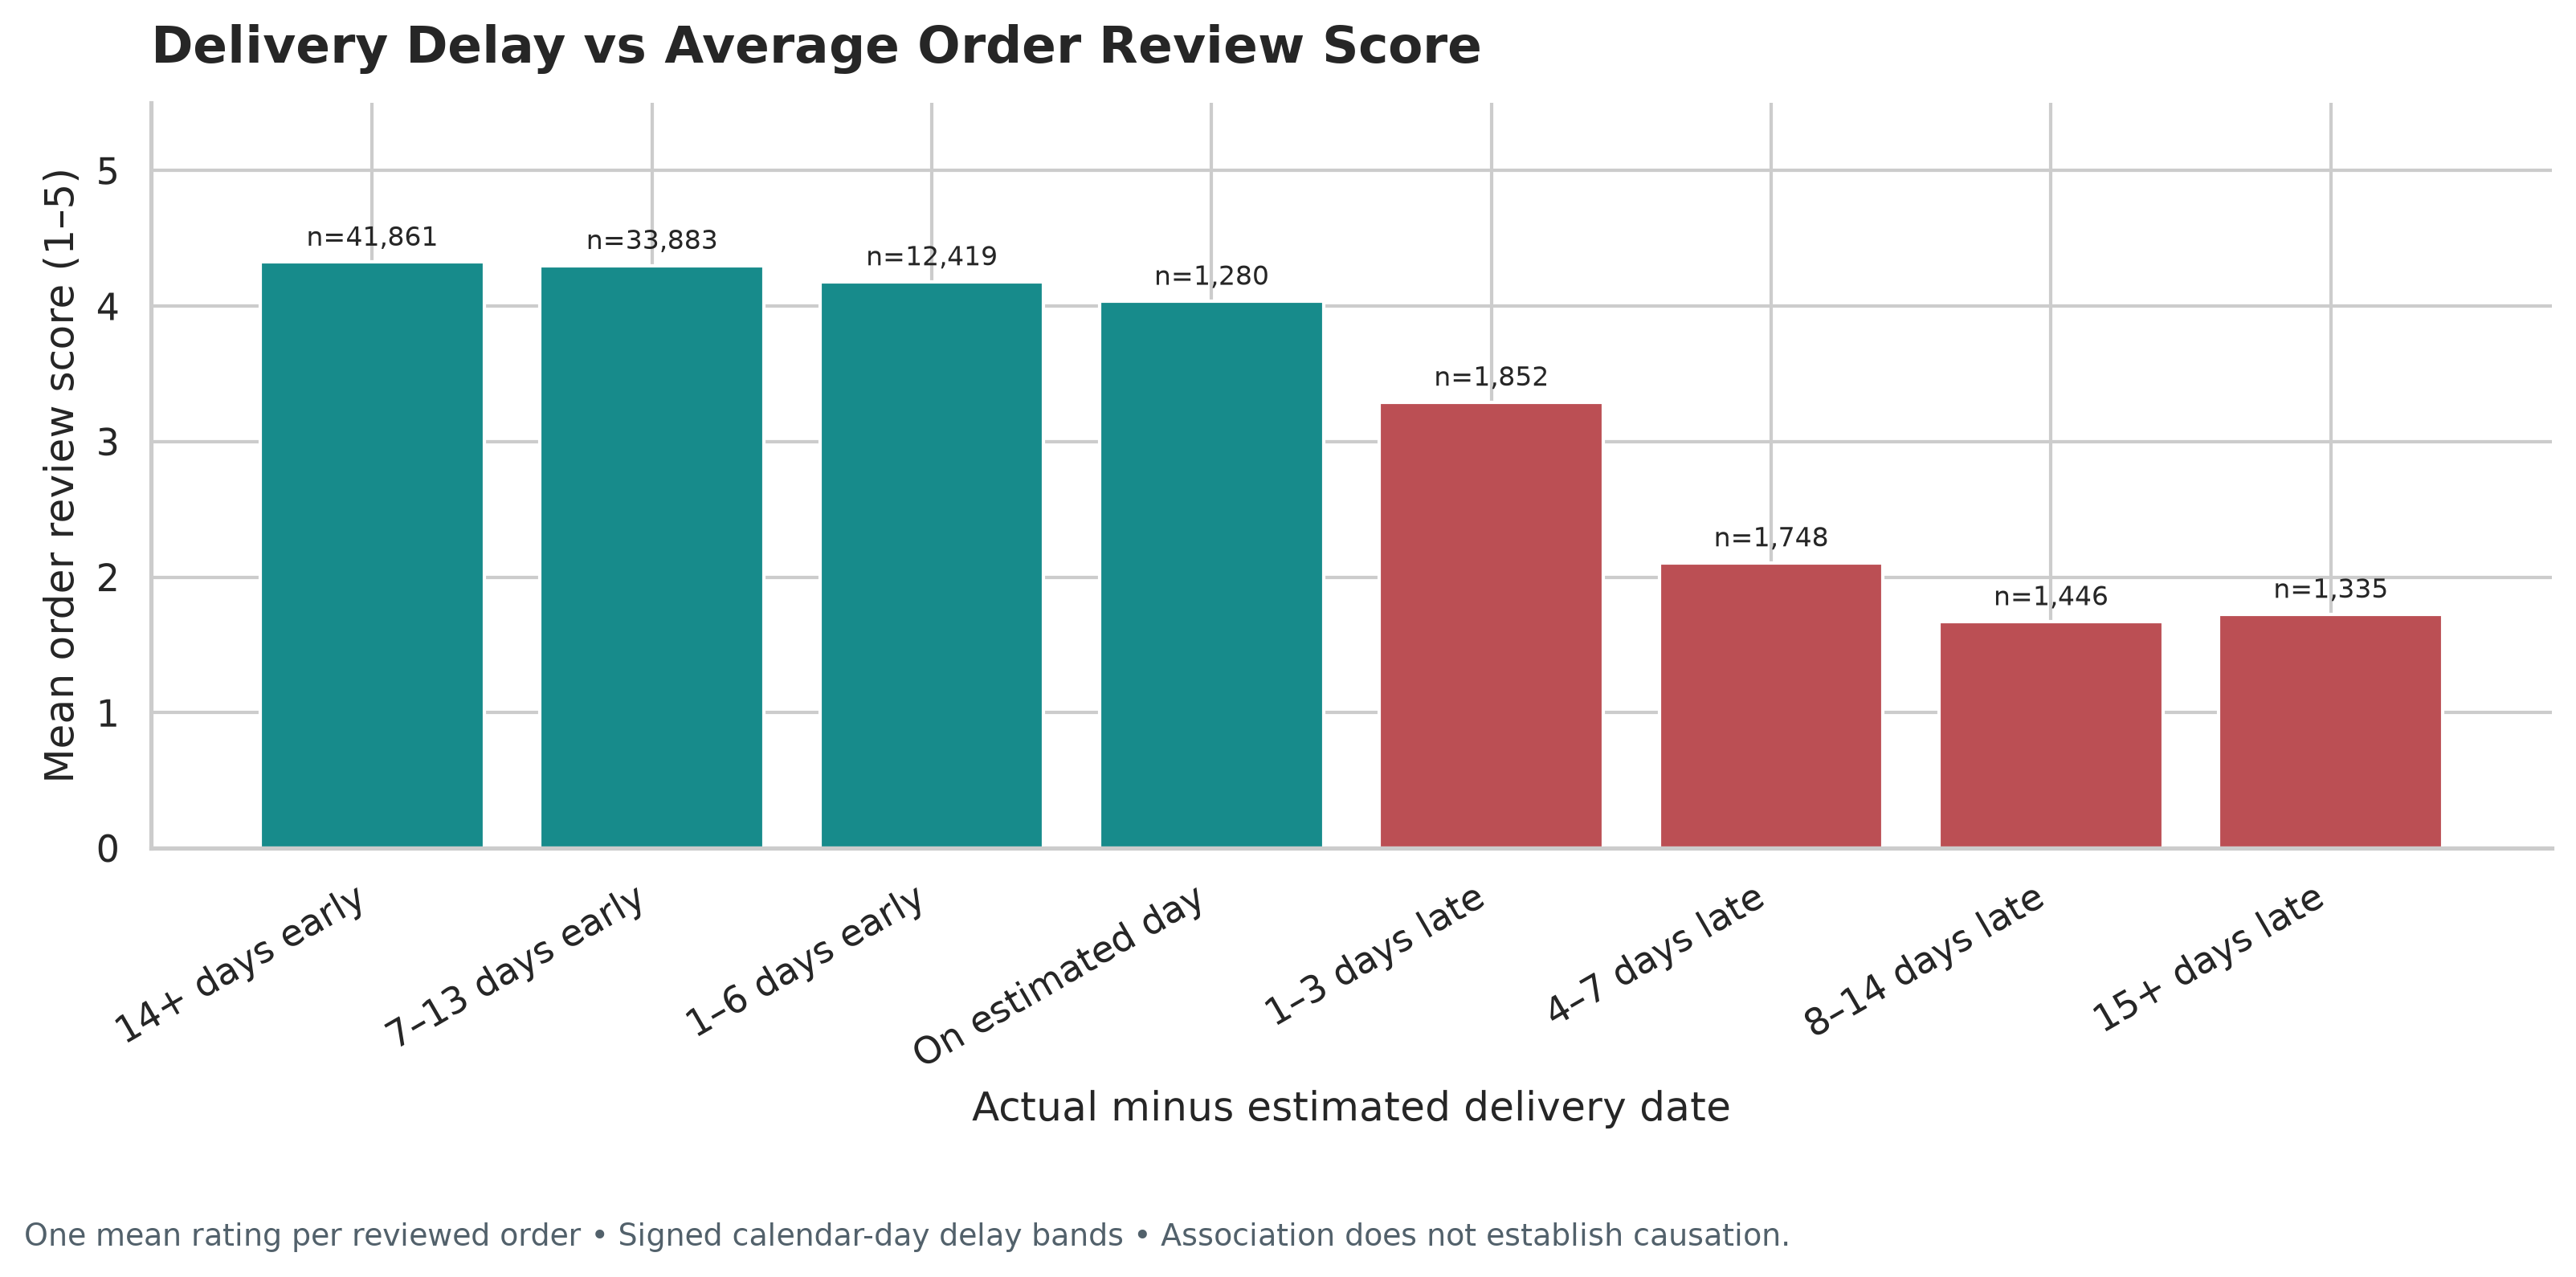

In [8]:
display(analysis["delivery"].round(4))
display(analysis["delay_reviews"].round(4))
canceled_dates = analysis["orders"].loc[analysis["orders"]["order_status"].eq("canceled") & analysis["orders"]["order_delivered_customer_date"].notna()]
print(f"Canceled orders with delivery timestamps, excluded from delivered metrics: {len(canceled_dates)}")
show_figures({"16", "17", "18", "19"})

## 8. Reviews and Customer Satisfaction

The score distribution and headline average use valid `(review_id, order_id)` records associated with the sales cohort. Repeated review IDs remain valid across orders. Coverage is distinct eligible orders with at least one valid score divided by eligible sales orders. Low ratings mean scores 1–2.

For delivery comparisons, average valid reviews within each order first. For category ratings, contribute that mean once per distinct order/category, preventing item-count weighting. Multi-category orders contribute to each relevant category. These are order associations, not product-specific reviews or causal effects.

,analysis_type,group,grain,review_records,reviewed_orders,record_share_pct,average_review_score,eligible_orders,orders_without_valid_review,coverage_pct,average_order_review_score,low_rating_record_pct
0,review_score_distribution,1,review/order record,9406.0,9381,9.7612,1.0000,NaN,NaN,NaN,NaN,NaN
1,review_score_distribution,2,review/order record,2941.0,2938,3.0521,2.0000,NaN,NaN,NaN,NaN,NaN
2,review_score_distribution,3,review/order record,7961.0,7942,8.2616,3.0000,NaN,NaN,NaN,NaN,NaN
3,review_score_distribution,4,review/order record,18987.0,18943,19.7040,4.0000,NaN,NaN,NaN,NaN,NaN
4,review_score_distribution,5,review/order record,57066.0,56817,59.2211,5.0000,NaN,NaN,NaN,NaN,NaN
5,coverage,eligible sales orders,order,96361.0,95832,NaN,4.1557,96478.0,646.0,99.3304,4.1562,12.8133
80,delivery_rating,On time,reviewed order,NaN,89443,NaN,NaN,NaN,NaN,NaN,4.2906,NaN
81,delivery_rating,Late,reviewed order,NaN,6381,NaN,NaN,NaN,NaN,NaN,2.2718,NaN


,category_label,reviewed_order_categories,average_order_review_score
0,health_beauty,8601,4.229489
1,watches_gifts,5454,4.121195
2,bed_bath_table,9177,3.999292
3,sports_leisure,7486,4.227692
4,computers_accessories,6499,4.081243
5,furniture_decor,6260,4.057987
6,housewares,5709,4.19443
7,cool_stuff,3531,4.216936
8,auto,3792,4.145833
9,toys,3774,4.238341


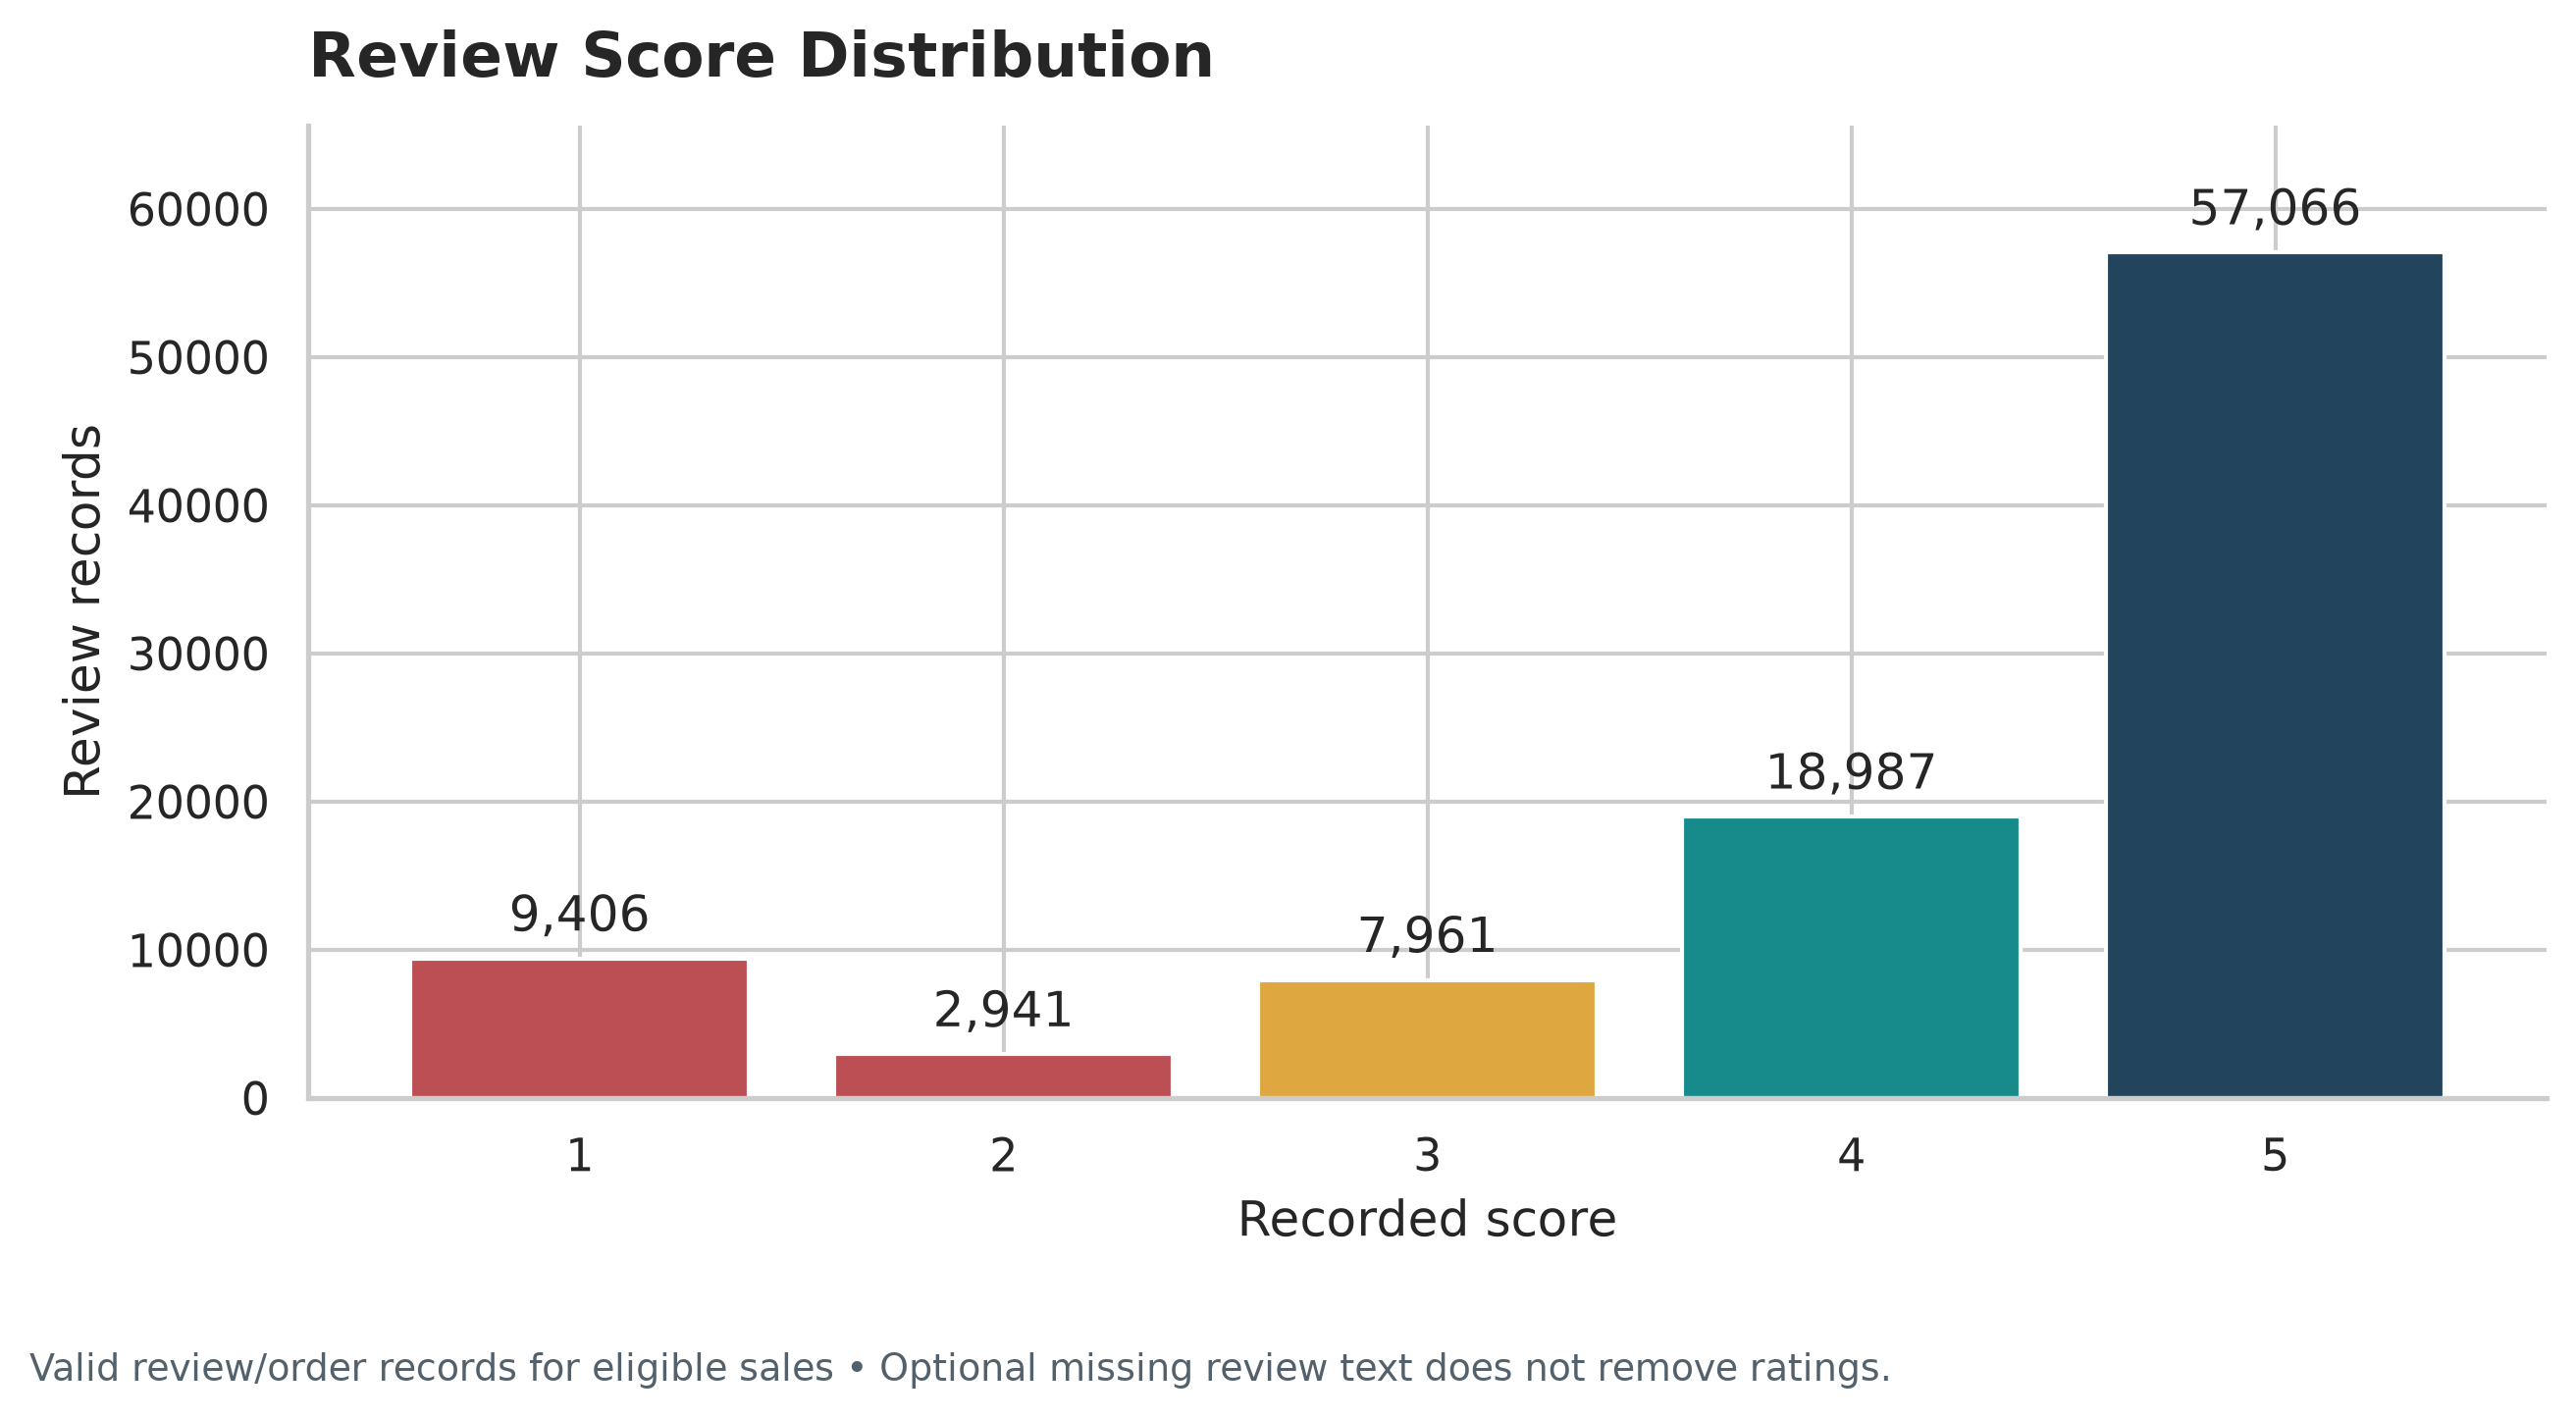

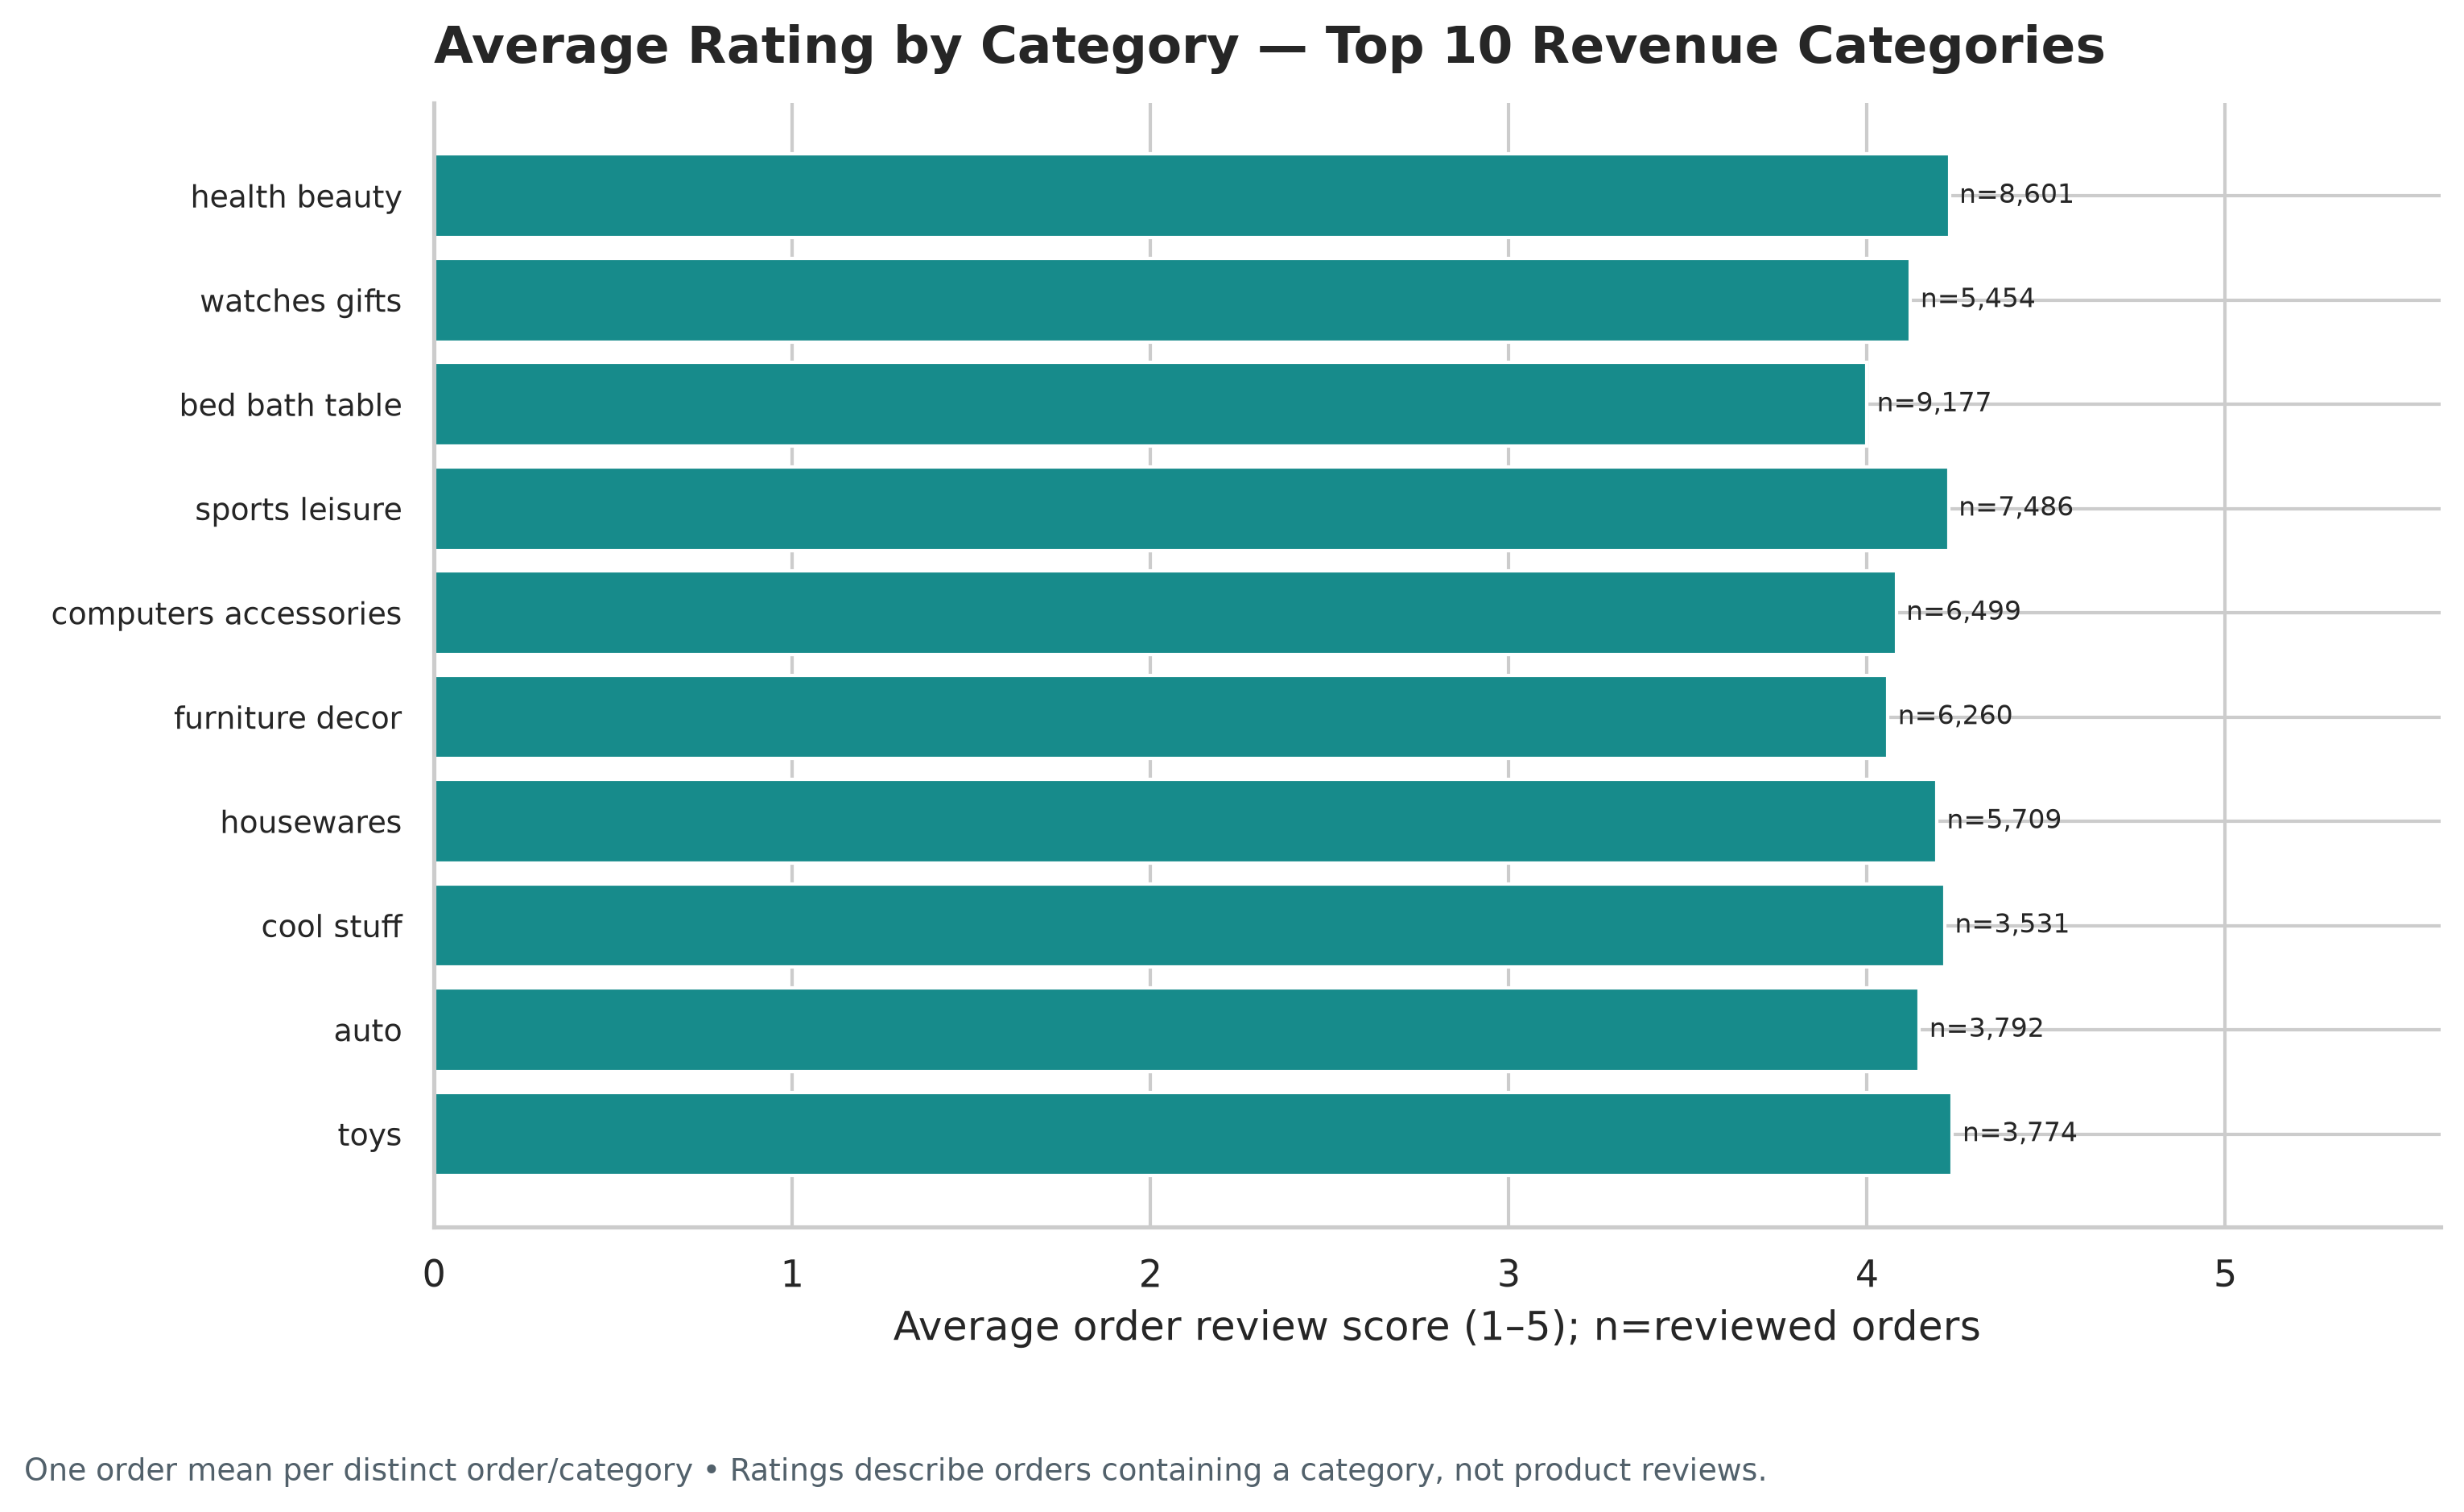

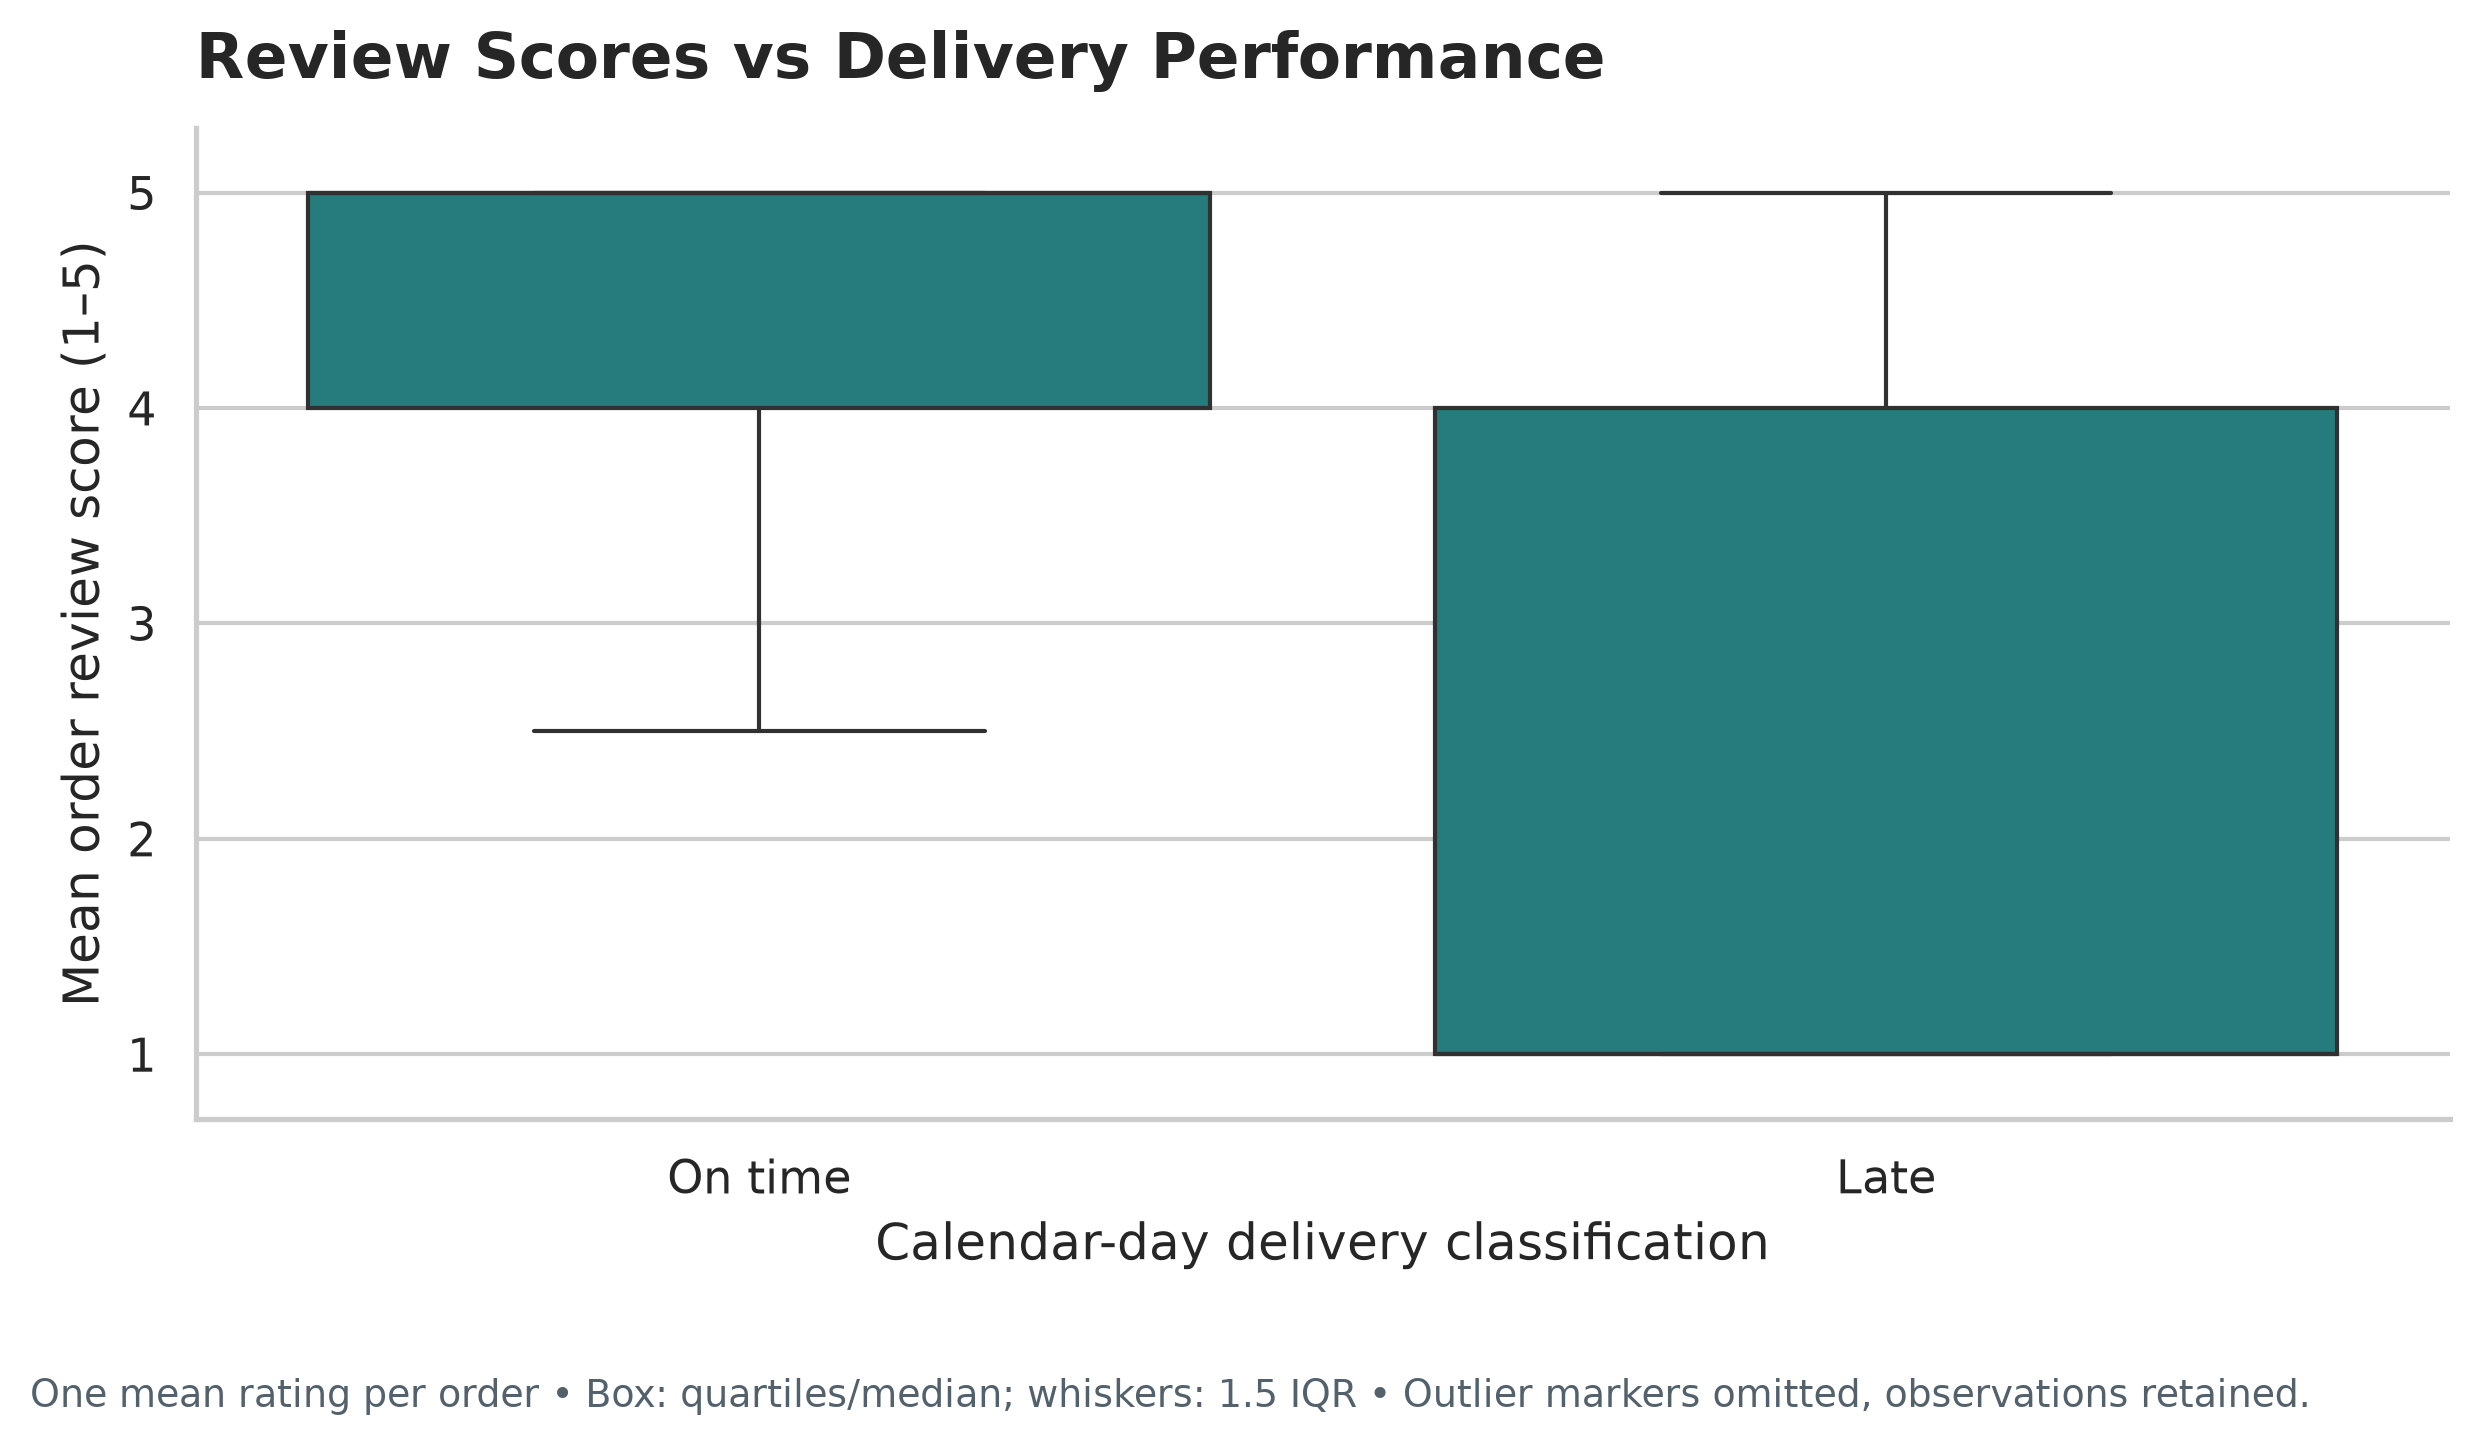

In [9]:
display(analysis["reviews"].loc[analysis["reviews"]["analysis_type"].isin(["coverage", "review_score_distribution", "delivery_rating"])].round(4))
display(analysis["categories"][["category_label", "reviewed_order_categories", "average_order_review_score"]].head(10))
show_figures({"20", "21", "22"})

## 9. Data Quality Impact and Interpretation Limits

Use audited Phase 2 flags to distinguish source limitations from processing errors. Show how many source records are flagged and how many eligible orders they affect. Multiple flags can describe one record; counts are not additive. Direct customer-state analysis retains unmatched-ZIP customers. Geographic ambiguity and unknown timezone provenance remain limitations, not silently repaired facts.

The observation window, delivered-status eligibility and snapshot tail censor behavior. Revenue is not profit; no advertising spend, cart abandonment or verified churn label is inferred. Findings require evidence and an actionable, proportionate next step rather than a causal claim.

In [10]:
display(analysis["impact"])
assert input_hashes(PROJECT_ROOT) == before_hashes, "A raw or processed input was modified."
print("All 19 input CSV hashes are unchanged.")

,dataset,rule,source_flagged_records,eligible_sales_orders_affected
0,orders,no_items,775,0
1,orders,no_payments,1,1
2,orders,no_reviews,768,646
3,orders,missing_order_approved_at,160,14
4,orders,delivered_missing_order_approved_at,14,14
5,orders,missing_order_delivered_carrier_date,1783,2
6,orders,delivered_missing_order_delivered_carrier_date,2,2
7,orders,missing_order_delivered_customer_date,2965,8
8,orders,delivered_missing_order_delivered_customer_date,8,8
9,orders,carrier_before_purchase,166,165


All 19 input CSV hashes are unchanged.


## 10. Export Reports, Run Independent Checks and Summarize

Export seven computed CSV reports and a generated insights report with KPI definitions, evidence, recommendations, limitations and input hashes. The separate tests independently recompute revenue, customers, payments, dates and review attribution directly from the saved cleaned CSVs. They also validate high-resolution figures and input immutability. No data is changed to satisfy tests.

In [11]:
report_names = export_reports(analysis, REPORTS_DIR)
write_insights(analysis, REPORTS_DIR / "phase_3_insights.md", before_hashes, list(figure_paths),
               "Reports and reconciliation assertions generated; the following notebook cell executes independent tests.")
test_result = subprocess.run(
    [sys.executable, "-B", "-m", "pytest", "tests/test_eda.py", "-q", "-p", "no:cacheprovider"],
    cwd=PROJECT_ROOT, capture_output=True, text=True, encoding="utf-8", check=True,
)
print(test_result.stdout)
assert input_hashes(PROJECT_ROOT) == before_hashes
validation_status = test_result.stdout.strip() + "\n\nRevenue, month/category/customer sums and payment totals reconcile in exact cents. Order-grain joins preserve row counts. Delivery/calendar-day and review-grain rules passed independent checks. All 19 raw/processed input hashes remain unchanged."
write_insights(analysis, REPORTS_DIR / "phase_3_insights.md", before_hashes, list(figure_paths), validation_status)
for name in [*report_names, "phase_3_insights.md"]:
    path = REPORTS_DIR / name
    assert path.is_file() and path.stat().st_size > 0
    print(f"Verified report: {path.relative_to(PROJECT_ROOT)} ({path.stat().st_size:,} bytes)")
for path in figure_paths.values():
    assert path.is_file() and path.stat().st_size > 0
print(f"Verified {len(figure_paths)} PNG figures at 300 dpi.")
display(kpis[["kpi", "value", "unit"]].round(4))
print("Phase 3 complete. Stop here; Phase 4 requires approval.")

...............                                                          [100%]
15 passed in 6.80s



Verified report: reports\eda_kpi_summary.csv (3,667 bytes)
Verified report: reports\monthly_sales_summary.csv (4,864 bytes)
Verified report: reports\category_performance.csv (11,311 bytes)
Verified report: reports\customer_analysis_summary.csv (11,837,283 bytes)
Verified report: reports\payment_analysis_summary.csv (11,904 bytes)
Verified report: reports\delivery_performance_summary.csv (6,903 bytes)
Verified report: reports\review_analysis_summary.csv (8,960 bytes)
Verified report: reports\phase_3_insights.md (27,515 bytes)
Verified 22 PNG figures at 300 dpi.


,kpi,value,unit
0,Total Merchandise Revenue,1.322150e+07,BRL
1,Total Orders,9.647800e+04,orders
2,Average Order Value,1.370416e+02,BRL/order
3,Total Unique Customers,9.335800e+04,customers
4,Total Items Sold,1.101970e+05,item records
5,Average Freight Charge,2.278530e+01,BRL/order
6,On-Time Delivery Rate,9.322690e+01,%
7,Average Delivery Duration,1.261850e+01,days
8,Average Review Score,4.155700e+00,score 1–5
9,Repeat Customer Rate,3.000300e+00,%


Phase 3 complete. Stop here; Phase 4 requires approval.
